# Matplotlib

---

# Part 0. 오리엔테이션

## 0.1 Matplotlib이란?

**Matplotlib**은 파이썬의 대표 시각화 라이브러리입니다. 2003년 John Hunter가 MATLAB의 플로팅 기능을 파이썬에서 쓰려고 만들었고, 지금은 파이썬 데이터 분석 생태계의 **표준 그리기 엔진**입니다.

중요한 점: pandas의 `df.plot()`, seaborn, scikit-learn의 시각화 함수가 **내부적으로 전부 Matplotlib을 씁니다**. 그래서 Matplotlib을 알면 다른 라이브러리가 그린 그래프도 마음대로 고칠 수 있습니다.

```
    ┌──────────────┐  ┌──────────┐  ┌─────────┐
    │ pandas.plot  │  │ seaborn  │  │ sklearn │   ← 편한 고수준 도구
    └──────┬───────┘  └────┬─────┘  └────┬────┘
           └───────────────┴─────────────┘
                           │
                   ┌───────▼────────┐
                   │   Matplotlib   │           ← 실제로 그리는 엔진
                   └────────────────┘
```

## 0.2 언제 Matplotlib을 쓰나?

| 상황 | 추천 도구 |
|---|---|
| 빠르게 데이터 훑어보기 | `df.plot()` (pandas) |
| 통계적 관계를 예쁘게 | seaborn |
| 논문·보고서용 정밀 제어 | **Matplotlib** |
| 웹에서 마우스로 조작 | Plotly, Bokeh |
| 남이 만든 그래프 수정 | **Matplotlib** (다른 도구도 결국 이걸로 고침) |

## 0.3 pyplot 모듈

`matplotlib.pyplot`은 MATLAB과 비슷한 명령어 스타일 함수 모음입니다. `plt.plot()`, `plt.title()` 처럼 함수를 순서대로 호출하면 그림이 조금씩 완성됩니다.

입문 단계에서는 편하지만 그래프가 복잡해지면 한계가 옵니다. 그래서 이 교안은 **Part 1에서 pyplot을 배우고 Part 2부터 객체지향으로 전환**합니다. 이 전환이 교안에서 가장 중요한 대목입니다.

---

# Part 1. 시작하기

## 1.1 설치와 import 관례

```bash
pip install matplotlib numpy pandas
```

Colab, Anaconda에는 이미 설치되어 있습니다. import는 아래 세 줄이 **사실상 표준**입니다. 이 관례를 따르지 않으면 남이 쓴 코드를 읽기 어려워집니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print('matplotlib', matplotlib.__version__)
print('numpy     ', np.__version__)
print('pandas    ', pd.__version__)

matplotlib 3.10.0
numpy      2.0.2
pandas     2.2.2


## 1.2 한글 폰트 설정 (가장 먼저 해야 할 일)

Matplotlib 기본 폰트에는 한글이 없습니다. 그냥 그리면 한글이 **네모(□□□)** 로 깨집니다. 강의 첫날 가장 많이 나오는 질문이 이것입니다.

| OS | 폰트 이름 |
|---|---|
| Windows | `Malgun Gothic` (맑은 고딕) |
| macOS | `AppleGothic` |
| Linux / Colab | `NanumBarunGothic` (설치 필요) |

### Colab 사용자: 아래 셀을 먼저 실행하고 **런타임 다시 시작**

In [2]:
# ===== Colab 전용: 주석을 풀고 실행한 뒤 [런타임] > [세션 다시 시작] =====
!sudo apt-get install -y fonts-nanum > /dev/null 2>&1
!sudo fc-cache -fv > /dev/null 2>&1
!rm -rf ~/.cache/matplotlib
print('설치 완료. 런타임을 다시 시작하세요.')

설치 완료. 런타임을 다시 시작하세요.


In [3]:
import platform

def set_korean_font():
    system = platform.system()
    if system == 'Windows':
        family = 'Malgun Gothic'
    elif system == 'Darwin':
        family = 'AppleGothic'
    else:
        family = 'NanumBarunGothic'
    plt.rcParams['font.family'] = family
    # 한글 폰트를 쓰면 마이너스 기호가 깨집니다. 반드시 같이 꺼주세요.
    plt.rcParams['axes.unicode_minus'] = False
    return family

print('적용된 폰트:', set_korean_font())

적용된 폰트: NanumBarunGothic


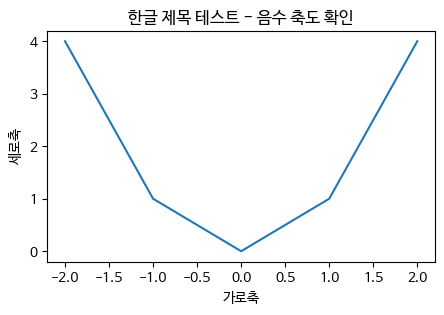

In [4]:
# 한글과 음수가 제대로 나오는지 확인
plt.figure(figsize=(5, 3))
plt.plot([-2, -1, 0, 1, 2], [4, 1, 0, 1, 4])
plt.title('한글 제목 테스트 - 음수 축도 확인')
plt.xlabel('가로축')
plt.ylabel('세로축')
plt.show()

> **문제 해결**
> - 여전히 네모가 나온다 → 런타임/커널을 다시 시작했는지 확인
> - `findfont: Font family not found` 경고 → 폰트 미설치. 아래 셀로 설치된 한글 폰트를 찾아보세요.
> - 마이너스만 네모 → `axes.unicode_minus = False` 를 빠뜨림

In [5]:
# 내 컴퓨터에 설치된 한글 폰트 찾기
from matplotlib import font_manager

keywords = ['Gothic', 'Nanum', 'Malgun', 'Batang', 'Gulim', 'Dotum', 'Apple']
found = sorted({f.name for f in font_manager.fontManager.ttflist
                if any(k in f.name for k in keywords)})
print('후보 폰트:', found[:20])

후보 폰트: ['NanumBarunGothic', 'NanumGothic', 'NanumGothicCoding', 'NanumMyeongjo', 'NanumSquare', 'NanumSquareRound']


## 1.3 첫 그래프 — 리스트 하나만 넘기면?

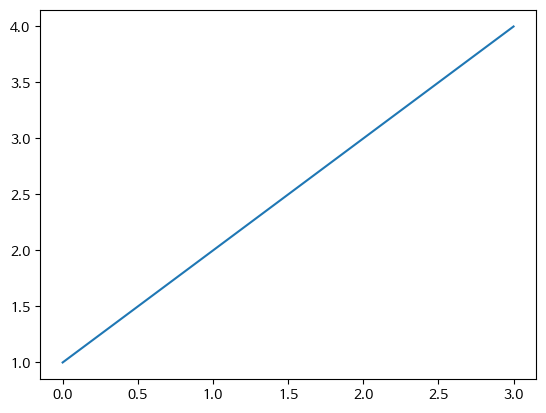

In [6]:
plt.plot([1, 2, 3, 4])
plt.show()

값을 **하나만** 넘기면 Matplotlib은 그것을 **y값**으로 보고 x값은 `0, 1, 2, 3` 처럼 **인덱스를 자동으로** 붙입니다. 그래서 위 그래프의 x축이 0~3입니다.

x를 직접 주려면 두 개를 넘깁니다.

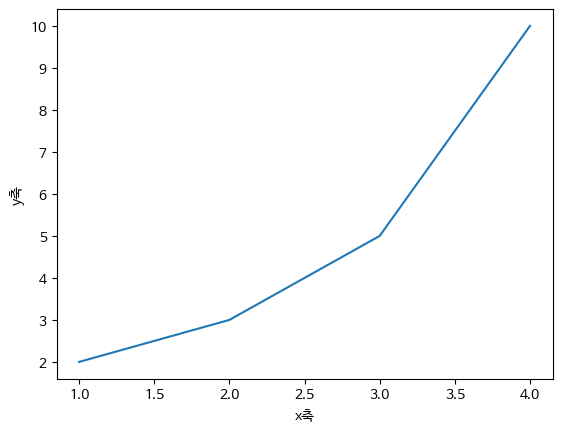

In [7]:
plt.plot([1, 2, 3, 4], [2, 3, 5, 10])   # (x, y) 순서
plt.xlabel('x축')
plt.ylabel('y축')
plt.show()

### `plt.show()` 는 왜 필요한가?

- **스크립트(.py)** 에서는 `plt.show()` 가 있어야 창이 뜹니다. 없으면 아무것도 안 보입니다.
- **주피터/Colab** 에서는 없어도 보이지만, 붙이면 `<matplotlib.lines.Line2D at 0x...>` 같은 지저분한 반환값이 안 나옵니다.

> 습관: **셀 마지막에 항상 `plt.show()`**

## 1.4 Matplotlib의 계층 구조 (여기가 핵심)

대부분의 입문자가 헤매는 이유는 **용어를 모르기 때문**입니다. 구조를 그림으로 잡아두면 이후가 전부 쉬워집니다.

```
┌─────────────────────────────────────────────────┐
│ Figure  (전체 도화지 · 창 · 저장 단위)            │
│                                                 │
│   ┌───────────────────────┐  ┌────────────────┐ │
│   │ Axes (그래프 한 개)    │  │ Axes           │ │
│   │  ├ Axis (x축)         │  │                │ │
│   │  ├ Axis (y축)         │  │                │ │
│   │  ├ Line2D (선)        │  │                │ │
│   │  ├ Text (제목/라벨)    │  │                │ │
│   │  └ Legend (범례)      │  │                │ │
│   └───────────────────────┘  └────────────────┘ │
└─────────────────────────────────────────────────┘
```

| 용어 | 뜻 | 헷갈리는 점 |
|---|---|---|
| **Figure** | 그림 전체. 저장 단위 | 창 하나 = Figure 하나 |
| **Axes** | 그래프 **한 개**. 제목·축·데이터를 가짐 | **축(Axis)이 아니라 그래프 영역!** 가장 많이 헷갈림 |
| **Axis** | x축, y축 그 자체 (눈금·범위 담당) | Axes와 철자만 비슷할 뿐 다른 것 |
| **Artist** | Figure 위에 그려지는 모든 것 | 선, 글자, 사각형 전부 Artist |

> **Axes = 그래프 한 개** 라고 외우세요. 코드에 `ax` 가 나오면 '그래프 하나'를 가리키는 겁니다.

Figure 객체 : <class 'matplotlib.figure.Figure'>
Axes 객체   : <class 'matplotlib.axes._axes.Axes'>
x축(Axis)   : <class 'matplotlib.axis.XAxis'>
그려진 선들 : <Axes.ArtistList of 1 lines>
이 Figure의 Axes 목록: [<Axes: >]


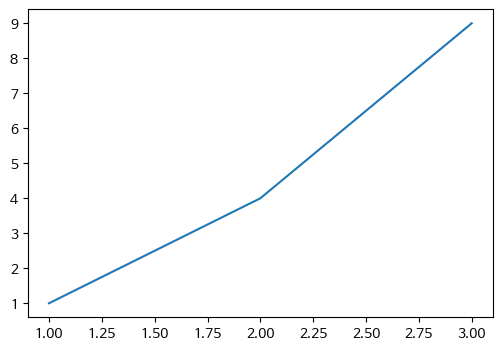

In [8]:
# 구조를 눈으로 확인
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([1, 2, 3], [1, 4, 9])

print('Figure 객체 :', type(fig))
print('Axes 객체   :', type(ax))
print('x축(Axis)   :', type(ax.xaxis))
print('그려진 선들 :', ax.lines)
print('이 Figure의 Axes 목록:', fig.axes)
plt.show()

## 1.5 두 가지 인터페이스 — 이 교안의 분기점

Matplotlib에는 같은 그림을 그리는 **두 가지 방법**이 있습니다. 인터넷 예제가 뒤죽박죽인 이유가 바로 이것입니다.

### 방식 A. pyplot 방식 (암묵적, MATLAB 스타일)

`plt.무언가()` 를 계속 호출합니다. Matplotlib이 **지금 작업 중인 그래프**를 알아서 기억합니다.

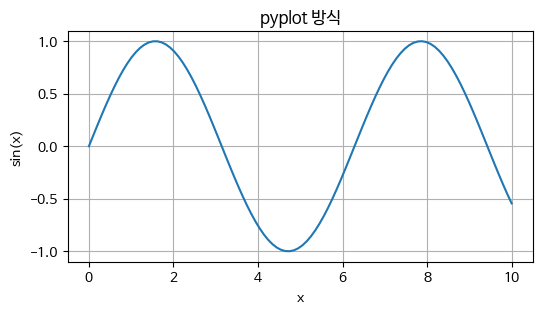

In [9]:
x = np.linspace(0, 10, 100)

plt.figure(figsize=(6, 3))
plt.plot(x, np.sin(x))
plt.title('pyplot 방식')
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.grid(True)
plt.show()

### 방식 B. 객체지향 방식 (명시적, 권장)

`fig`, `ax` 라는 **변수를 받아서** 거기에 명령합니다. 어느 그래프를 건드리는지 코드에 그대로 드러납니다.

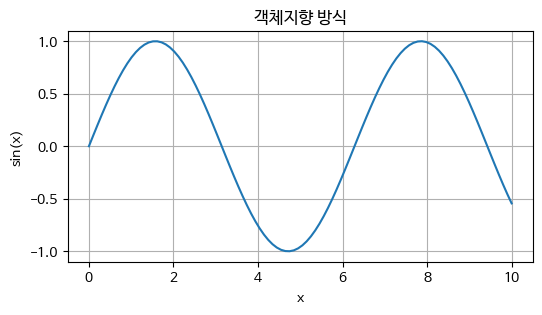

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, np.sin(x))
ax.set_title('객체지향 방식')
ax.set_xlabel('x')
ax.set_ylabel('sin(x)')
ax.grid(True)
plt.show()

### 두 방식 대응표

| pyplot | 객체지향 | 비고 |
|---|---|---|
| `plt.plot(...)` | `ax.plot(...)` | 이름 동일 |
| `plt.title('t')` | `ax.set_title('t')` | **set_** 접두사가 붙음 |
| `plt.xlabel('x')` | `ax.set_xlabel('x')` | |
| `plt.xlim(0, 10)` | `ax.set_xlim(0, 10)` | |
| `plt.xticks([...])` | `ax.set_xticks([...])` | |
| `plt.legend()` | `ax.legend()` | 동일 |
| `plt.grid(True)` | `ax.grid(True)` | 동일 |
| `plt.savefig('a.png')` | `fig.savefig('a.png')` | **fig** 에 붙음 |

> 규칙: **읽는 건 `ax.get_xxx()`, 쓰는 건 `ax.set_xxx()`**

### 왜 객체지향을 권하나?

1. **그래프가 2개 이상이면 pyplot은 금방 무너집니다.** 어느 그래프에 제목을 다는지 알 수 없습니다.
2. **함수로 재사용**할 수 있습니다. `def draw(ax, data): ax.plot(...)` 처럼 짜면 어디든 붙일 수 있습니다.
3. **seaborn, pandas가 `ax=` 인자를 받습니다.** 다른 라이브러리 그래프를 고치려면 `ax`를 다룰 줄 알아야 합니다.
4. 공식 문서가 객체지향을 권장합니다.

> 이 교안은 **Part 2부터 전부 객체지향**으로 갑니다. pyplot 예제를 보면 머릿속으로 `ax.set_` 로 번역하는 연습을 하세요.

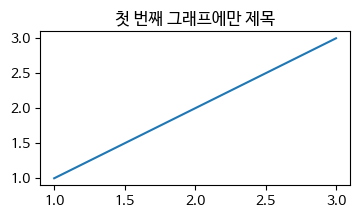

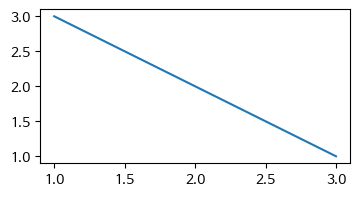

In [11]:
# pyplot이 무너지는 순간
# 그래프 2개를 만들고 첫 번째에만 제목을 달고 싶다면?
fig1, ax1 = plt.subplots(figsize=(4, 2))
fig2, ax2 = plt.subplots(figsize=(4, 2))

ax1.plot([1, 2, 3], [1, 2, 3])
ax2.plot([1, 2, 3], [3, 2, 1])

ax1.set_title('첫 번째 그래프에만 제목')   # 명확함
# plt.title(...) 이었다면 마지막에 만든 fig2에 붙습니다. 의도와 다름.
plt.show()

---

# Part 2. 객체지향 API 제대로 쓰기

## 2.1 모든 것은 `plt.subplots()` 에서 시작한다

```python
fig, ax = plt.subplots()
```

이 한 줄이 **Figure 하나와 Axes 하나를 동시에 만들어** 돌려줍니다. 앞으로 그래프를 그릴 때는 거의 항상 이 줄로 시작합니다.

| 인자 | 뜻 | 예 |
|---|---|---|
| `nrows`, `ncols` | 몇 행 몇 열로 | `plt.subplots(2, 3)` |
| `figsize` | (가로, 세로) 인치 | `figsize=(10, 4)` |
| `dpi` | 해상도 (인치당 픽셀) | `dpi=100` |
| `sharex`, `sharey` | 축 공유 | `sharey=True` |
| `constrained_layout` | 겹침 자동 정리 | `constrained_layout=True` |

> 실제 픽셀 크기 = `figsize × dpi`. `figsize=(8, 4), dpi=100` → 800×400 픽셀.

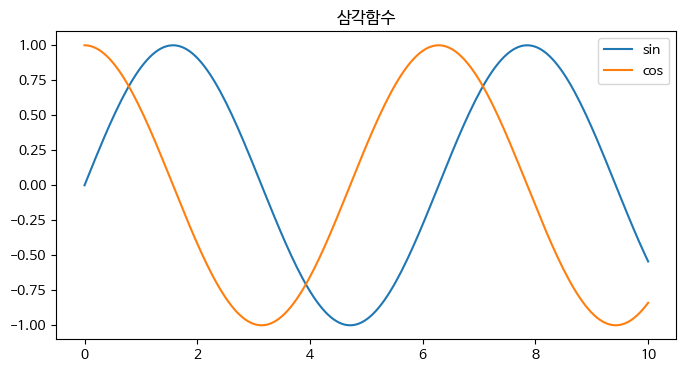

Figure 크기(인치): [8. 4.]
해상도(dpi)     : 100


In [12]:
x = np.linspace(0, 10, 200)

fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
ax.plot(x, np.sin(x), label='sin')
ax.plot(x, np.cos(x), label='cos')
ax.set_title('삼각함수')
ax.legend()
plt.show()

print('Figure 크기(인치):', fig.get_size_inches())
print('해상도(dpi)     :', fig.get_dpi())

## 2.2 fig와 ax의 역할 분담

| 대상 | 담당 | 대표 메서드 |
|---|---|---|
| **fig** | 그림 전체 | `fig.suptitle()`, `fig.savefig()`, `fig.tight_layout()`, `fig.set_size_inches()` |
| **ax** | 그래프 하나 | `ax.plot()`, `ax.set_title()`, `ax.set_xlim()`, `ax.legend()`, `ax.grid()` |

> 헷갈릴 때: **저장·전체 제목·레이아웃은 `fig`**, 나머지는 전부 `ax`.

## 2.3 `ax.set()` 으로 한 번에 설정하기

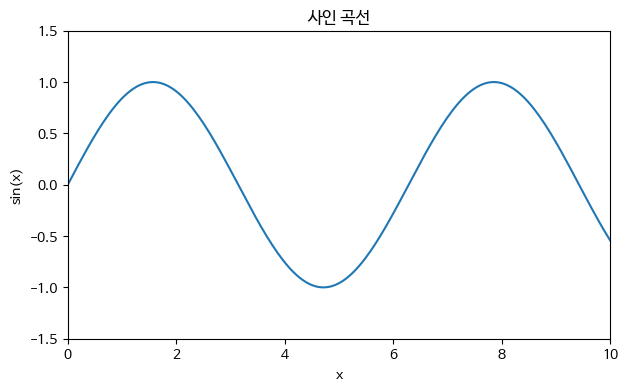

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, np.sin(x))

# 길게 쓰는 방법
# ax.set_title('사인 곡선')
# ax.set_xlabel('x')
# ax.set_ylabel('sin(x)')
# ax.set_xlim(0, 10)
# ax.set_ylim(-1.5, 1.5)

# 한 줄로 (권장)
ax.set(title='사인 곡선', xlabel='x', ylabel='sin(x)',
       xlim=(0, 10), ylim=(-1.5, 1.5))
plt.show()

## 2.4 Axes가 여러 개일 때

`plt.subplots(2, 2)` 는 `ax` 대신 **넘파이 배열**을 돌려줍니다. 인덱싱으로 접근합니다.

axes의 타입 : <class 'numpy.ndarray'>
axes의 모양 : (2, 2)


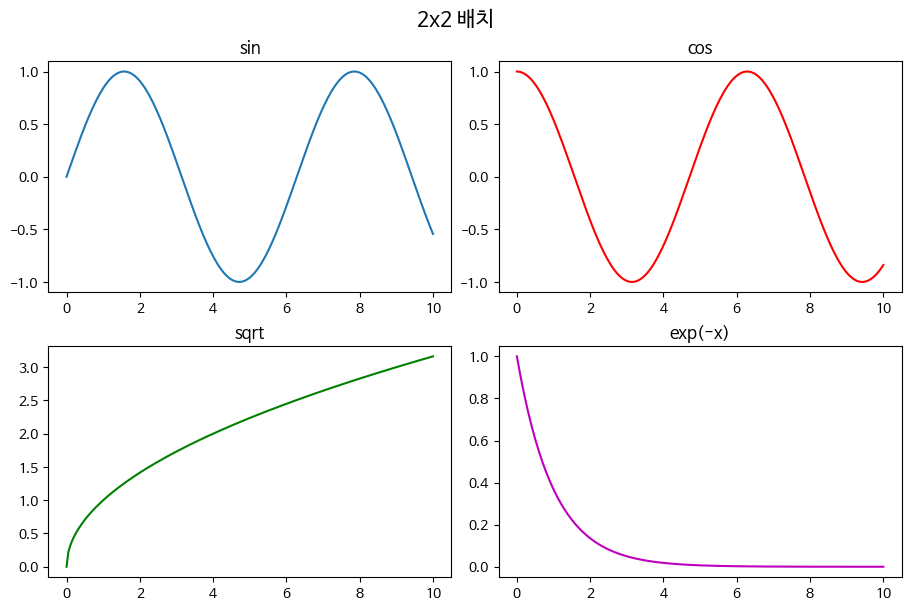

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), constrained_layout=True)

print('axes의 타입 :', type(axes))
print('axes의 모양 :', axes.shape)

axes[0, 0].plot(x, np.sin(x));       axes[0, 0].set_title('sin')
axes[0, 1].plot(x, np.cos(x), 'r');  axes[0, 1].set_title('cos')
axes[1, 0].plot(x, x ** 0.5, 'g');   axes[1, 0].set_title('sqrt')
axes[1, 1].plot(x, np.exp(-x), 'm'); axes[1, 1].set_title('exp(-x)')

fig.suptitle('2x2 배치', fontsize=15)
plt.show()

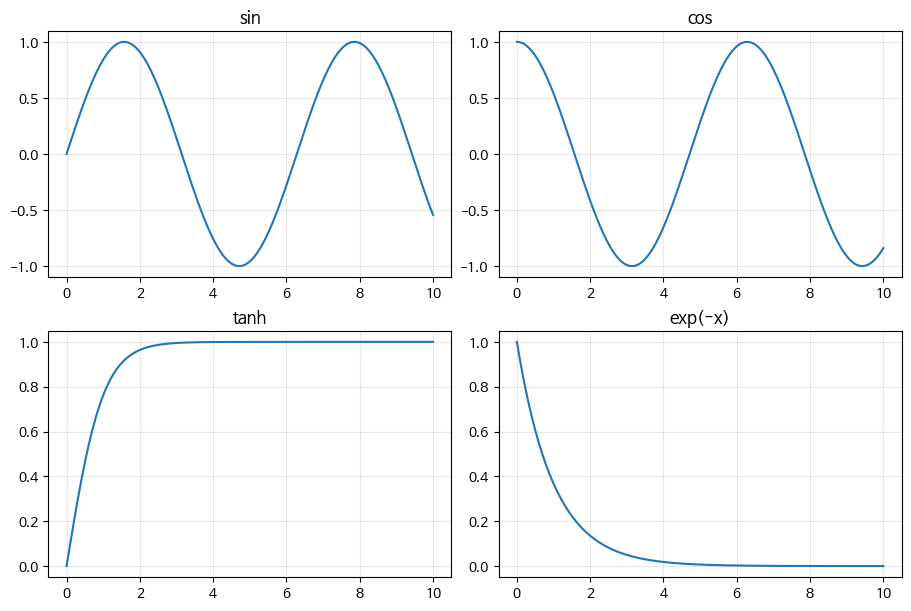

In [15]:
# 반복문으로 처리할 때는 flatten()이 편합니다
funcs = [('sin', np.sin), ('cos', np.cos), ('tanh', np.tanh),
         ('exp(-x)', lambda v: np.exp(-v))]

fig, axes = plt.subplots(2, 2, figsize=(9, 6), constrained_layout=True)
for ax, (name, f) in zip(axes.flatten(), funcs):
    ax.plot(x, f(x))
    ax.set_title(name)
    ax.grid(alpha=0.3)
plt.show()

## 2.5 그래프 그리는 함수 만들기

객체지향의 진짜 위력은 **`ax`를 인자로 받는 함수**를 만들 수 있다는 점입니다. 같은 그래프를 어디든 다시 그릴 수 있습니다.

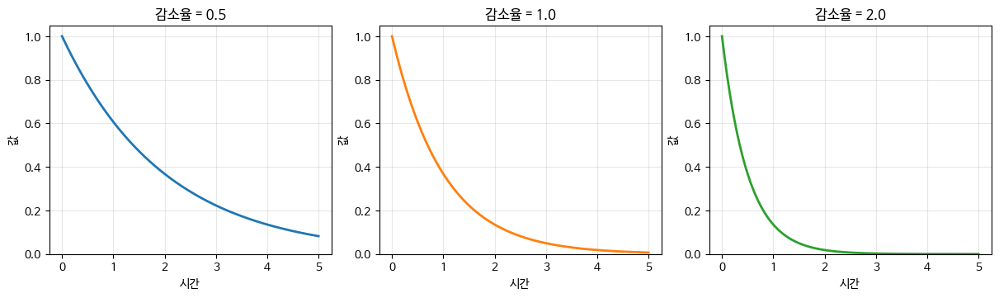

In [16]:
def draw_decay(ax, rate, color):
    '''주어진 ax에 지수 감소 곡선을 그립니다.'''
    tt = np.linspace(0, 5, 200)
    ax.plot(tt, np.exp(-rate * tt), color=color, lw=2)
    ax.set(title=f'감소율 = {rate}', xlabel='시간', ylabel='값', ylim=(0, 1.05))
    ax.grid(alpha=0.3)
    return ax

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, r, c in zip(axes, [0.5, 1.0, 2.0], ['tab:blue', 'tab:orange', 'tab:green']):
    draw_decay(ax, r, c)
plt.show()

---

# Part 3. 선 그래프 스타일링

선 그래프 하나를 완벽히 제어할 수 있으면 나머지 차트는 응용일 뿐입니다. 이 Part가 교안에서 가장 깁니다.

## 3.1 여러 데이터를 한 그래프에

`ax.plot()` 을 여러 번 호출하면 같은 Axes에 겹쳐 그려집니다.

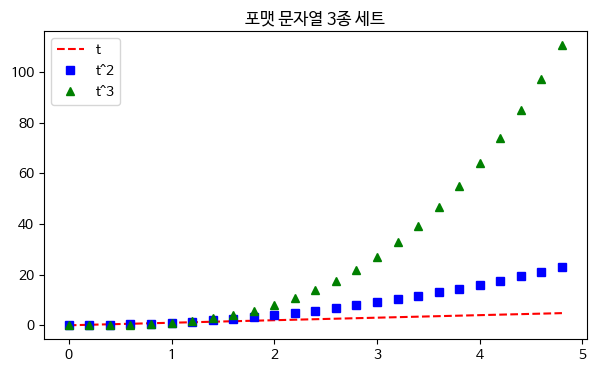

In [17]:
t = np.arange(0., 5., 0.2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, t,     'r--', label='t')      # 빨간 대시
ax.plot(t, t**2,  'bs',  label='t^2')    # 파란 사각형
ax.plot(t, t**3,  'g^',  label='t^3')    # 녹색 삼각형
ax.legend()
ax.set_title('포맷 문자열 3종 세트')
plt.show()

## 3.2 `data=` 인자로 딕셔너리·데이터프레임 쓰기

데이터가 딕셔너리나 DataFrame에 있으면 **키 이름만으로** 그릴 수 있습니다.

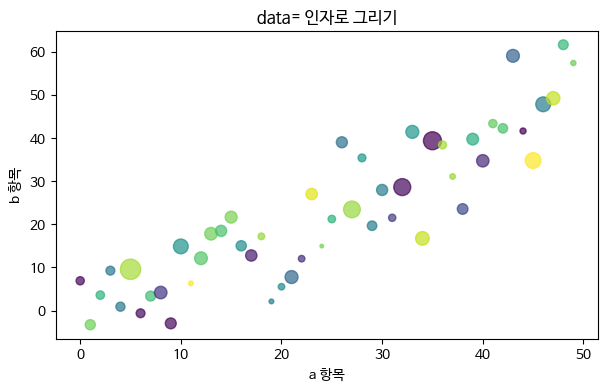

In [18]:
rng = np.random.default_rng(42)
data = {
    'a': np.arange(50),
    'c': rng.integers(0, 50, 50),
    'd': np.abs(rng.standard_normal(50)) * 100,
}
data['b'] = data['a'] + 10 * rng.standard_normal(50)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter('a', 'b', c='c', s='d', data=data, alpha=0.7, cmap='viridis')
ax.set(xlabel='a 항목', ylabel='b 항목', title='data= 인자로 그리기')
plt.show()

## 3.3 선 종류 (linestyle)

| 문자열 | 축약 | 모양 |
|---|---|---|
| `'solid'` | `'-'` | 실선 |
| `'dashed'` | `'--'` | 대시 |
| `'dotted'` | `':'` | 점선 |
| `'dashdot'` | `'-.'` | 일점쇄선 |
| `(0, (5, 2, 1, 2))` | | 직접 지정 (켬5, 끔2, 켬1, 끔2) |

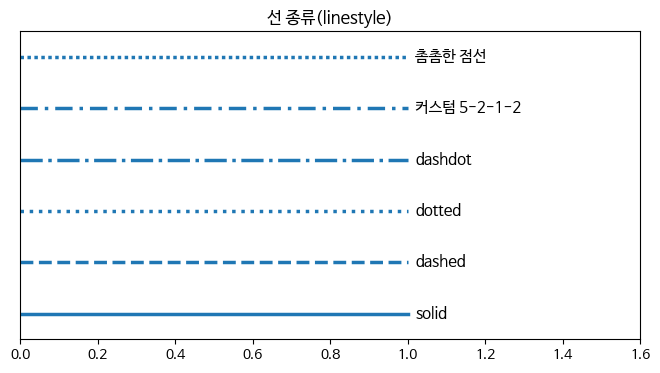

In [19]:
styles = ['-', '--', ':', '-.', (0, (5, 2, 1, 2)), (0, (1, 1))]
names  = ['solid', 'dashed', 'dotted', 'dashdot', '커스텀 5-2-1-2', '촘촘한 점선']

fig, ax = plt.subplots(figsize=(8, 4))
for i, (s, n) in enumerate(zip(styles, names)):
    ax.plot([0, 1], [i, i], linestyle=s, lw=2.5, color='tab:blue')
    ax.text(1.02, i, n, va='center', fontsize=11)
ax.set(xlim=(0, 1.6), ylim=(-0.5, len(styles) - 0.5), title='선 종류(linestyle)')
ax.set_yticks([])
plt.show()

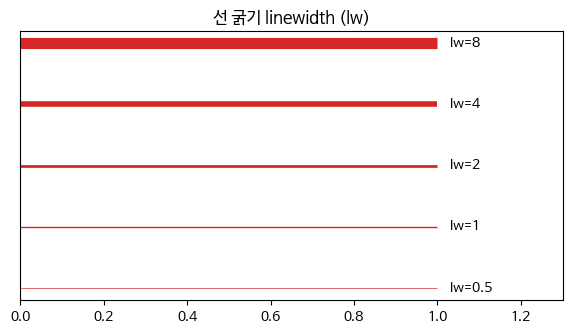

In [20]:
# 선 굵기
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, lw in enumerate([0.5, 1, 2, 4, 8]):
    ax.plot([0, 1], [i, i], lw=lw, solid_capstyle='butt', color='tab:red')
    ax.text(1.03, i, f'lw={lw}', va='center')
ax.set(xlim=(0, 1.3), title='선 굵기 linewidth (lw)')
ax.set_yticks([])
plt.show()

## 3.4 마커 (marker)

데이터 **점**을 표시하는 기호입니다. 관측값이 몇 개인지 보여주고 싶을 때 씁니다.

| 마커 | 모양 | 마커 | 모양 |
|---|---|---|---|
| `'.'` | 점 | `'s'` | 사각형 |
| `'o'` | 원 | `'D'` | 다이아몬드 |
| `'v' '^' '<' '>'` | 삼각형 4방향 | `'*'` | 별 |
| `'+'` | 플러스 | `'x'` | 엑스 |
| `'1' '2' '3' '4'` | 삼각뿔 | `'p' 'h' 'H'` | 오각형/육각형 |

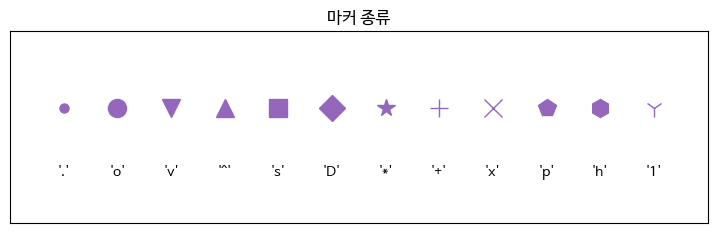

In [21]:
markers = ['.', 'o', 'v', '^', 's', 'D', '*', '+', 'x', 'p', 'h', '1']

fig, ax = plt.subplots(figsize=(9, 2.5))
for i, m in enumerate(markers):
    ax.plot(i, 0, marker=m, markersize=13, color='tab:purple')
    ax.text(i, -0.35, repr(m), ha='center', fontsize=10)
ax.set(xlim=(-1, len(markers)), ylim=(-0.6, 0.4), title='마커 종류')
ax.set_xticks([]); ax.set_yticks([])
plt.show()

### 포맷 문자열 — 색 + 마커 + 선을 한 번에

`'bo--'` 처럼 **[색][마커][선]** 순서로 붙여 씁니다. 빠르지만 표현력이 낮아 정식 코드에서는 키워드 인자를 권합니다.

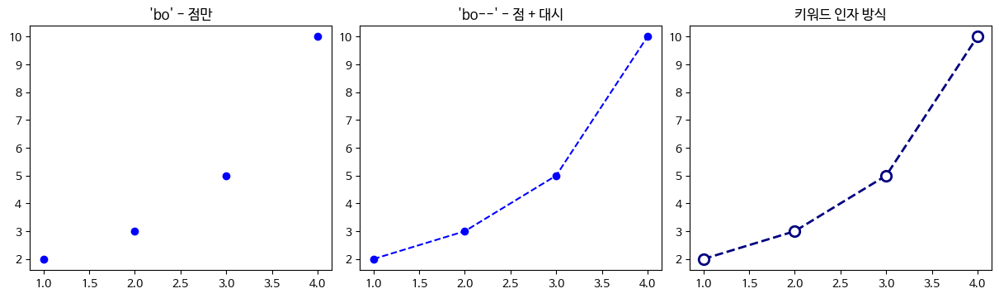

In [22]:
y = [2, 3, 5, 10]
xs = [1, 2, 3, 4]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)

axes[0].plot(xs, y, 'bo')
axes[0].set_title("'bo' - 점만")

axes[1].plot(xs, y, 'bo--')
axes[1].set_title("'bo--' - 점 + 대시")

# 키워드 인자 방식 (권장)
axes[2].plot(xs, y, color='navy', marker='o', markersize=9,
             markerfacecolor='white', markeredgewidth=2,
             linestyle='--', linewidth=2)
axes[2].set_title('키워드 인자 방식')
plt.show()

### 마커 관련 인자

| 인자 | 축약 | 뜻 |
|---|---|---|
| `markersize` | `ms` | 마커 크기 |
| `markerfacecolor` | `mfc` | 마커 내부 색 |
| `markeredgecolor` | `mec` | 마커 테두리 색 |
| `markeredgewidth` | `mew` | 마커 테두리 굵기 |
| `markevery` | | 몇 개마다 마커를 찍을지 |

> 데이터가 많을 때 모든 점에 마커를 찍으면 뭉개집니다. `markevery=20` 처럼 솎아내세요.

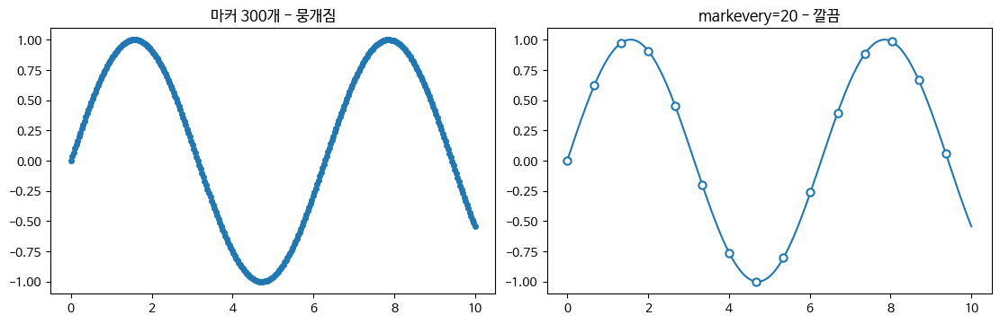

In [23]:
xx = np.linspace(0, 10, 300)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].plot(xx, np.sin(xx), marker='o', ms=4)
axes[0].set_title('마커 300개 - 뭉개짐')

axes[1].plot(xx, np.sin(xx), marker='o', ms=6, markevery=20, mfc='white', mew=1.5)
axes[1].set_title('markevery=20 - 깔끔')
plt.show()

## 3.5 색 지정하기 — 6가지 방법

| 방법 | 예시 | 설명 |
|---|---|---|
| 단축 문자 | `'r' 'g' 'b' 'c' 'm' 'y' 'k' 'w'` | 8가지뿐. 빠른 확인용 |
| 이름 | `'skyblue' 'tomato' 'forestgreen'` | CSS 색 이름 약 150개 |
| **탭 색상** | `'tab:blue' 'tab:orange' ...` | **기본 팔레트. 실무 추천** |
| 순환 참조 | `'C0' 'C1' ... 'C9'` | 현재 컬러 사이클의 n번째 |
| HEX | `'#e35f62'` | 정확한 색 지정 |
| RGB(A) 튜플 | `(0.1, 0.2, 0.5)`, `(0.1, 0.2, 0.5, 0.3)` | 0~1 범위. 4번째는 투명도 |

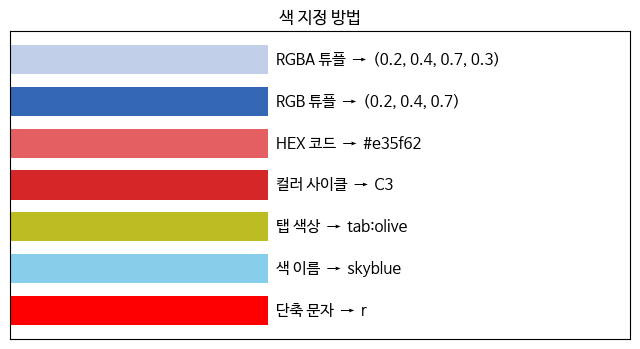

In [24]:
color_specs = [
    ('단축 문자', 'r'),
    ('색 이름', 'skyblue'),
    ('탭 색상', 'tab:olive'),
    ('컬러 사이클', 'C3'),
    ('HEX 코드', '#e35f62'),
    ('RGB 튜플', (0.2, 0.4, 0.7)),
    ('RGBA 튜플', (0.2, 0.4, 0.7, 0.3)),
]

fig, ax = plt.subplots(figsize=(8, 4))
for i, (label, c) in enumerate(color_specs):
    ax.barh(i, 1, color=c, height=0.7)
    ax.text(1.03, i, f'{label}  →  {c}', va='center', fontsize=11)
ax.set(xlim=(0, 2.4), title='색 지정 방법')
ax.set_yticks([]); ax.set_xticks([])
plt.show()

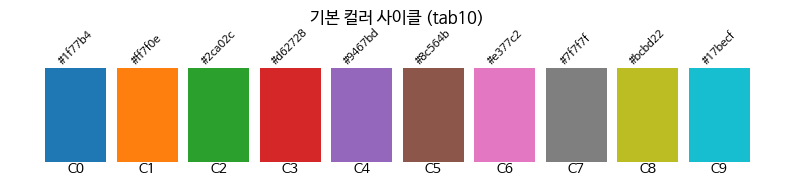

In [25]:
# 기본 컬러 사이클 (tab10) — 구분이 잘 되도록 설계된 색이니 특별한 이유가 없으면 그대로 쓰세요
cycle_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize=(10, 2))
for i, c in enumerate(cycle_colors):
    ax.bar(i, 1, color=c, width=0.85)
    ax.text(i, -0.12, f'C{i}', ha='center', fontsize=10)
    ax.text(i, 1.05, c, ha='center', fontsize=8, rotation=45)
ax.set(ylim=(-0.25, 1.4), title='기본 컬러 사이클 (tab10)')
ax.axis('off')
plt.show()

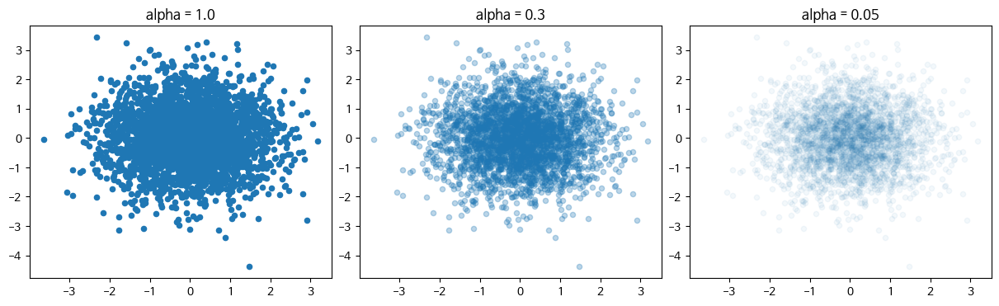

In [26]:
# alpha — 투명도. 점이 겹칠 때 필수
pts = rng.standard_normal((2, 3000))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, a in zip(axes, [1.0, 0.3, 0.05]):
    ax.scatter(pts[0], pts[1], s=20, alpha=a, color='tab:blue')
    ax.set_title(f'alpha = {a}')
plt.show()

## 3.6 범례 (legend)

선이 2개 이상이면 범례는 **필수**입니다.

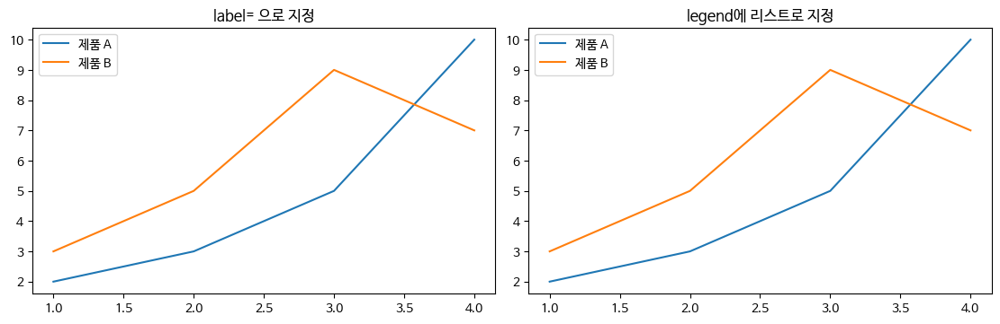

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)

# 방법 1: plot에서 label= 지정 (권장)
axes[0].plot(xs, [2, 3, 5, 10], label='제품 A')
axes[0].plot(xs, [3, 5, 9, 7],  label='제품 B')
axes[0].legend()
axes[0].set_title('label= 으로 지정')

# 방법 2: legend에 리스트로 (순서 실수 위험)
axes[1].plot(xs, [2, 3, 5, 10])
axes[1].plot(xs, [3, 5, 9, 7])
axes[1].legend(['제품 A', '제품 B'])
axes[1].set_title('legend에 리스트로 지정')
plt.show()

### 범례 위치 (`loc`)

```
 'upper left'    'upper center'    'upper right'
 'center left'      'center'       'center right'
 'lower left'    'lower center'    'lower right'
```

- `'best'` : 데이터를 가리지 않는 곳을 알아서 고름 (기본값)
- `(0.5, 0.5)` : Axes 기준 좌표 (0~1). 왼쪽 아래가 (0,0)
- `bbox_to_anchor=(1.02, 1)` + `loc='upper left'` : **그래프 바깥**으로 빼기

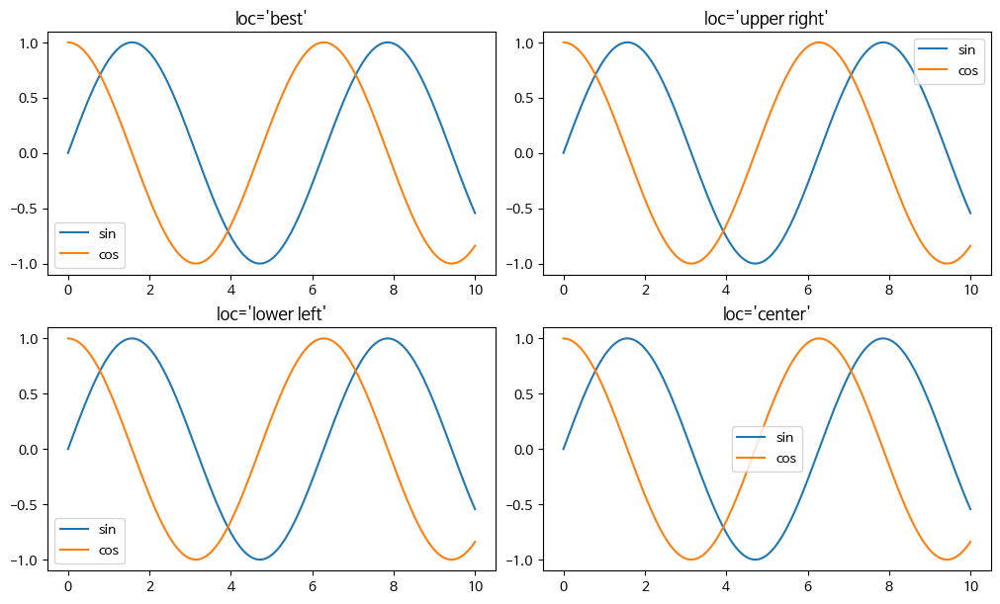

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
for ax, loc in zip(axes.flatten(), ['best', 'upper right', 'lower left', 'center']):
    ax.plot(x, np.sin(x), label='sin')
    ax.plot(x, np.cos(x), label='cos')
    ax.legend(loc=loc)
    ax.set_title(f"loc='{loc}'")
plt.show()

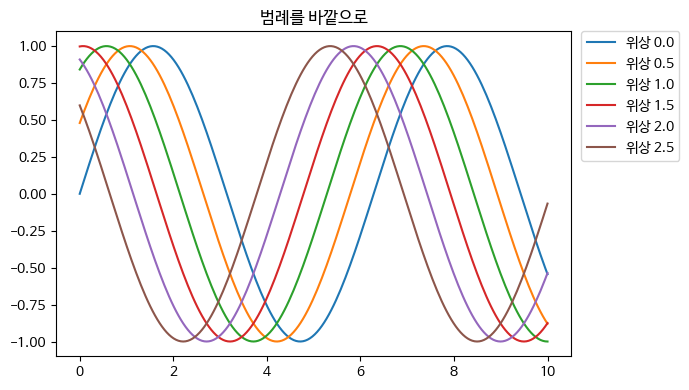

In [29]:
# 범례를 그래프 바깥으로 (선이 많을 때 유용)
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(6):
    ax.plot(x, np.sin(x + i * 0.5), label=f'위상 {i * 0.5}')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.set_title('범례를 바깥으로')
fig.tight_layout()
plt.show()

### 범례 꾸미기

| 인자 | 뜻 |
|---|---|
| `ncol` | 열 개수 (가로로 펼치기) |
| `fontsize` | 글자 크기 |
| `frameon` | 테두리 상자 표시 여부 |
| `shadow` | 그림자 |
| `framealpha` | 상자 투명도 |
| `edgecolor`, `facecolor` | 테두리색, 배경색 |
| `title` | 범례 제목 |

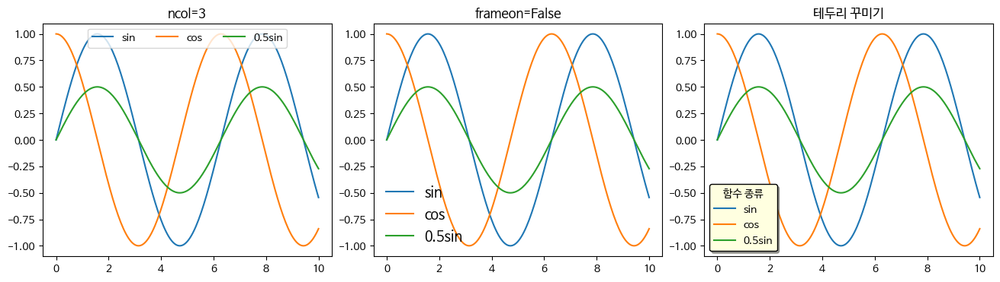

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax in axes:
    ax.plot(x, np.sin(x), label='sin')
    ax.plot(x, np.cos(x), label='cos')
    ax.plot(x, np.sin(x) * 0.5, label='0.5sin')

axes[0].legend(ncol=3, loc='upper center')
axes[0].set_title('ncol=3')

axes[1].legend(frameon=False, fontsize=13)
axes[1].set_title('frameon=False')

axes[2].legend(shadow=True, framealpha=1, edgecolor='black',
               facecolor='lightyellow', title='함수 종류')
axes[2].set_title('테두리 꾸미기')
plt.show()

## 3.7 축 다루기

### 축 범위 — `set_xlim`, `set_ylim`

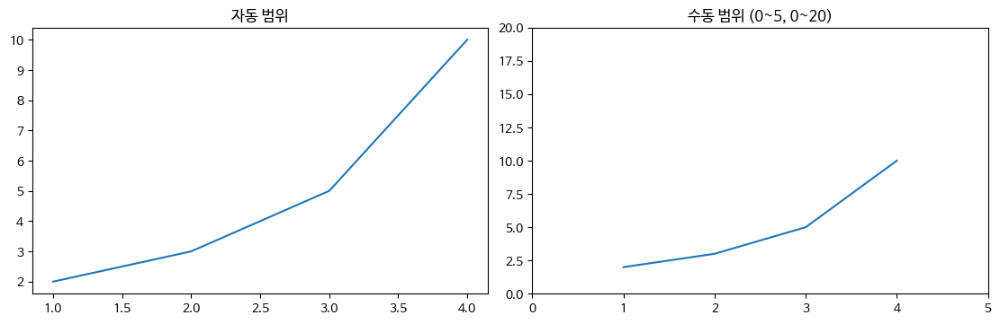

왼쪽 그래프 x 범위: (np.float64(0.85), np.float64(4.15))
왼쪽 그래프 y 범위: (np.float64(1.6), np.float64(10.4))


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)

axes[0].plot(xs, [2, 3, 5, 10])
axes[0].set_title('자동 범위')

axes[1].plot(xs, [2, 3, 5, 10])
axes[1].set_xlim(0, 5)
axes[1].set_ylim(0, 20)
axes[1].set_title('수동 범위 (0~5, 0~20)')
plt.show()

print('왼쪽 그래프 x 범위:', axes[0].get_xlim())
print('왼쪽 그래프 y 범위:', axes[0].get_ylim())

> **주의: y축을 0부터 시작하지 않으면 차이가 과장됩니다.**
> 막대그래프는 **반드시 0부터** 시작해야 합니다. 선 그래프는 변화를 보여주는 목적이면 0부터 시작하지 않아도 되지만, 그 사실을 명시해야 합니다.

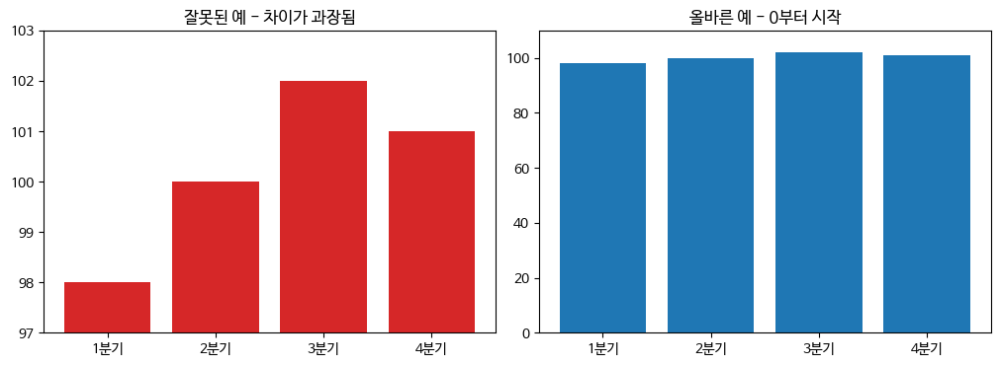

In [32]:
vals = [98, 100, 102, 101]
labels = ['1분기', '2분기', '3분기', '4분기']

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axes[0].bar(labels, vals, color='tab:red')
axes[0].set_ylim(97, 103)
axes[0].set_title('잘못된 예 - 차이가 과장됨')

axes[1].bar(labels, vals, color='tab:blue')
axes[1].set_ylim(0, 110)
axes[1].set_title('올바른 예 - 0부터 시작')
plt.show()

### 축 스케일 — 로그 축

값의 범위가 수십~수백만처럼 넓을 때 씁니다. 사용 가능한 스케일: `'linear'`, `'log'`, `'symlog'`(음수 포함), `'logit'`

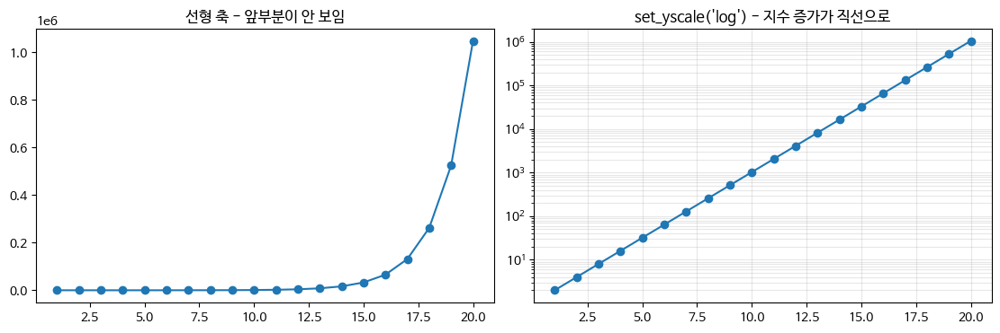

In [33]:
n = np.arange(1, 21)
vals2 = 2.0 ** n

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].plot(n, vals2, 'o-')
axes[0].set_title('선형 축 - 앞부분이 안 보임')

axes[1].plot(n, vals2, 'o-')
axes[1].set_yscale('log')
axes[1].set_title("set_yscale('log') - 지수 증가가 직선으로")
axes[1].grid(True, which='both', alpha=0.3)
plt.show()

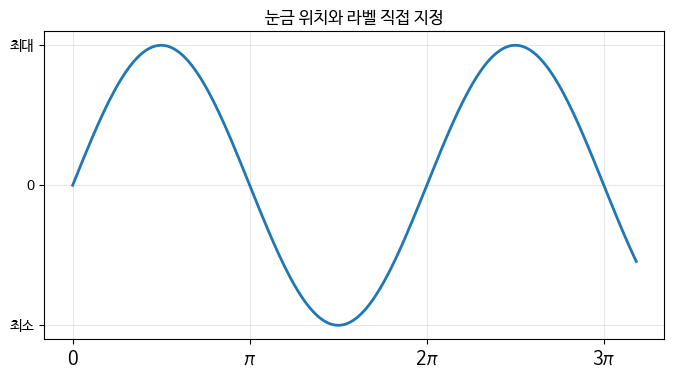

In [34]:
# 눈금(ticks) 위치와 라벨 직접 지정
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.sin(x), lw=2)

ax.set_xticks([0, np.pi, 2*np.pi, 3*np.pi])
ax.set_xticklabels(['0', 'π', '2π', '3π'], fontsize=13)

ax.set_yticks([-1, 0, 1])
ax.set_yticklabels(['최소', '0', '최대'])

ax.set_title('눈금 위치와 라벨 직접 지정')
ax.grid(alpha=0.3)
plt.show()

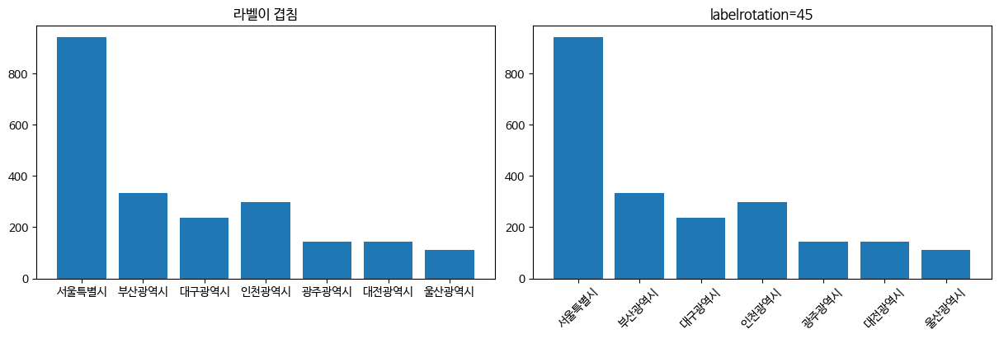

In [35]:
# 라벨이 길 때: 회전시키기
names = ['서울특별시', '부산광역시', '대구광역시', '인천광역시', '광주광역시', '대전광역시', '울산광역시']
pop = [941, 334, 238, 297, 143, 145, 111]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].bar(names, pop)
axes[0].set_title('라벨이 겹침')

axes[1].bar(names, pop)
axes[1].tick_params(axis='x', labelrotation=45)
axes[1].set_title('labelrotation=45')
plt.show()

### `tick_params` — 눈금 모양 전체 제어

| 인자 | 뜻 |
|---|---|
| `axis` | `'x'`, `'y'`, `'both'` |
| `direction` | `'in'`, `'out'`, `'inout'` |
| `length`, `width` | 눈금선 길이·굵기 |
| `labelsize` | 라벨 글자 크기 |
| `labelrotation` | 라벨 회전 각도 |
| `colors` | 눈금+라벨 색 |
| `pad` | 눈금과 라벨 사이 간격 |
| `top`, `bottom`, `left`, `right` | 어느 쪽에 눈금을 그릴지 |

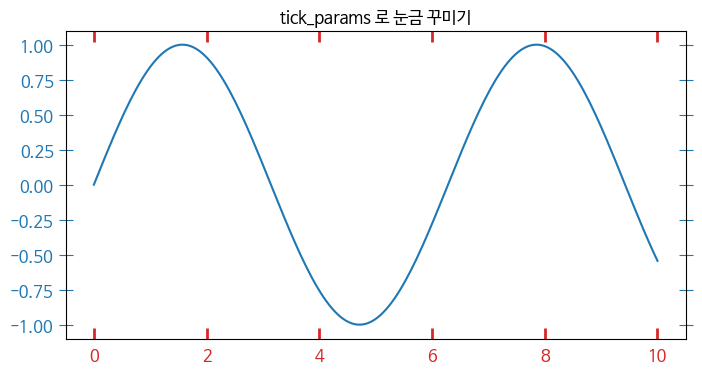

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.sin(x))
ax.tick_params(axis='x', direction='in', length=8, width=2,
               colors='tab:red', labelsize=12, pad=6, top=True)
ax.tick_params(axis='y', direction='inout', length=10,
               colors='tab:blue', labelsize=12, right=True)
ax.set_title('tick_params 로 눈금 꾸미기')
plt.show()

### 눈금 라벨 서식 — 천단위 콤마, 퍼센트

숫자가 `1000000` 처럼 나오면 읽기 어렵습니다. **Formatter** 로 고칩니다.

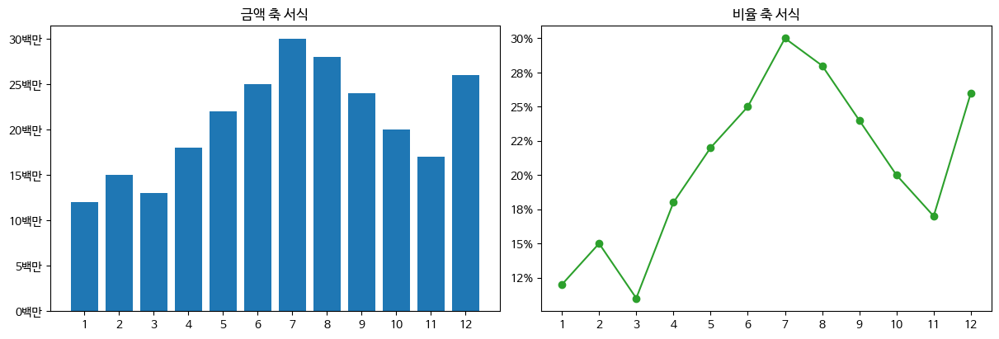

In [37]:
from matplotlib.ticker import FuncFormatter, PercentFormatter, MultipleLocator

months = np.arange(1, 13)
sales = np.array([12, 15, 13, 18, 22, 25, 30, 28, 24, 20, 17, 26]) * 1_000_000
rate  = np.array([.12, .15, .11, .18, .22, .25, .30, .28, .24, .20, .17, .26])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].bar(months, sales, color='tab:blue')
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{v/1e6:,.0f}백만'))
axes[0].xaxis.set_major_locator(MultipleLocator(1))
axes[0].set_title('금액 축 서식')

axes[1].plot(months, rate, 'o-', color='tab:green')
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[1].xaxis.set_major_locator(MultipleLocator(1))
axes[1].set_title('비율 축 서식')
plt.show()

### 그리드 (grid)

| 인자 | 뜻 |
|---|---|
| `axis` | `'x'`, `'y'`, `'both'` |
| `which` | `'major'`, `'minor'`, `'both'` |
| `alpha` | 투명도 (연하게 하는 게 핵심) |
| `linestyle`, `linewidth`, `color` | 선 모양 |

> 그리드는 **데이터보다 눈에 띄면 안 됩니다.** `alpha=0.3` 정도로 연하게, 필요한 축만 켜세요.

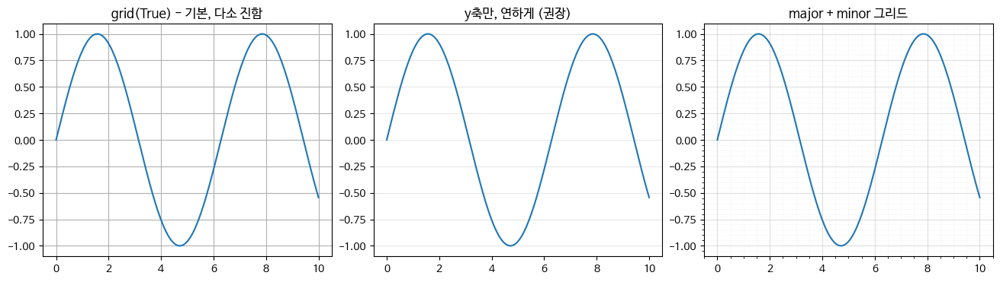

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)

axes[0].plot(x, np.sin(x)); axes[0].grid(True)
axes[0].set_title('grid(True) - 기본, 다소 진함')

axes[1].plot(x, np.sin(x)); axes[1].grid(True, axis='y', alpha=0.3)
axes[1].set_title('y축만, 연하게 (권장)')

axes[2].plot(x, np.sin(x))
axes[2].minorticks_on()
axes[2].grid(which='major', alpha=0.4)
axes[2].grid(which='minor', alpha=0.15, linestyle=':')
axes[2].set_title('major + minor 그리드')
plt.show()

### 이중 축 — `twinx()`

단위가 다른 두 데이터(예: 매출액과 성장률)를 한 그래프에 겹칠 때 씁니다.

> 주의: 이중 축은 **오해를 부르기 쉬운 그래프**입니다. 두 축의 범위를 어떻게 잡느냐에 따라 인상이 완전히 달라집니다. 꼭 필요할 때만 쓰세요.

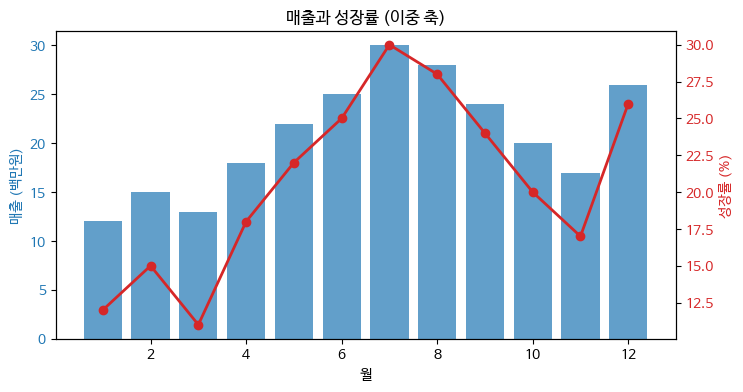

In [39]:
fig, ax1 = plt.subplots(figsize=(8, 4))
color1, color2 = 'tab:blue', 'tab:red'

ax1.bar(months, sales / 1e6, color=color1, alpha=0.7)
ax1.set_xlabel('월')
ax1.set_ylabel('매출 (백만원)', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()                    # x축을 공유하는 두 번째 y축
ax2.plot(months, rate * 100, color=color2, marker='o', lw=2)
ax2.set_ylabel('성장률 (%)', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

ax1.set_title('매출과 성장률 (이중 축)')
plt.show()

### 테두리(spines) 정리 — 깔끔한 그래프의 비결

기본 그래프는 사방이 상자로 둘러싸여 있습니다. 위·오른쪽 선을 지우면 훨씬 현대적으로 보입니다.

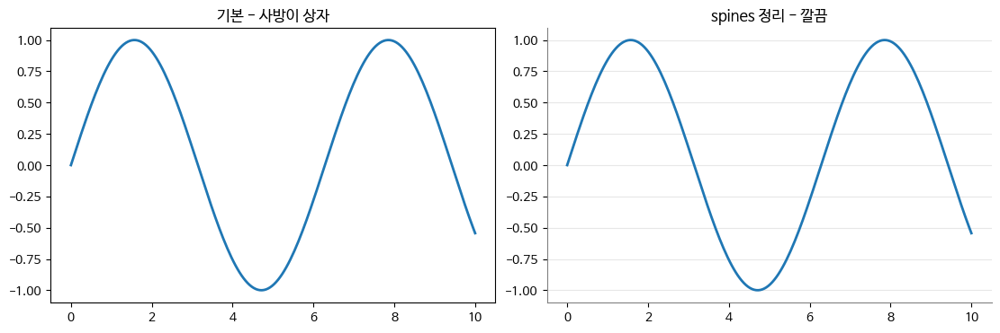

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)

axes[0].plot(x, np.sin(x), lw=2)
axes[0].set_title('기본 - 사방이 상자')

axes[1].plot(x, np.sin(x), lw=2)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_color('gray')
axes[1].spines['bottom'].set_color('gray')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_title('spines 정리 - 깔끔')
plt.show()

# 여러 개를 한 번에 (matplotlib 3.6+)
# ax.spines[['top', 'right']].set_visible(False)

## 3.8 영역 채우기

| 함수 | 용도 |
|---|---|
| `ax.fill_between(x, y1, y2)` | **x 기준** 두 곡선 사이 (신뢰구간에 필수) |
| `ax.fill_betweenx(y, x1, x2)` | y 기준 |
| `ax.fill(x, y)` | 임의의 다각형 |
| `ax.stackplot(x, *ys)` | 누적 면적 |

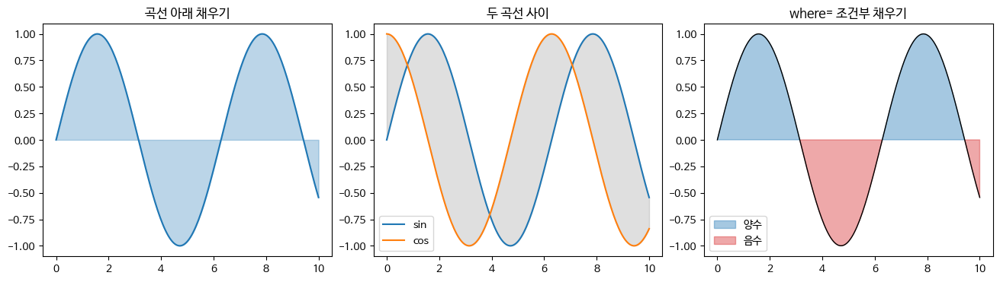

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)

axes[0].plot(x, np.sin(x), color='tab:blue')
axes[0].fill_between(x, np.sin(x), alpha=0.3, color='tab:blue')
axes[0].set_title('곡선 아래 채우기')

axes[1].plot(x, np.sin(x), label='sin')
axes[1].plot(x, np.cos(x), label='cos')
axes[1].fill_between(x, np.sin(x), np.cos(x), alpha=0.25, color='gray')
axes[1].legend(); axes[1].set_title('두 곡선 사이')

axes[2].plot(x, np.sin(x), color='k', lw=1)
axes[2].fill_between(x, np.sin(x), 0, where=(np.sin(x) >= 0),
                     color='tab:blue', alpha=0.4, interpolate=True, label='양수')
axes[2].fill_between(x, np.sin(x), 0, where=(np.sin(x) < 0),
                     color='tab:red', alpha=0.4, interpolate=True, label='음수')
axes[2].legend(); axes[2].set_title('where= 조건부 채우기')
plt.show()

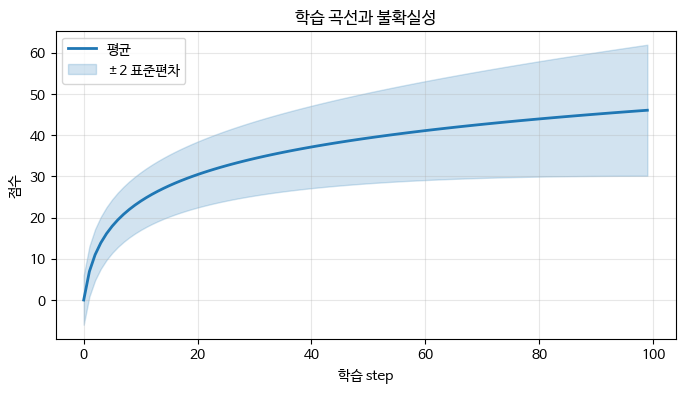

In [42]:
# 실전: 평균선 + 신뢰구간 밴드 (가장 많이 쓰는 패턴)
steps = np.arange(0, 100)
mean = np.log1p(steps) * 10
std = 3 + steps * 0.05

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, mean, color='tab:blue', lw=2, label='평균')
ax.fill_between(steps, mean - 2*std, mean + 2*std,
                color='tab:blue', alpha=0.2, label='±2 표준편차')
ax.set(xlabel='학습 step', ylabel='점수', title='학습 곡선과 불확실성')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 3.9 보조선 긋기

| 함수 | 뜻 |
|---|---|
| `ax.axhline(y)` | 가로 전체 선 |
| `ax.axvline(x)` | 세로 전체 선 |
| `ax.hlines(y, xmin, xmax)` | 구간 가로선 |
| `ax.vlines(x, ymin, ymax)` | 구간 세로선 |
| `ax.axhspan(y1, y2)` | 가로 띠(영역) |
| `ax.axvspan(x1, x2)` | 세로 띠(영역) |

목표선, 평균선, 특정 시점 표시에 씁니다.

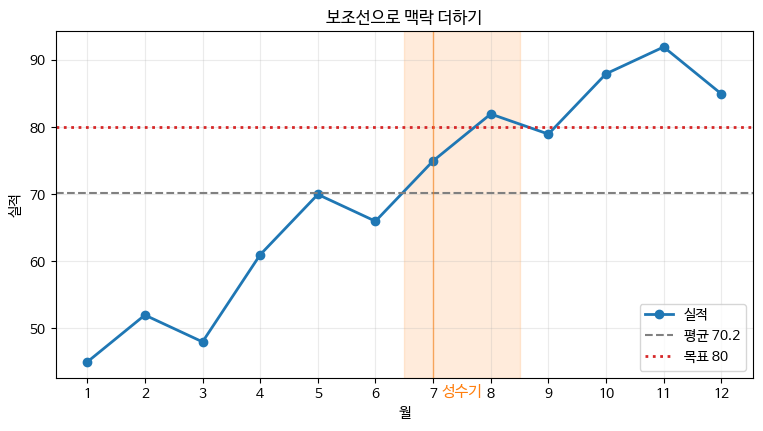

In [43]:
vals3 = np.array([45, 52, 48, 61, 70, 66, 75, 82, 79, 88, 92, 85])
avg = vals3.mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(months, vals3, 'o-', color='tab:blue', lw=2, label='실적')

ax.axhline(avg, color='gray', linestyle='--', lw=1.5, label=f'평균 {avg:.1f}')
ax.axhline(80, color='tab:red', linestyle=':', lw=2, label='목표 80')
ax.axvspan(6.5, 8.5, color='tab:orange', alpha=0.15)
ax.axvline(7, color='tab:orange', lw=1, alpha=0.6)
ax.text(7.5, 40, '성수기', color='tab:orange', fontsize=11, ha='center')

ax.set(xlabel='월', ylabel='실적', title='보조선으로 맥락 더하기', xticks=months)
ax.legend(loc='lower right')
ax.grid(alpha=0.25)
plt.show()

## 3.10 텍스트와 주석

| 함수 | 용도 |
|---|---|
| `ax.text(x, y, s)` | **데이터 좌표**에 글자 |
| `ax.annotate(s, xy=, xytext=)` | 화살표로 특정 점을 가리키기 |
| `ax.text(..., transform=ax.transAxes)` | **Axes 상대 좌표**(0~1)에 글자 |
| `fig.text(x, y, s)` | Figure 전체 기준 |

> **좋은 그래프는 결론이 글자로 적혀 있습니다.** 보는 사람이 스스로 해석하게 두지 마세요.

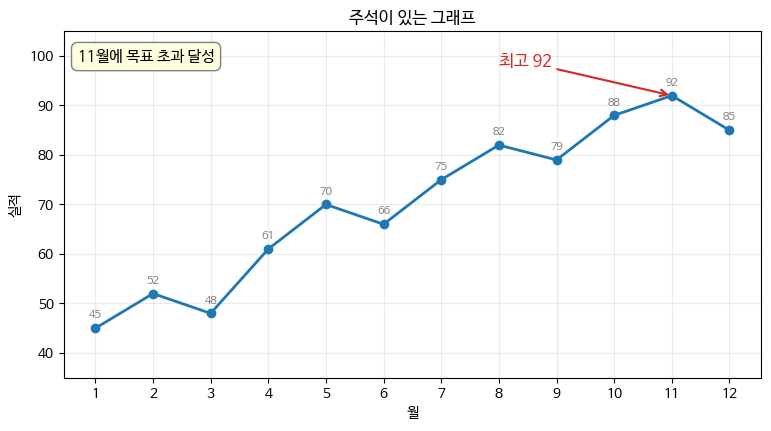

In [44]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(months, vals3, 'o-', color='tab:blue', lw=2)

# 최고점에 화살표 주석
imax = int(vals3.argmax())
ax.annotate(f'최고 {vals3[imax]}',
            xy=(months[imax], vals3[imax]),
            xytext=(months[imax] - 3, vals3[imax] + 6),
            arrowprops=dict(arrowstyle='->', color='tab:red', lw=1.5),
            fontsize=12, color='tab:red')

# 각 점 위에 값 표시
for mo, v in zip(months, vals3):
    ax.text(mo, v + 2, str(v), ha='center', fontsize=8, color='gray')

# Axes 상대 좌표에 메모 상자
ax.text(0.02, 0.95, '11월에 목표 초과 달성',
        transform=ax.transAxes, va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray'))

ax.set(xlabel='월', ylabel='실적', title='주석이 있는 그래프', xticks=months, ylim=(35, 105))
ax.grid(alpha=0.25)
plt.show()

### 텍스트 정렬 인자

| 인자 | 값 |
|---|---|
| `ha` (horizontalalignment) | `'left'`, `'center'`, `'right'` |
| `va` (verticalalignment) | `'top'`, `'center'`, `'bottom'`, `'baseline'` |
| `rotation` | 각도 또는 `'vertical'` |
| `bbox` | 배경 상자 `dict(boxstyle=..., facecolor=...)` |

`boxstyle` 종류: `'round'`, `'square'`, `'circle'`, `'larrow'`, `'rarrow'`, `'sawtooth'`

`arrowprops` 의 `arrowstyle`: `'->'`, `'-|>'`, `'<->'`, `'fancy'`, `'simple'`, `'wedge'`

In [45]:
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

def set_korean_font():
    s = platform.system()
    family = 'Malgun Gothic' if s == 'Windows' else ('AppleGothic' if s == 'Darwin' else 'NanumBarunGothic')
    plt.rcParams['font.family'] = family
    plt.rcParams['axes.unicode_minus'] = False
    return family

print('폰트:', set_korean_font(), '| matplotlib', matplotlib.__version__)

rng = np.random.default_rng(42)
plt.rcParams['figure.constrained_layout.use'] = True

폰트: NanumBarunGothic | matplotlib 3.10.0


---

# Part 4. 차트 종류별 가이드

## 4.0 어떤 차트를 써야 하나? (가장 중요한 표)

차트 선택은 **무엇을 보여주고 싶은가**로 결정합니다.

| 목적 | 추천 차트 | 함수 |
|---|---|---|
| 시간에 따른 **변화** | 선 그래프 | `ax.plot()` |
| 항목 간 **크기 비교** | 막대 그래프 | `ax.bar()`, `ax.barh()` |
| 두 변수의 **관계** | 산점도 | `ax.scatter()` |
| 한 변수의 **분포** | 히스토그램 | `ax.hist()` |
| 여러 그룹의 **분포 비교** | 박스플롯 / 바이올린 | `ax.boxplot()`, `ax.violinplot()` |
| **구성비** (2~3개 항목만) | 파이 / 누적막대 | `ax.pie()` |
| 2차원 **격자 값** | 히트맵 | `ax.imshow()`, `ax.pcolormesh()` |
| 측정 **오차·불확실성** | 에러바 | `ax.errorbar()` |
| 전체 대비 **구성 변화** | 누적 면적 | `ax.stackplot()` |

### 차트 선택 3원칙

1. **비교는 길이로.** 사람은 각도나 넓이보다 길이를 훨씬 정확히 비교합니다. → 파이보다 막대
2. **범주가 많으면 가로 막대.** 이름이 길어도 안 겹칩니다.
3. **3차원 효과, 그림자, 무의미한 색은 쓰지 않습니다.** 정보를 방해할 뿐입니다.

## 4.1 막대 그래프 — `bar()`

가장 많이 쓰이고, 가장 많이 잘못 쓰이는 차트입니다.

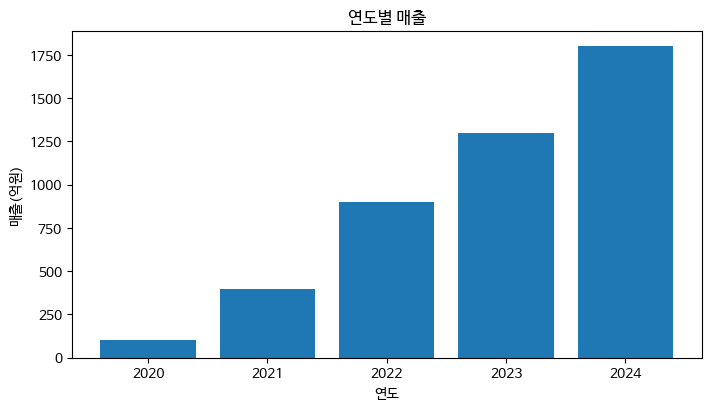

In [46]:
years = ['2020', '2021', '2022', '2023', '2024']
values = [100, 400, 900, 1300, 1800]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(years, values, color='tab:blue')
ax.set(xlabel='연도', ylabel='매출(억원)', title='연도별 매출')
plt.show()

### 주요 인자

| 인자 | 뜻 | 기본값 |
|---|---|---|
| `width` | 막대 폭 (0~1) | 0.8 |
| `color` | 색 (리스트로 개별 지정 가능) | 컬러 사이클 |
| `edgecolor`, `linewidth` | 테두리 | 없음 |
| `align` | `'center'` / `'edge'` | `'center'` |
| `bottom` | 시작 높이 (누적 막대에 사용) | 0 |
| `alpha` | 투명도 | 1 |
| `hatch` | 무늬 `'/' '\\\\' 'x' '.' '*'` | 없음 |

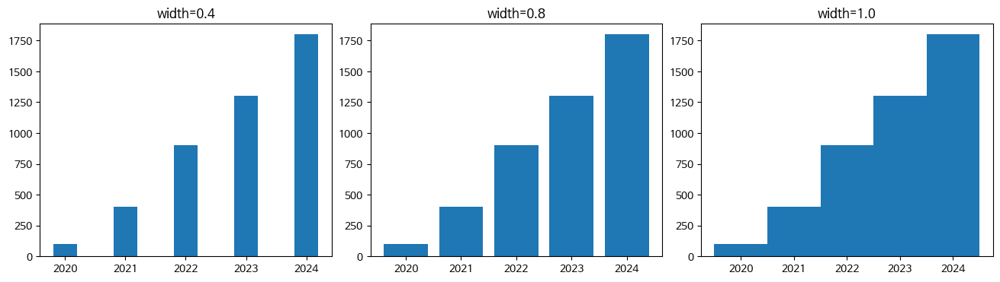

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

for ax, w in zip(axes, [0.4, 0.8, 1.0]):
    ax.bar(years, values, width=w, color='tab:blue')
    ax.set_title(f'width={w}')
plt.show()

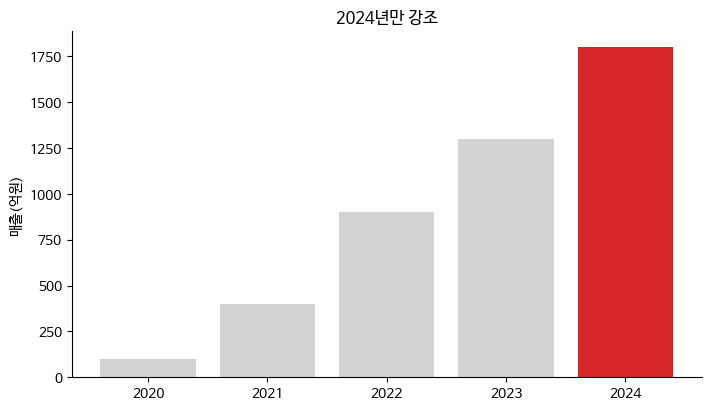

In [48]:
# 특정 막대만 강조하기 — 실무에서 매우 자주 씀
highlight = 4                                  # 강조할 인덱스
colors = ['lightgray'] * len(values)
colors[highlight] = 'tab:red'

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(years, values, color=colors)
ax.set(title='2024년만 강조', ylabel='매출(억원)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

### 막대 위에 값 표시 — `bar_label()`

막대 그래프는 값을 직접 적어주면 y축 눈금이 필요 없어져 훨씬 깔끔해집니다. (matplotlib 3.4 이상)

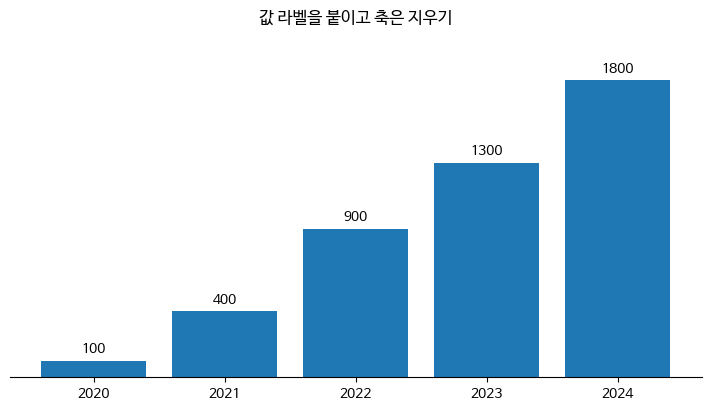

In [49]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(years, values, color='tab:blue')

ax.bar_label(bars, fmt='%d', padding=3, fontsize=10)

ax.set(title='값 라벨을 붙이고 축은 지우기', ylim=(0, 2100))
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.set_yticks([])
plt.show()

### 그룹 막대 (여러 계열 비교)

핵심 아이디어: x 위치를 **폭만큼 좌우로 밀어서** 나란히 놓습니다.

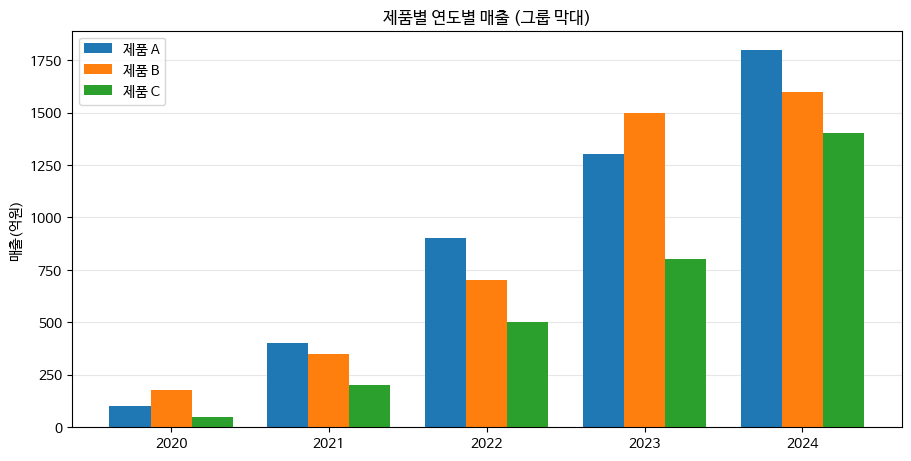

In [50]:
product_a = [100, 400, 900, 1300, 1800]
product_b = [180, 350, 700, 1500, 1600]
product_c = [ 50, 200, 500,  800, 1400]

xpos = np.arange(len(years))
width = 0.26

fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(xpos - width, product_a, width, label='제품 A')
b2 = ax.bar(xpos,         product_b, width, label='제품 B')
b3 = ax.bar(xpos + width, product_c, width, label='제품 C')

ax.set_xticks(xpos)
ax.set_xticklabels(years)
ax.set(ylabel='매출(억원)', title='제품별 연도별 매출 (그룹 막대)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)         # 그리드를 막대 뒤로
plt.show()

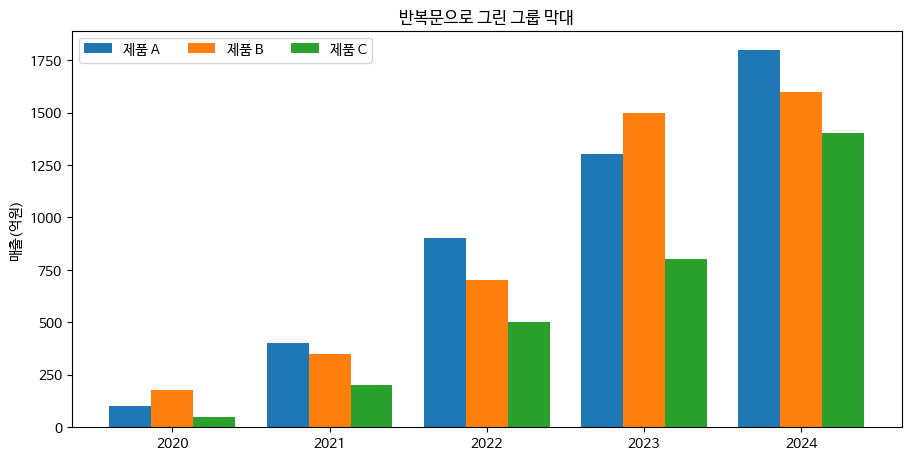

In [51]:
# 계열이 늘어나도 되는 일반화된 코드 (딕셔너리 반복)
series = {'제품 A': product_a, '제품 B': product_b, '제품 C': product_c}
n = len(series)
width = 0.8 / n

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (name, vals) in enumerate(series.items()):
    offset = (i - (n - 1) / 2) * width
    ax.bar(xpos + offset, vals, width, label=name)

ax.set_xticks(xpos, years)          # 3.5+ 에서는 이렇게 한 줄로 가능
ax.set(ylabel='매출(억원)', title='반복문으로 그린 그룹 막대')
ax.legend(ncol=3)
plt.show()

### 누적 막대 — `bottom=`

**전체 합계와 구성비를 동시에** 보여줍니다. 아래 막대의 누적합을 `bottom`으로 넘기는 것이 핵심입니다.

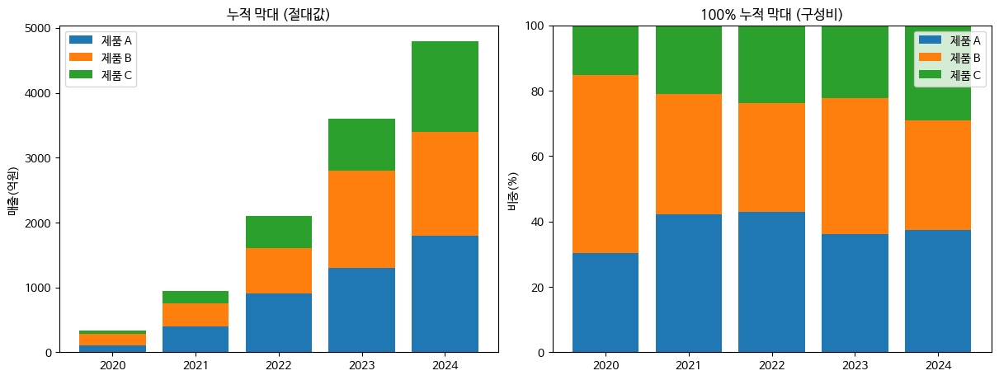

In [52]:
arr = np.array([product_a, product_b, product_c])
bottom = np.zeros(len(years))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 절대값 누적
for vals, name in zip(arr, series.keys()):
    axes[0].bar(years, vals, bottom=bottom, label=name)
    bottom += vals
axes[0].set(title='누적 막대 (절대값)', ylabel='매출(억원)')
axes[0].legend()

# 100% 누적 (구성비)
ratio = arr / arr.sum(axis=0) * 100
bottom = np.zeros(len(years))
for vals, name in zip(ratio, series.keys()):
    axes[1].bar(years, vals, bottom=bottom, label=name)
    bottom += vals
axes[1].set(title='100% 누적 막대 (구성비)', ylabel='비중(%)', ylim=(0, 100))
axes[1].legend()

plt.show()

### 가로 막대 — `barh()`

**항목 이름이 길 때는 무조건 가로 막대**입니다. 그리고 값 크기 순으로 정렬하면 읽기 쉬워집니다.

> `barh`는 아래에서 위로 그리므로, 큰 값이 위에 오게 하려면 **오름차순으로 정렬**해서 넣습니다.

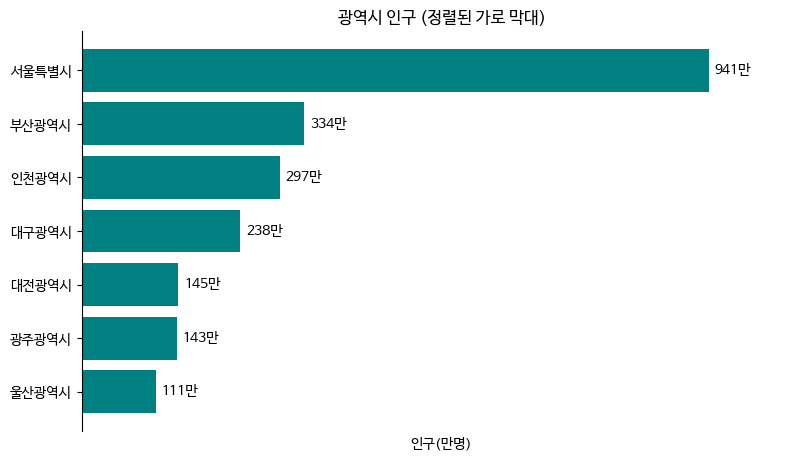

In [54]:
cities = ['서울특별시', '부산광역시', '인천광역시', '대구광역시', '대전광역시', '광주광역시', '울산광역시']
pop = [941, 334, 297, 238, 145, 143, 111]

order = np.argsort(pop)                       # 오름차순 인덱스
names_sorted = [cities[i] for i in order]
pop_sorted = [pop[i] for i in order]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(names_sorted, pop_sorted, color='teal')
ax.bar_label(bars, fmt='%d만', padding=4)
ax.set(xlabel='인구(만명)', title='광역시 인구 (정렬된 가로 막대)', xlim=(0, 1080))
ax.spines[['top', 'right', 'bottom']].set_visible(False)
ax.set_xticks([])
plt.show()

## 4.2 산점도 — `scatter()`

**두 연속 변수의 관계**를 봅니다. 상관관계, 이상치, 군집을 찾을 때 씁니다.

| 인자 | 뜻 |
|---|---|
| `s` | 점 크기 (배열을 주면 점마다 다르게 = 버블 차트) |
| `c` | 점 색 (배열 + `cmap` 이면 값에 따라 색이 변함) |
| `cmap` | 컬러맵 이름 |
| `alpha` | 투명도 (겹칠 때 필수) |
| `edgecolors`, `linewidths` | 점 테두리 |
| `marker` | 마커 모양 |

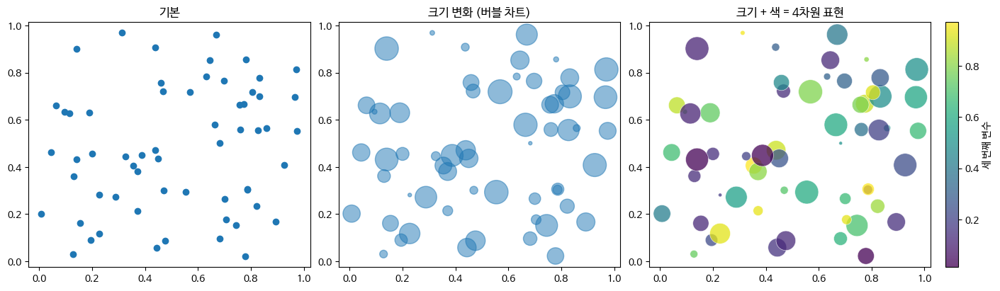

In [55]:
npts = 60
xr = rng.random(npts)
yr = rng.random(npts)
sizes = rng.random(npts) * 600
colors_v = rng.random(npts)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(xr, yr)
axes[0].set_title('기본')

axes[1].scatter(xr, yr, s=sizes, alpha=0.5, color='tab:blue')
axes[1].set_title('크기 변화 (버블 차트)')

sc = axes[2].scatter(xr, yr, s=sizes, c=colors_v, cmap='viridis',
                     alpha=0.75, edgecolors='white', linewidths=0.5)
axes[2].set_title('크기 + 색 = 4차원 표현')
fig.colorbar(sc, ax=axes[2], label='세 번째 변수')

plt.show()

### 그룹별 산점도 + 추세선

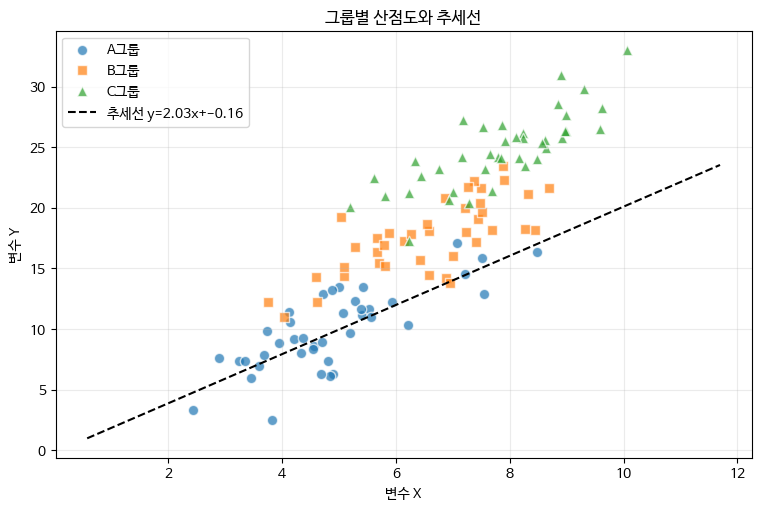

In [56]:
fig, ax = plt.subplots(figsize=(7.5, 5))

for name, shift, marker in [('A그룹', 0.0, 'o'), ('B그룹', 1.5, 's'), ('C그룹', 3.0, '^')]:
    gx = rng.normal(5 + shift, 1.2, 40)
    gy = gx * 2 + rng.normal(0, 2, 40) + shift * 3
    ax.scatter(gx, gy, label=name, alpha=0.7, marker=marker, s=55, edgecolors='white')

# 전체 추세선 (1차 회귀)
all_x = rng.normal(6.5, 2, 200)
all_y = all_x * 2 + rng.normal(0, 3, 200)
coef = np.polyfit(all_x, all_y, 1)
line_x = np.linspace(all_x.min(), all_x.max(), 100)
ax.plot(line_x, np.polyval(coef, line_x), 'k--', lw=1.5,
        label=f'추세선 y={coef[0]:.2f}x+{coef[1]:.2f}')

ax.set(xlabel='변수 X', ylabel='변수 Y', title='그룹별 산점도와 추세선')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

> **점이 너무 많으면?** 산점도는 1만 개가 넘으면 시커먼 덩어리가 됩니다. 대안:
> - `alpha=0.05` 로 낮추기
> - `ax.hexbin(x, y, gridsize=30)` — 육각형 밀도 그래프
> - `ax.hist2d(x, y, bins=50)` — 2차원 히스토그램

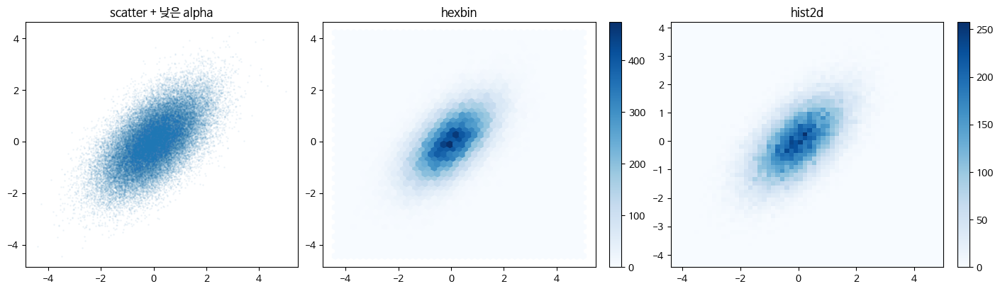

In [57]:
bigx = rng.standard_normal(50000)
bigy = bigx * 0.6 + rng.standard_normal(50000) * 0.8

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(bigx, bigy, s=1, alpha=0.05)
axes[0].set_title('scatter + 낮은 alpha')

hb = axes[1].hexbin(bigx, bigy, gridsize=40, cmap='Blues')
axes[1].set_title('hexbin')
fig.colorbar(hb, ax=axes[1])

h = axes[2].hist2d(bigx, bigy, bins=60, cmap='Blues')
axes[2].set_title('hist2d')
fig.colorbar(h[3], ax=axes[2])
plt.show()

## 4.3 히스토그램 — `hist()`

**한 변수의 분포**를 봅니다. 데이터를 구간(bin)으로 나눠 개수를 셉니다.

> 막대 그래프와 헷갈리지 마세요. 막대 그래프는 **범주별 값**, 히스토그램은 **연속값의 분포**입니다. 그래서 히스토그램은 막대 사이가 붙어 있습니다.

| 인자 | 뜻 |
|---|---|
| `bins` | 구간 개수 또는 경계 배열 |
| `density` | True면 넓이 합이 1 (확률밀도) |
| `cumulative` | 누적 히스토그램 |
| `histtype` | `'bar'`, `'step'`, `'stepfilled'` |
| `range` | 집계할 값 범위 |

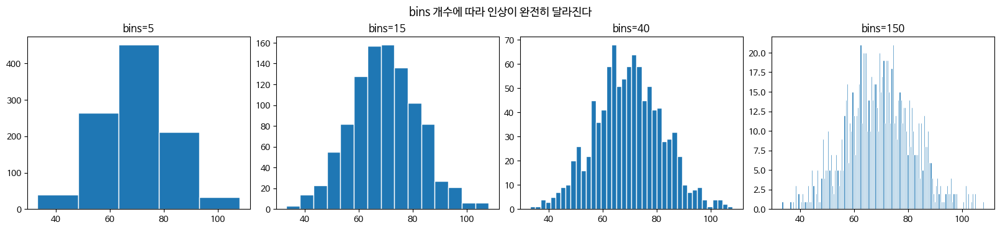

In [58]:
scores = rng.normal(70, 12, 1000)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, b in zip(axes, [5, 15, 40, 150]):
    ax.hist(scores, bins=b, color='tab:blue', edgecolor='white')
    ax.set_title(f'bins={b}')
fig.suptitle('bins 개수에 따라 인상이 완전히 달라진다', fontsize=13)
plt.show()

> **bins는 정직하게 고르세요.** 너무 적으면 정보가 뭉개지고, 너무 많으면 노이즈가 보입니다. 보통 `bins=30` 근처에서 시작해 조정합니다.

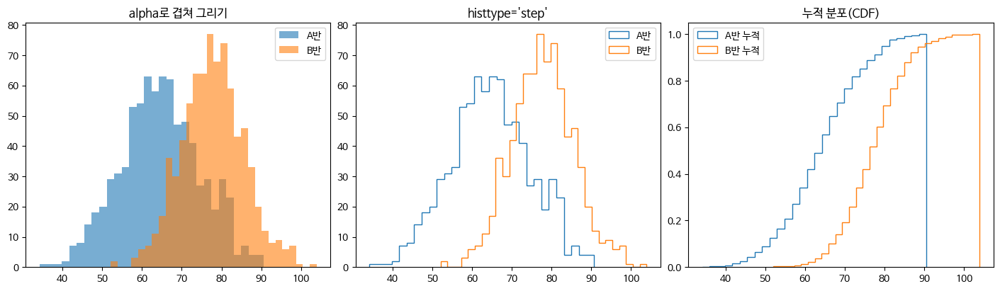

In [59]:
group1 = rng.normal(65, 10, 800)
group2 = rng.normal(78, 8, 800)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 겹쳐 그리기
axes[0].hist(group1, bins=30, alpha=0.6, label='A반')
axes[0].hist(group2, bins=30, alpha=0.6, label='B반')
axes[0].legend(); axes[0].set_title('alpha로 겹쳐 그리기')

# 윤곽선만
axes[1].hist(group1, bins=30, histtype='step', lw=2, label='A반')
axes[1].hist(group2, bins=30, histtype='step', lw=2, label='B반')
axes[1].legend(); axes[1].set_title("histtype='step'")

# 밀도 + 누적
axes[2].hist(group1, bins=30, density=True, cumulative=True,
             histtype='step', lw=2, label='A반 누적')
axes[2].hist(group2, bins=30, density=True, cumulative=True,
             histtype='step', lw=2, label='B반 누적')
axes[2].legend(); axes[2].set_title('누적 분포(CDF)')

plt.show()

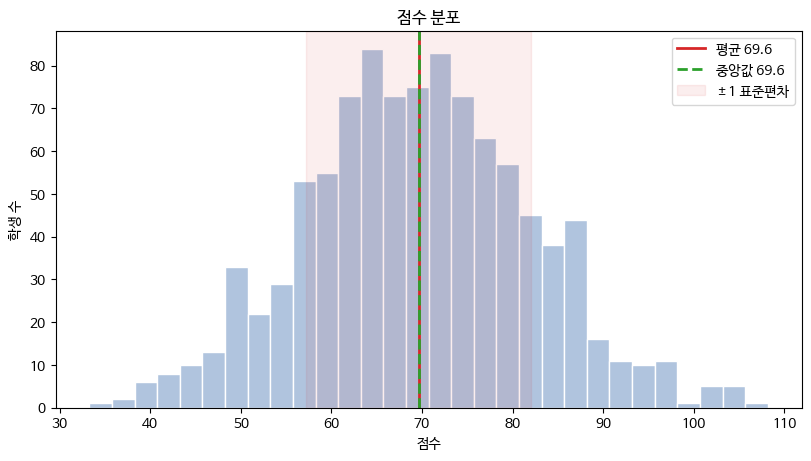

반환값 확인 — counts 앞 5개: [ 1.  2.  6.  8. 10.]
bin 경계 앞 5개: [33.28 35.78 38.28 40.77 43.27]


In [60]:
# 히스토그램에 통계선 얹기 (실전 패턴)
fig, ax = plt.subplots(figsize=(8, 4.5))
counts, bin_edges, patches = ax.hist(scores, bins=30, color='lightsteelblue', edgecolor='white')

m, sd = scores.mean(), scores.std()
ax.axvline(m, color='tab:red', lw=2, label=f'평균 {m:.1f}')
ax.axvline(np.median(scores), color='tab:green', lw=2, ls='--', label=f'중앙값 {np.median(scores):.1f}')
ax.axvspan(m - sd, m + sd, color='tab:red', alpha=0.08, label='±1 표준편차')

ax.set(xlabel='점수', ylabel='학생 수', title='점수 분포')
ax.legend()
plt.show()

print('반환값 확인 — counts 앞 5개:', counts[:5])
print('bin 경계 앞 5개:', np.round(bin_edges[:5], 2))

## 4.4 박스플롯 — `boxplot()`

**여러 그룹의 분포를 한눈에 비교**할 때 최고의 차트입니다.

```
            이상치 ○
              ┬        ← 위 수염 (Q3 + 1.5×IQR 이내 최댓값)
           ┌──┴──┐
           │     │     ← Q3 (상위 25%)
           ├─────┤     ← 중앙값 (Q2)
           │     │     ← Q1 (하위 25%)
           └──┬──┘
              ┴        ← 아래 수염
```

- 상자의 높이 = **IQR** (Q3 − Q1), 가운데 50%가 들어있는 범위
- 수염 밖의 점 = **이상치(outlier)**

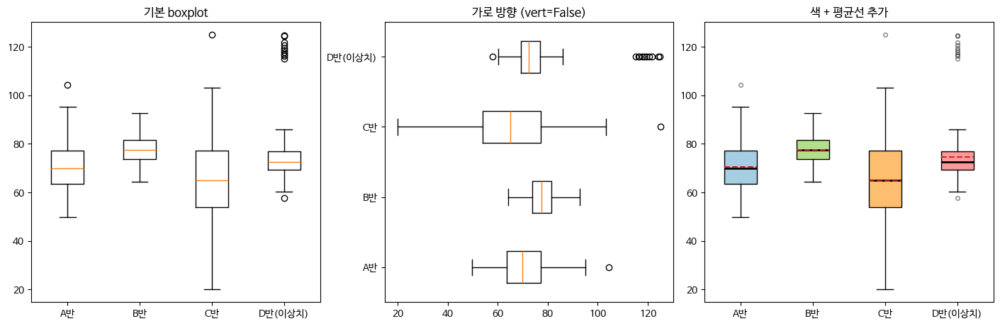

In [61]:
data_groups = [rng.normal(70, 10, 200),
               rng.normal(78, 6, 200),
               rng.normal(65, 18, 200),
               np.concatenate([rng.normal(72, 5, 190), rng.normal(120, 5, 10)])]
labels4 = ['A반', 'B반', 'C반', 'D반(이상치)']

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].boxplot(data_groups, tick_labels=labels4)
axes[0].set_title('기본 boxplot')

axes[1].boxplot(data_groups, tick_labels=labels4, vert=False)
axes[1].set_title('가로 방향 (vert=False)')

bp = axes[2].boxplot(data_groups, tick_labels=labels4, patch_artist=True,
                     showmeans=True, meanline=True,
                     medianprops=dict(color='black', lw=2),
                     meanprops=dict(color='tab:red', ls='--', lw=1.5),
                     flierprops=dict(marker='o', markersize=4, alpha=0.5))
for patch, c in zip(bp['boxes'], ['#a6cee3', '#b2df8a', '#fdbf6f', '#fb9a99']):
    patch.set_facecolor(c)
axes[2].set_title('색 + 평균선 추가')

plt.show()

> **버전 주의:** `tick_labels=` 는 matplotlib 3.9 이상입니다. 그 이전 버전은 `labels=` 를 쓰세요.

### 바이올린 플롯 — 분포의 모양까지 보여준다

박스플롯은 **봉우리가 두 개인 분포**를 감춥니다. 바이올린 플롯은 밀도 곡선을 함께 보여줍니다.

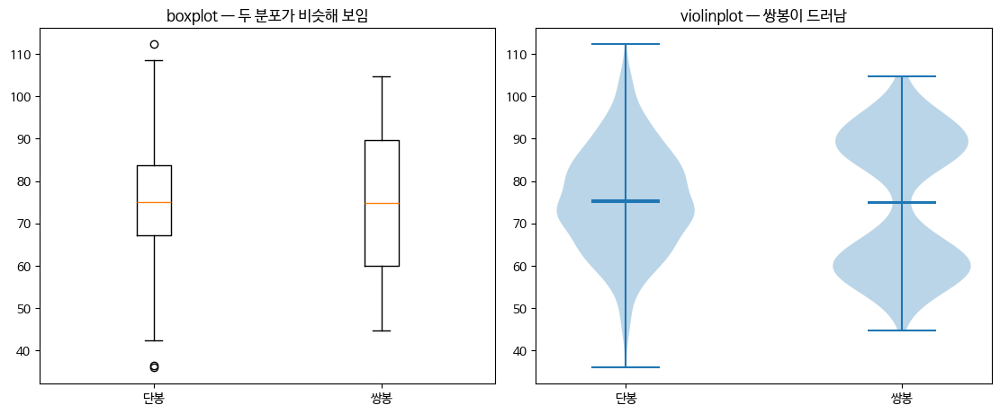

In [62]:
bimodal = np.concatenate([rng.normal(60, 5, 400), rng.normal(90, 5, 400)])
unimodal = rng.normal(75, 12, 800)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].boxplot([unimodal, bimodal], tick_labels=['단봉', '쌍봉'])
axes[0].set_title('boxplot — 두 분포가 비슷해 보임')

vp = axes[1].violinplot([unimodal, bimodal], showmeans=True, showmedians=True)
axes[1].set_xticks([1, 2], ['단봉', '쌍봉'])
axes[1].set_title('violinplot — 쌍봉이 드러남')

plt.show()

## 4.5 파이 차트 — `pie()`

> **먼저 경고부터.** 파이 차트는 통계 시각화에서 가장 비판받는 차트입니다. 사람은 각도 비교를 잘 못합니다. 항목이 4개 이상이면 **가로 막대나 100% 누적 막대**를 쓰세요.
>
> 그래도 파이가 적절한 경우: **2~3개 항목**, **전체 대비 비중이 핵심 메시지**일 때.

| 인자 | 뜻 |
|---|---|
| `labels` | 조각 이름 |
| `autopct` | 비율 표시 서식 (`'%.1f%%'`) |
| `explode` | 조각 분리 정도 (튜플) |
| `startangle` | 시작 각도 (보통 90) |
| `counterclock` | 반시계 방향 여부 (보통 False) |
| `shadow` | 그림자 (쓰지 마세요) |
| `wedgeprops` | 조각 스타일 → 도넛 만들기 |

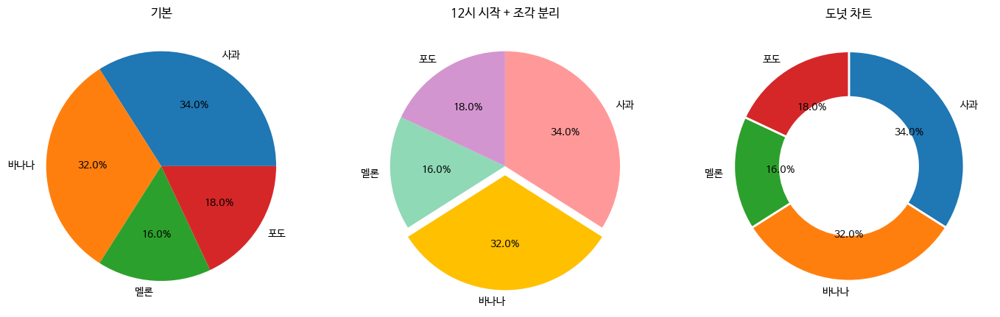

In [63]:
ratio = [34, 32, 16, 18]
pie_labels = ['사과', '바나나', '멜론', '포도']

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

axes[0].pie(ratio, labels=pie_labels, autopct='%.1f%%')
axes[0].set_title('기본')

axes[1].pie(ratio, labels=pie_labels, autopct='%.1f%%',
            startangle=90, counterclock=False,
            explode=[0, 0.08, 0, 0],
            colors=['#ff9999', '#ffc000', '#8fd9b6', '#d395d0'])
axes[1].set_title('12시 시작 + 조각 분리')

axes[2].pie(ratio, labels=pie_labels, autopct='%.1f%%',
            startangle=90, counterclock=False,
            wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[2].set_title('도넛 차트')

plt.show()

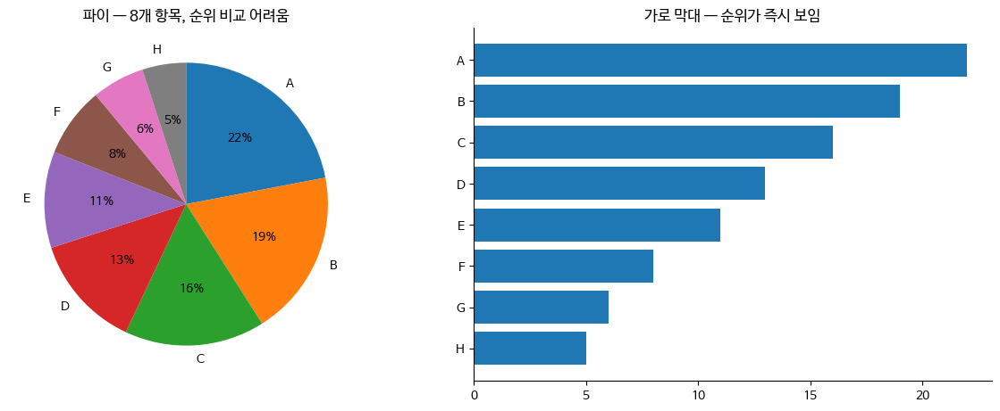

In [64]:
# 같은 데이터를 파이 vs 가로막대로 비교 — 어느 쪽이 읽기 쉬운가?
many_labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
many_vals = [22, 19, 16, 13, 11, 8, 6, 5]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].pie(many_vals, labels=many_labels, autopct='%.0f%%', startangle=90, counterclock=False)
axes[0].set_title('파이 — 8개 항목, 순위 비교 어려움')

axes[1].barh(many_labels[::-1], many_vals[::-1], color='tab:blue')
axes[1].set_title('가로 막대 — 순위가 즉시 보임')
axes[1].spines[['top', 'right']].set_visible(False)
plt.show()

## 4.6 히트맵 — `imshow()` / `pcolormesh()`

2차원 격자 데이터(상관행렬, 요일×시간 등)를 **색의 진하기**로 표현합니다.

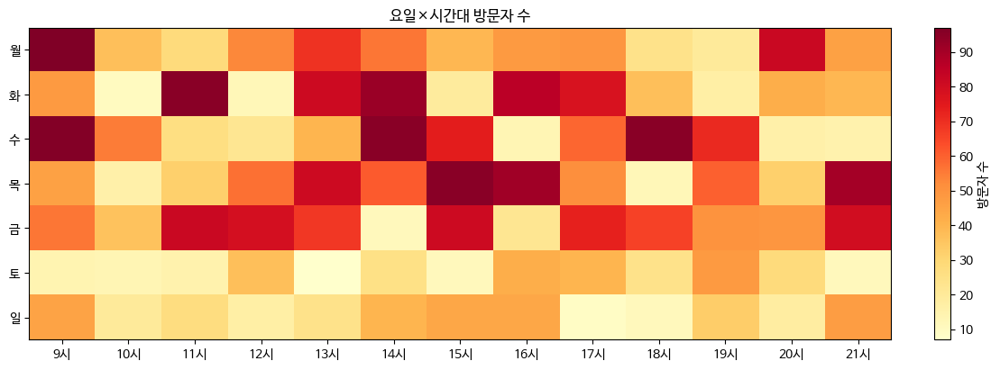

In [65]:
days = ['월', '화', '수', '목', '금', '토', '일']
hours = [f'{h}시' for h in range(9, 22)]
traffic = rng.integers(10, 100, (len(days), len(hours)))
traffic[5:, :] = traffic[5:, :] // 2          # 주말은 적게

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(traffic, cmap='YlOrRd', aspect='auto')

ax.set_xticks(range(len(hours)), hours)
ax.set_yticks(range(len(days)), days)
ax.set_title('요일×시간대 방문자 수')

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('방문자 수')
plt.show()

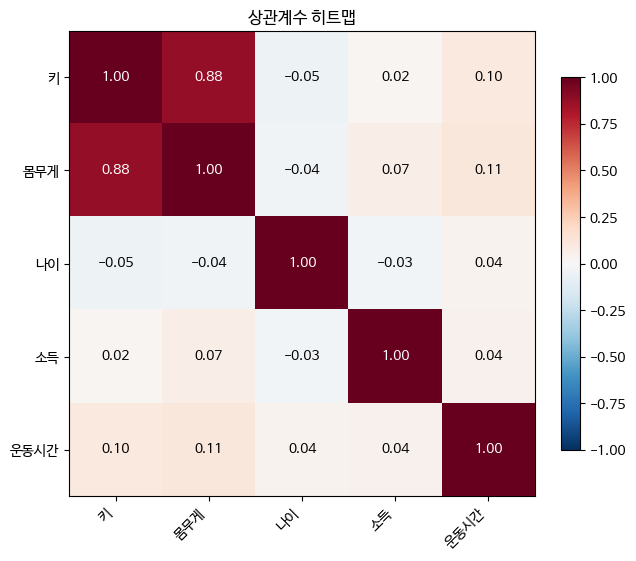

In [66]:
# 각 칸에 숫자 쓰기 (상관행렬에 필수)
cols = ['키', '몸무게', '나이', '소득', '운동시간']
base = rng.standard_normal((200, 5))
base[:, 1] = base[:, 0] * 0.8 + base[:, 1] * 0.4      # 키-몸무게 상관
corr = np.corrcoef(base, rowvar=False)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        color = 'white' if abs(corr[i, j]) > 0.6 else 'black'
        ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', color=color, fontsize=10)

ax.set_title('상관계수 히트맵')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

### 컬러맵 고르기 — 아무거나 쓰면 안 됩니다

| 종류 | 언제 | 예시 |
|---|---|---|
| **순차형 (sequential)** | 값이 낮음→높음 한 방향 | `viridis`, `plasma`, `Blues`, `YlOrRd` |
| **발산형 (diverging)** | 0을 기준으로 +/− | `RdBu_r`, `coolwarm`, `PiYG` |
| **순환형 (cyclic)** | 각도, 시간 | `twilight`, `hsv` |
| **질적 (qualitative)** | 범주 구분 | `tab10`, `Set2`, `Pastel1` |

> **`jet`은 쓰지 마세요.** 밝기가 들쭉날쭉해서 없는 경계를 만들어냅니다. 기본값 `viridis` 가 훨씬 정확하고 색맹 사용자도 읽을 수 있습니다.

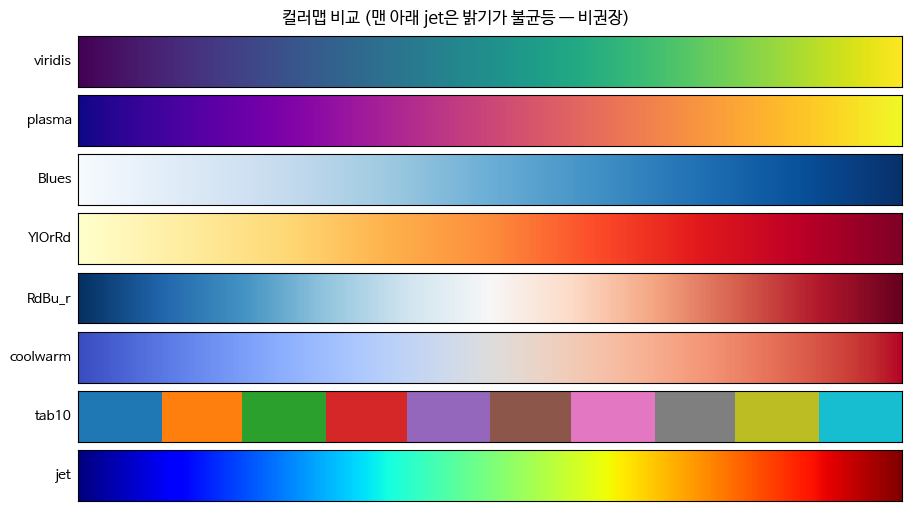

In [67]:
gradient = np.linspace(0, 1, 256).reshape(1, -1)
cmaps = ['viridis', 'plasma', 'Blues', 'YlOrRd', 'RdBu_r', 'coolwarm', 'tab10', 'jet']

fig, axes = plt.subplots(len(cmaps), 1, figsize=(9, 5))
for ax, name in zip(axes, cmaps):
    ax.imshow(gradient, aspect='auto', cmap=name)
    ax.set_ylabel(name, rotation=0, ha='right', va='center', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('컬러맵 비교 (맨 아래 jet은 밝기가 불균등 — 비권장)')
plt.show()

## 4.7 에러바 — `errorbar()`

측정값의 **불확실성**을 함께 보여줍니다. 실험 결과 보고에 필수입니다.

| 인자 | 뜻 |
|---|---|
| `yerr`, `xerr` | 오차 크기 (스칼라, 배열, 또는 `[아래, 위]` 2×N) |
| `fmt` | 마커/선 포맷 (`'o'`, `'o-'`, `'none'`) |
| `capsize` | 오차막대 끝 모자 길이 |
| `ecolor`, `elinewidth` | 오차막대 색·굵기 |

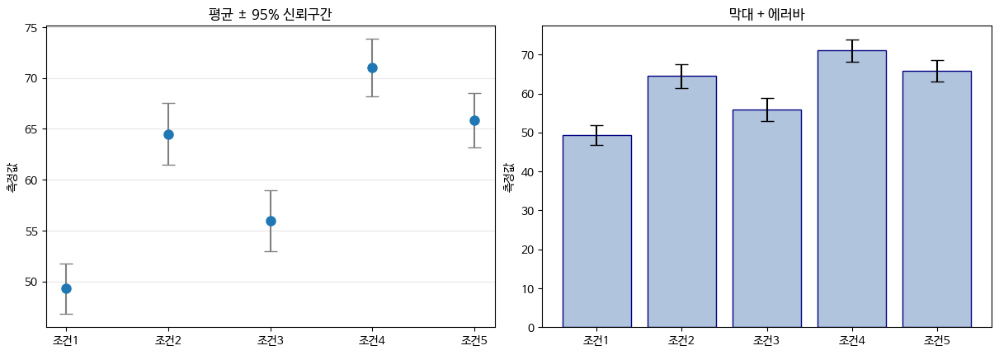

조건1:  49.31  (95% CI: 46.85 ~ 51.78)
조건2:  64.50  (95% CI: 61.47 ~ 67.53)
조건3:  55.94  (95% CI: 52.95 ~ 58.94)
조건4:  71.03  (95% CI: 68.23 ~ 73.83)
조건5:  65.81  (95% CI: 63.14 ~ 68.49)


In [68]:
conditions = ['조건1', '조건2', '조건3', '조건4', '조건5']
samples = [rng.normal(loc, 8, 30) for loc in [50, 62, 58, 71, 65]]

means = np.array([s.mean() for s in samples])
sems  = np.array([s.std(ddof=1) / np.sqrt(len(s)) for s in samples])
ci95  = 1.96 * sems                                  # 95% 신뢰구간

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].errorbar(conditions, means, yerr=ci95, fmt='o', capsize=6,
                 markersize=8, color='tab:blue', ecolor='gray', elinewidth=1.5)
axes[0].set(ylabel='측정값', title='평균 ± 95% 신뢰구간')
axes[0].grid(axis='y', alpha=0.3)

bars = axes[1].bar(conditions, means, yerr=ci95, capsize=6,
                   color='lightsteelblue', edgecolor='navy')
axes[1].set(ylabel='측정값', title='막대 + 에러바')

plt.show()

for c, m, e in zip(conditions, means, ci95):
    print(f'{c}: {m:6.2f}  (95% CI: {m-e:.2f} ~ {m+e:.2f})')

## 4.8 누적 면적 — `stackplot()`

시간에 따라 **전체 크기와 구성비가 어떻게 변하는지** 보여줍니다.

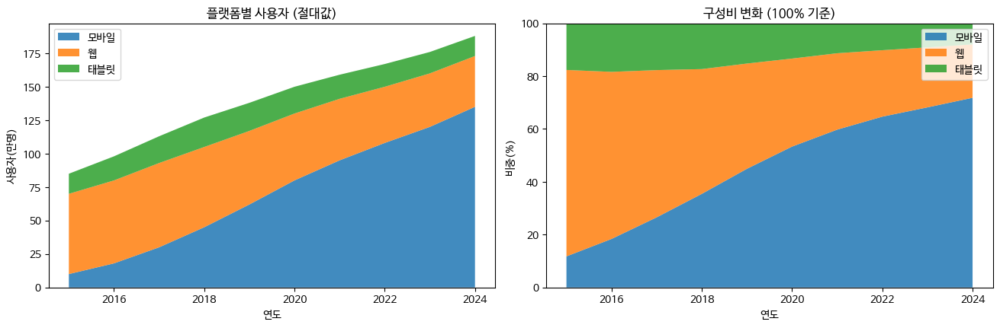

In [69]:
yr = np.arange(2015, 2025)
mobile  = np.array([10, 18, 30, 45, 62, 80, 95, 108, 120, 135])
web     = np.array([60, 62, 63, 60, 55, 50, 46, 42, 40, 38])
tablet  = np.array([15, 18, 20, 22, 21, 20, 18, 17, 16, 15])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].stackplot(yr, mobile, web, tablet,
                  labels=['모바일', '웹', '태블릿'], alpha=0.85)
axes[0].legend(loc='upper left')
axes[0].set(xlabel='연도', ylabel='사용자(만명)', title='플랫폼별 사용자 (절대값)')

total = mobile + web + tablet
axes[1].stackplot(yr, mobile/total*100, web/total*100, tablet/total*100,
                  labels=['모바일', '웹', '태블릿'], alpha=0.85)
axes[1].legend(loc='upper right')
axes[1].set(xlabel='연도', ylabel='비중(%)', title='구성비 변화 (100% 기준)', ylim=(0, 100))

plt.show()

---

# Part 5. 레이아웃 — 여러 그래프 배치

실무 그래프는 대부분 여러 개가 함께 붙어 있습니다. 배치 방법은 네 가지가 있고, **상황에 따라 골라 씁니다**.

| 방법 | 언제 |
|---|---|
| `plt.subplots(r, c)` | 격자가 규칙적일 때 (90%의 경우) |
| `plt.subplot_mosaic(...)` | 크기가 다른 칸이 섞일 때 (**가장 편함**) |
| `GridSpec` | 아주 세밀한 제어가 필요할 때 |
| `fig.add_axes([l, b, w, h])` | 그래프 안에 작은 그래프(inset)를 넣을 때 |

## 5.1 축 공유 — `sharex`, `sharey`

같은 축을 쓰는 그래프끼리 붙여 놓으면 **비교가 정확해지고 공간도 절약**됩니다.

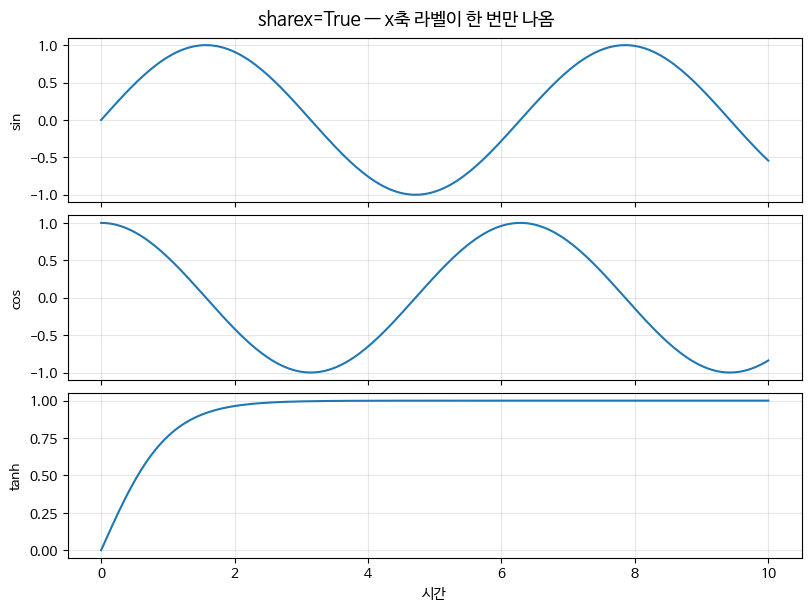

In [70]:
t = np.linspace(0, 10, 200)

fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
for ax, (f, name) in zip(axes, [(np.sin, 'sin'), (np.cos, 'cos'), (np.tanh, 'tanh')]):
    ax.plot(t, f(t))
    ax.set_ylabel(name)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('시간')                # 맨 아래에만 x라벨
fig.suptitle('sharex=True — x축 라벨이 한 번만 나옴', fontsize=13)
plt.show()

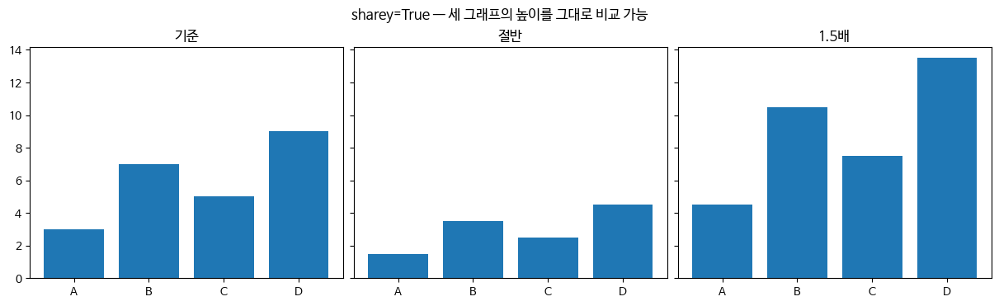

In [71]:
# sharey 로 값 크기를 정확히 비교
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, scale, name in zip(axes, [1.0, 0.5, 1.5], ['기준', '절반', '1.5배']):
    ax.bar(['A', 'B', 'C', 'D'], np.array([3, 7, 5, 9]) * scale)
    ax.set_title(name)
fig.suptitle('sharey=True — 세 그래프의 높이를 그대로 비교 가능')
plt.show()

## 5.2 겹침 해결 — `constrained_layout` vs `tight_layout`

제목과 축 라벨이 서로 겹치는 것은 초보자가 가장 자주 겪는 문제입니다.

| 방법 | 사용법 | 특징 |
|---|---|---|
| `tight_layout()` | `fig.tight_layout()` (그린 뒤 호출) | 오래된 방식, 간단 |
| **`constrained_layout`** | `plt.subplots(..., constrained_layout=True)` | **권장**. 컬러바·범례까지 고려 |
| 수동 | `fig.subplots_adjust(hspace=0.4, wspace=0.3)` | 완전 수동 제어 |

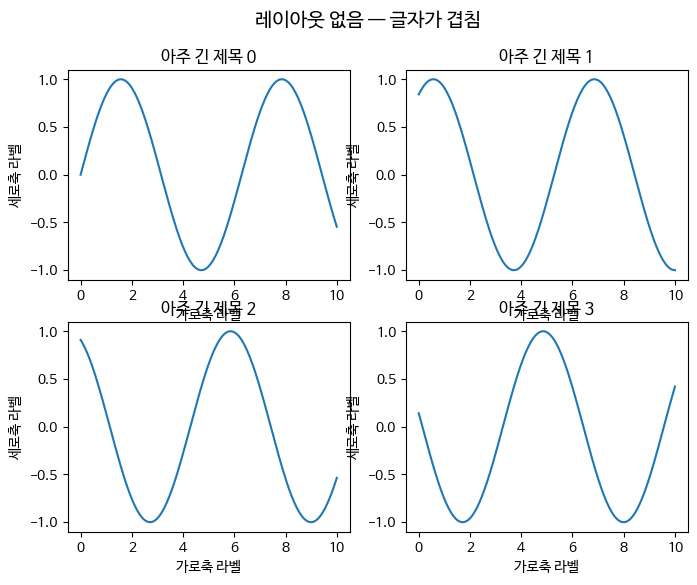

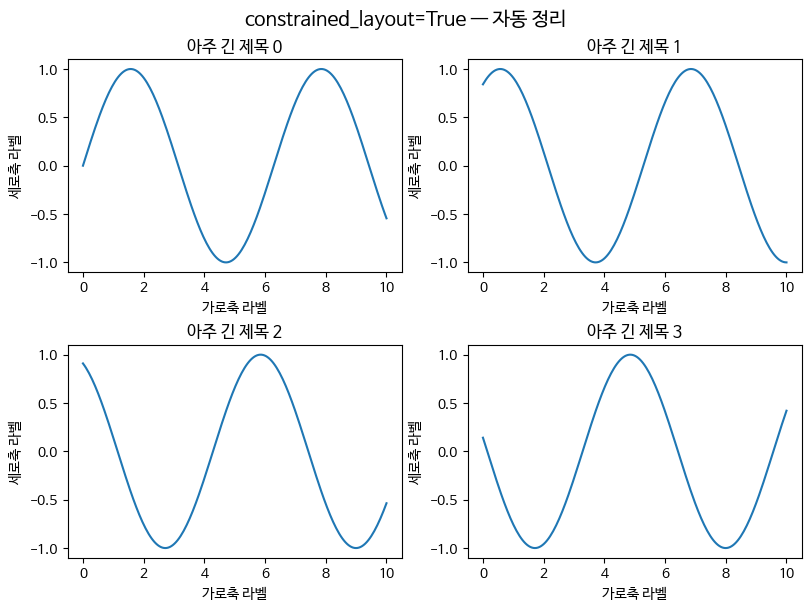

In [72]:
def make_demo(fig, axes, title):
    for i, ax in enumerate(axes.flatten()):
        ax.plot(t, np.sin(t + i))
        ax.set_title(f'아주 긴 제목 {i}')
        ax.set_xlabel('가로축 라벨')
        ax.set_ylabel('세로축 라벨')
    fig.suptitle(title, fontsize=14)

fig, axes = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=False)
make_demo(fig, axes, '레이아웃 없음 — 글자가 겹침')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
make_demo(fig, axes, 'constrained_layout=True — 자동 정리')
plt.show()

## 5.3 `subplot_mosaic` — 가장 직관적인 배치 (강력 추천)

**문자로 그림을 그리듯** 레이아웃을 씁니다. 같은 문자는 하나의 큰 칸으로 합쳐집니다.

반환값은 딕셔너리: ['A', 'B', 'C', 'D']


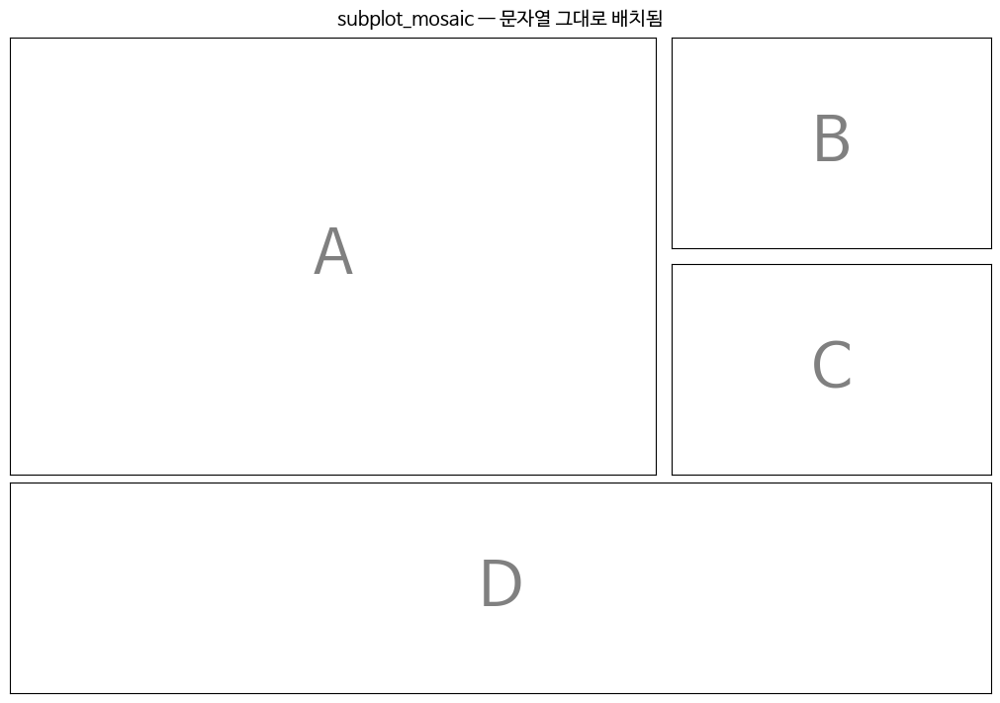

In [73]:
layout = '''
AAB
AAC
DDD
'''

fig, axd = plt.subplot_mosaic(layout, figsize=(10, 7), constrained_layout=True)

print('반환값은 딕셔너리:', list(axd.keys()))

for name, ax in axd.items():
    ax.text(0.5, 0.5, name, ha='center', va='center', fontsize=45, color='gray')
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle('subplot_mosaic — 문자열 그대로 배치됨', fontsize=14)
plt.show()

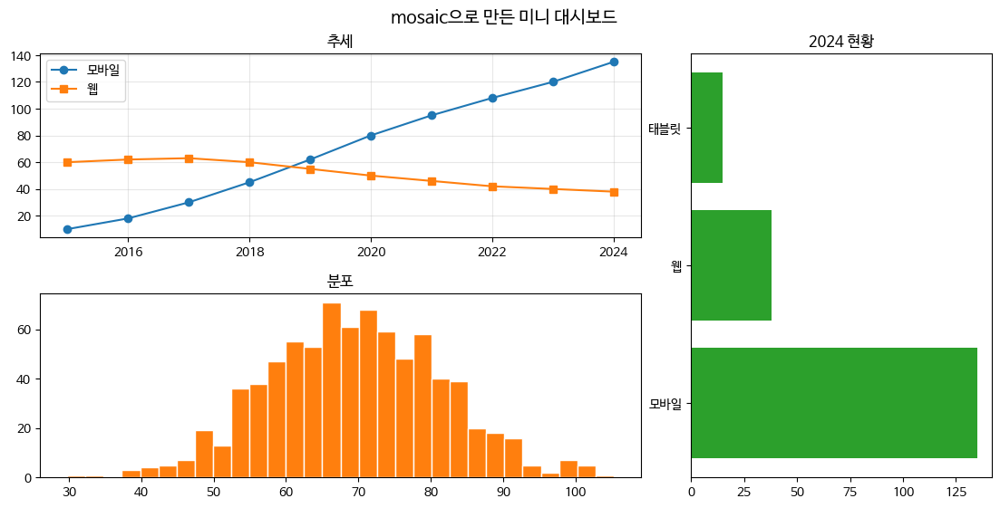

In [74]:
# 실제 데이터로 mosaic 사용 — 딕셔너리 키로 접근하니 코드가 읽기 쉽다
fig, axd = plt.subplot_mosaic('''
    AAB
    CCB
''', figsize=(11, 5.5), constrained_layout=True)

axd['A'].plot(yr, mobile, 'o-', label='모바일')
axd['A'].plot(yr, web, 's-', label='웹')
axd['A'].set_title('추세'); axd['A'].legend(); axd['A'].grid(alpha=0.3)

axd['B'].barh(['모바일', '웹', '태블릿'], [mobile[-1], web[-1], tablet[-1]], color='tab:green')
axd['B'].set_title('2024 현황')

axd['C'].hist(rng.normal(70, 12, 800), bins=30, color='tab:orange', edgecolor='white')
axd['C'].set_title('분포')

fig.suptitle('mosaic으로 만든 미니 대시보드', fontsize=14)
plt.show()

> 빈 칸을 두고 싶으면 `.` 을 씁니다.
> ```python
> layout = '''
> AB
> .B
> '''
> ```
> 리스트 형태로도 쓸 수 있습니다: `[['A', 'B'], ['A', 'C']]`

## 5.4 GridSpec — 정밀 제어

행/열의 **비율**까지 지정하고 싶을 때 씁니다.

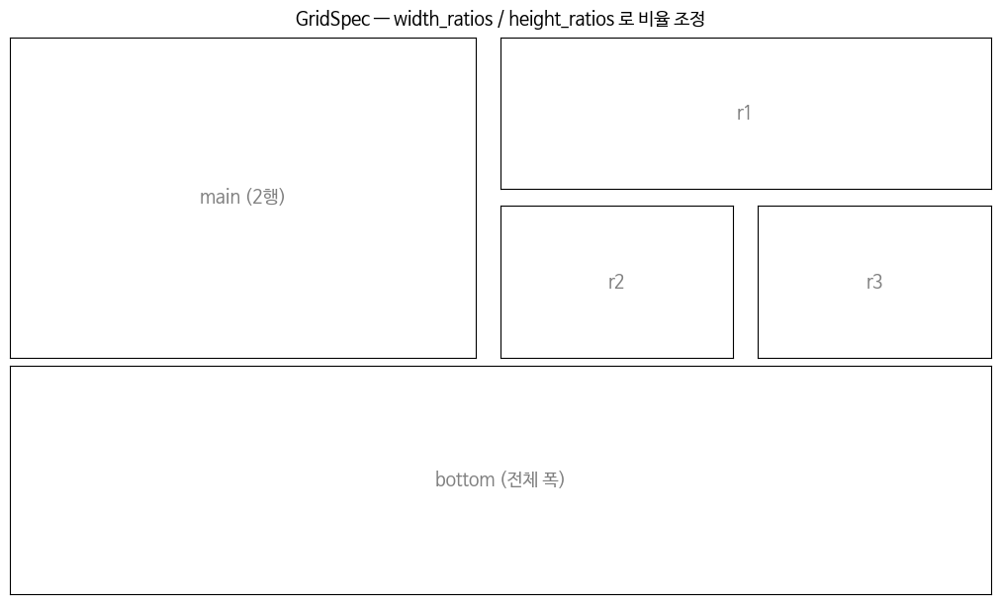

In [75]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(10, 6), constrained_layout=True)
gs = GridSpec(3, 3, figure=fig, width_ratios=[2, 1, 1], height_ratios=[1, 1, 1.5])

ax_main  = fig.add_subplot(gs[0:2, 0])      # 왼쪽 위 2행
ax_r1    = fig.add_subplot(gs[0, 1:])       # 오른쪽 위 2열
ax_r2    = fig.add_subplot(gs[1, 1])
ax_r3    = fig.add_subplot(gs[1, 2])
ax_bot   = fig.add_subplot(gs[2, :])        # 맨 아래 전체

for ax, name in [(ax_main, 'main (2행)'), (ax_r1, 'r1'), (ax_r2, 'r2'),
                 (ax_r3, 'r3'), (ax_bot, 'bottom (전체 폭)')]:
    ax.text(0.5, 0.5, name, ha='center', va='center', fontsize=13, color='gray')
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle('GridSpec — width_ratios / height_ratios 로 비율 조정', fontsize=13)
plt.show()

## 5.5 그래프 안의 그래프 (inset)

전체를 보여주면서 **일부를 확대**해 보여주고 싶을 때.

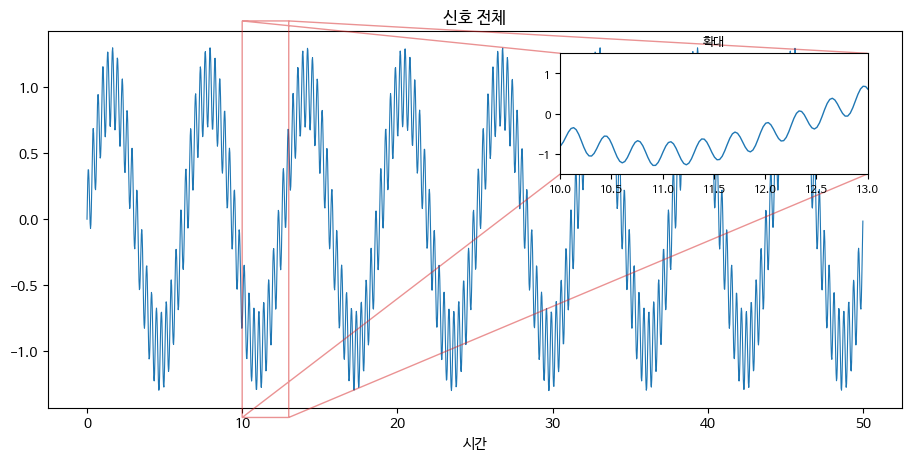

In [76]:
tt = np.linspace(0, 50, 2000)
signal = np.sin(tt) + 0.3 * np.sin(20 * tt)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tt, signal, lw=0.8)
ax.set(title='신호 전체', xlabel='시간')

# [왼쪽, 아래, 폭, 높이] — Figure 기준 0~1 상대 좌표
axins = ax.inset_axes([0.6, 0.62, 0.36, 0.32])
axins.plot(tt, signal, lw=1)
axins.set_xlim(10, 13)
axins.set_ylim(-1.5, 1.5)
axins.set_title('확대', fontsize=9)
axins.tick_params(labelsize=8)

ax.indicate_inset_zoom(axins, edgecolor='tab:red')   # 원본 위치를 표시
plt.show()

## 5.6 공통 요소 — suptitle, supxlabel, 공통 범례

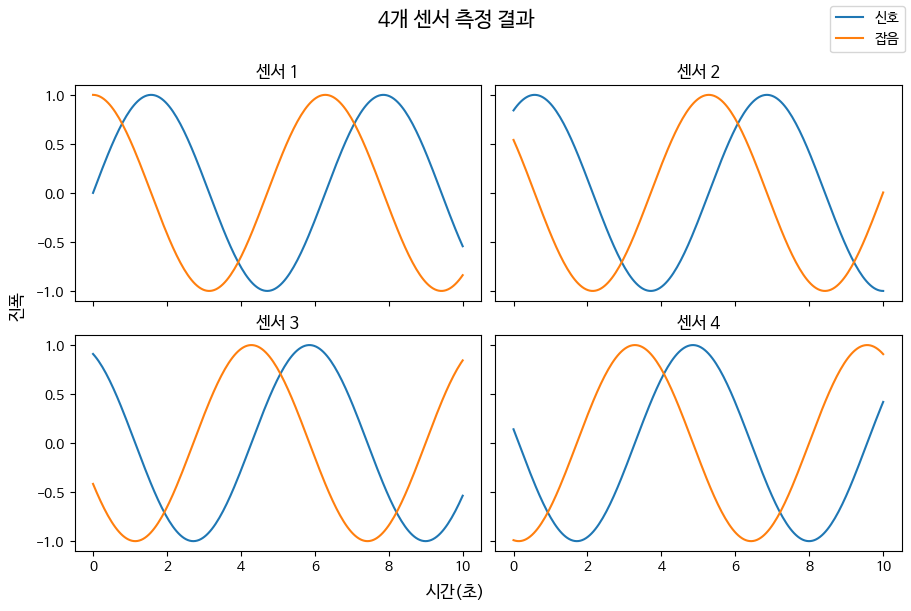

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True,
                         constrained_layout=True)

handles = None
for i, ax in enumerate(axes.flatten()):
    l1, = ax.plot(t, np.sin(t + i), label='신호')
    l2, = ax.plot(t, np.cos(t + i), label='잡음')
    ax.set_title(f'센서 {i+1}')
    handles = [l1, l2]

fig.suptitle('4개 센서 측정 결과', fontsize=15)
fig.supxlabel('시간(초)')
fig.supylabel('진폭')
fig.legend(handles=handles, loc='outside upper right')   # 그림 전체 범례
plt.show()

---

# Part 6. pandas 연동 실전

실무 데이터는 거의 항상 **DataFrame**에 들어 있습니다. Matplotlib과 pandas를 어떻게 이어 붙이는지가 실전의 핵심입니다.

## 6.1 예제 데이터 만들기

(인터넷 없이 재현 가능하도록 직접 생성합니다)

In [78]:
n_rows = 2000
dates = pd.date_range('2023-01-01', periods=n_rows, freq='h')

df = pd.DataFrame({
    'datetime': dates,
    'region': rng.choice(['수도권', '영남', '호남', '충청', '강원'], n_rows, p=[.4, .25, .15, .15, .05]),
    'category': rng.choice(['가전', '의류', '식품', '도서'], n_rows, p=[.2, .3, .35, .15]),
    'channel': rng.choice(['온라인', '오프라인'], n_rows, p=[.65, .35]),
    'quantity': rng.integers(1, 8, n_rows),
})
base_price = {'가전': 250000, '의류': 45000, '식품': 15000, '도서': 18000}
df['unit_price'] = df['category'].map(base_price) * rng.normal(1, 0.15, n_rows)
df['amount'] = (df['unit_price'] * df['quantity']).round(0)
df['date'] = df['datetime'].dt.date
df['month'] = df['datetime'].dt.to_period('M').astype(str)
df['weekday'] = df['datetime'].dt.dayofweek

print(df.shape)
df.head()

(2000, 10)


,datetime,region,category,channel,quantity,unit_price,amount,date,month,weekday
0,2023-01-01 00:00:00,수도권,가전,온라인,6,237476.463778,1424859.0,2023-01-01,2023-01,6
1,2023-01-01 01:00:00,수도권,식품,오프라인,1,16737.455669,16737.0,2023-01-01,2023-01,6
2,2023-01-01 02:00:00,수도권,식품,온라인,6,14673.218421,88039.0,2023-01-01,2023-01,6
3,2023-01-01 03:00:00,호남,식품,오프라인,3,15904.102396,47712.0,2023-01-01,2023-01,6
4,2023-01-01 04:00:00,수도권,식품,오프라인,2,16553.639076,33107.0,2023-01-01,2023-01,6


## 6.2 `df.plot()` — 빠른 탐색용

pandas의 `.plot()` 은 내부적으로 Matplotlib을 호출합니다. **탐색 단계에서는 이게 훨씬 빠릅니다.**

| `kind` | 차트 |
|---|---|
| `'line'` | 선 (기본) |
| `'bar'`, `'barh'` | 막대 |
| `'hist'` | 히스토그램 |
| `'box'` | 박스플롯 |
| `'scatter'` | 산점도 |
| `'pie'` | 파이 |
| `'area'` | 누적 면적 |

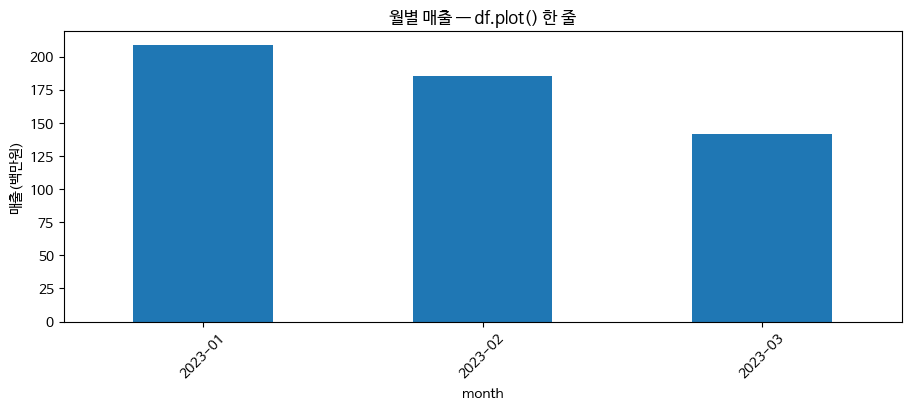

In [79]:
monthly = df.groupby('month')['amount'].sum() / 1e6

ax = monthly.plot(kind='bar', figsize=(9, 4), color='tab:blue', rot=45)
ax.set(ylabel='매출(백만원)', title='월별 매출 — df.plot() 한 줄')
plt.show()

## 6.3 `ax=` 로 두 세계를 잇기 (가장 중요)

`df.plot(ax=ax)` 처럼 **내가 만든 Axes를 넘기면**, pandas가 그린 그래프를 Matplotlib 방식으로 마음껏 손볼 수 있습니다. seaborn도 동일합니다.

> 이것이 1권에서 객체지향 API를 배운 이유입니다.

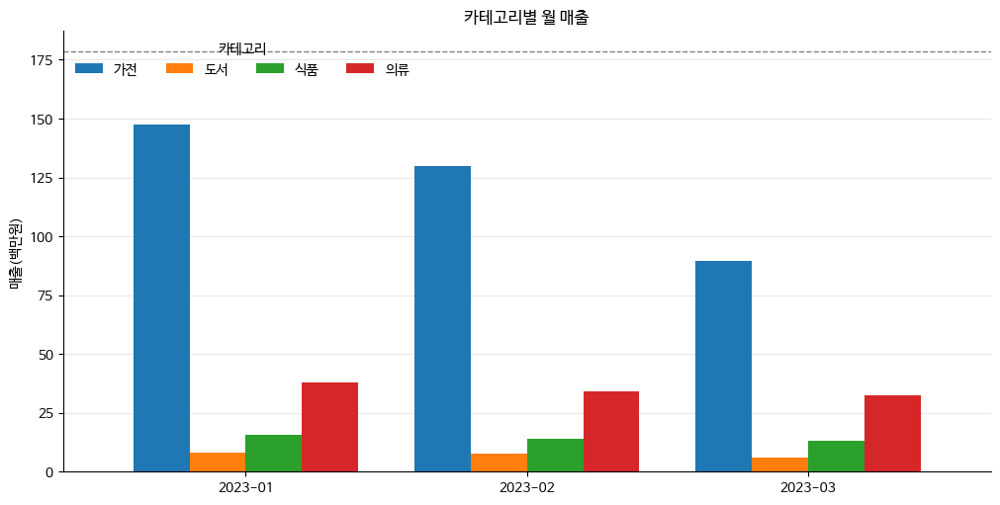

In [80]:
pivot = df.pivot_table(index='month', columns='category', values='amount', aggfunc='sum') / 1e6

fig, ax = plt.subplots(figsize=(10, 5))

pivot.plot(kind='bar', ax=ax, width=0.8)          # pandas가 그리고

# 이후는 전부 Matplotlib으로 다듬기
ax.set(xlabel='', ylabel='매출(백만원)', title='카테고리별 월 매출')
ax.tick_params(axis='x', labelrotation=0)
ax.legend(title='카테고리', ncol=4, loc='upper left', frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.axhline(pivot.sum(axis=1).mean(), color='gray', ls='--', lw=1)
plt.show()

## 6.4 시계열 축 다루기

날짜 축은 라벨이 겹치기 쉽습니다. `matplotlib.dates` 로 제어합니다.

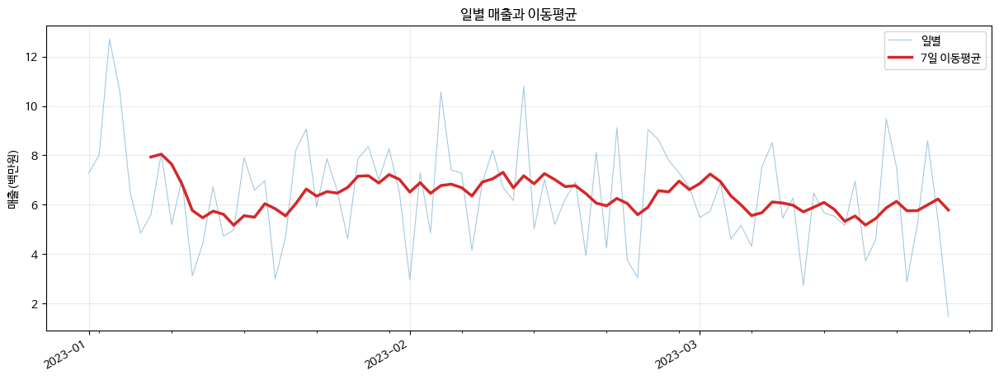

In [81]:
import matplotlib.dates as mdates

daily = df.set_index('datetime')['amount'].resample('D').sum() / 1e6
rolling7 = daily.rolling(7).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.values, lw=0.8, alpha=0.4, color='tab:blue', label='일별')
ax.plot(rolling7.index, rolling7.values, lw=2.5, color='tab:red', label='7일 이동평균')

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_minor_locator(mdates.WeekdayLocator(byweekday=mdates.MO))

ax.set(ylabel='매출(백만원)', title='일별 매출과 이동평균')
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()                 # 날짜 라벨 자동 회전
plt.show()

### 자주 쓰는 날짜 포맷

| 코드 | 결과 |
|---|---|
| `%Y-%m-%d` | 2024-03-15 |
| `%y/%m` | 24/03 |
| `%m월 %d일` | 03월 15일 |
| `%H:%M` | 14:30 |

### Locator 종류
`YearLocator`, `MonthLocator`, `WeekdayLocator`, `DayLocator`, `HourLocator`, `AutoDateLocator`

## 6.5 groupby 결과 시각화 패턴 모음

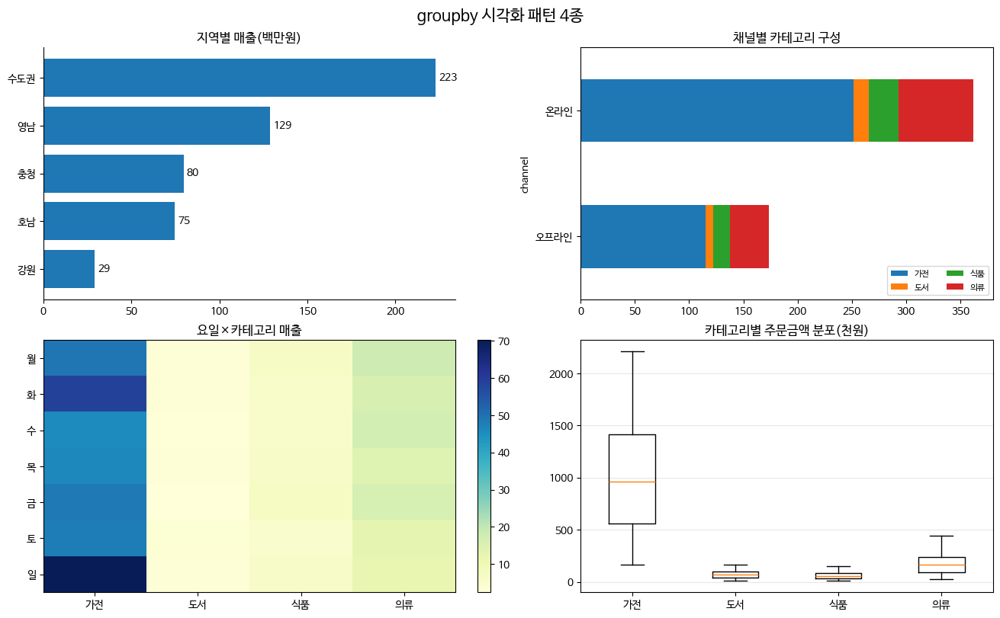

In [82]:
fig, axd = plt.subplot_mosaic('AB\nCD', figsize=(13, 8), constrained_layout=True)

# A. 지역별 매출 (정렬된 가로 막대)
by_region = df.groupby('region')['amount'].sum().sort_values() / 1e6
bars = axd['A'].barh(by_region.index, by_region.values, color='tab:blue')
axd['A'].bar_label(bars, fmt='%.0f', padding=3)
axd['A'].set_title('지역별 매출(백만원)')
axd['A'].spines[['top', 'right']].set_visible(False)

# B. 채널별 카테고리 구성 (누적 막대)
ch = df.pivot_table(index='channel', columns='category', values='amount', aggfunc='sum') / 1e6
ch.plot(kind='barh', stacked=True, ax=axd['B'])
axd['B'].set_title('채널별 카테고리 구성')
axd['B'].legend(fontsize=8, ncol=2)

# C. 요일×카테고리 히트맵
wd = df.pivot_table(index='weekday', columns='category', values='amount', aggfunc='sum') / 1e6
im = axd['C'].imshow(wd.values, cmap='YlGnBu', aspect='auto')
axd['C'].set_xticks(range(len(wd.columns)), wd.columns)
axd['C'].set_yticks(range(7), ['월', '화', '수', '목', '금', '토', '일'])
axd['C'].set_title('요일×카테고리 매출')
fig.colorbar(im, ax=axd['C'])

# D. 카테고리별 주문금액 분포 (박스플롯)
groups = [g['amount'].values / 1000 for _, g in df.groupby('category')]
axd['D'].boxplot(groups, tick_labels=list(df.groupby('category').groups.keys()), showfliers=False)
axd['D'].set_title('카테고리별 주문금액 분포(천원)')
axd['D'].grid(axis='y', alpha=0.3)

fig.suptitle('groupby 시각화 패턴 4종', fontsize=15)
plt.show()

## 6.6 DataFrame 산점도 행렬 (빠른 상관 탐색)

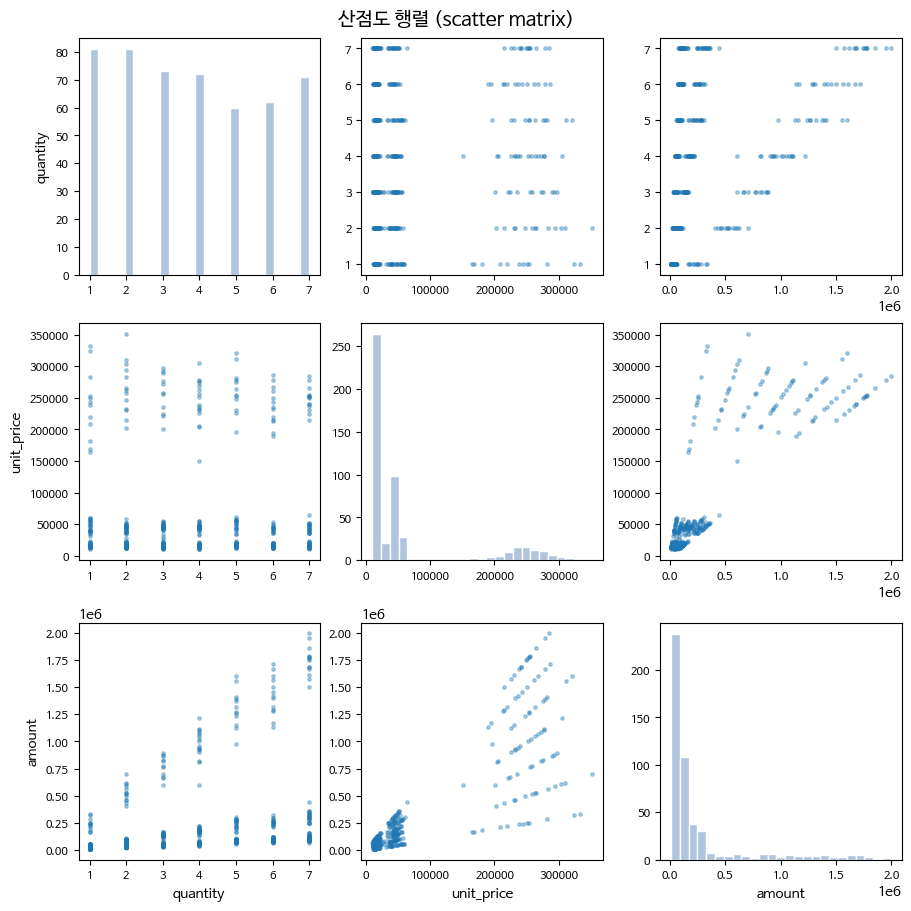

In [83]:
num_df = df[['quantity', 'unit_price', 'amount']].sample(500, random_state=0)

cols = num_df.columns
fig, axes = plt.subplots(len(cols), len(cols), figsize=(9, 9), constrained_layout=True)

for i, ci in enumerate(cols):
    for j, cj in enumerate(cols):
        ax = axes[i, j]
        if i == j:
            ax.hist(num_df[ci], bins=25, color='lightsteelblue', edgecolor='white')
        else:
            ax.scatter(num_df[cj], num_df[ci], s=6, alpha=0.35, color='tab:blue')
        if i == len(cols) - 1:
            ax.set_xlabel(cj)
        if j == 0:
            ax.set_ylabel(ci)
        ax.tick_params(labelsize=8)

fig.suptitle('산점도 행렬 (scatter matrix)', fontsize=14)
plt.show()

In [84]:
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

def set_korean_font():
    s = platform.system()
    family = 'Malgun Gothic' if s == 'Windows' else ('AppleGothic' if s == 'Darwin' else 'NanumBarunGothic')
    plt.rcParams['font.family'] = family
    plt.rcParams['axes.unicode_minus'] = False
    return family

print('폰트:', set_korean_font(), '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(42)
x = np.linspace(0, 10, 200)

폰트: NanumBarunGothic | matplotlib 3.10.0


---

# Part 7. 실무 팁

## 7.1 rcParams — 전역 기본값 바꾸기

매번 `figsize=(10,5)`, `grid(alpha=0.3)` 을 쓰는 게 지겹다면, **기본값 자체를 바꾸면** 됩니다.

`plt.rcParams` 는 Matplotlib의 모든 기본 설정이 담긴 딕셔너리입니다.

In [85]:
print('전체 설정 개수:', len(plt.rcParams))
for k in ['figure.figsize', 'figure.dpi', 'font.size', 'lines.linewidth',
          'axes.grid', 'axes.titlesize', 'legend.frameon']:
    print(f'{k:22s} = {plt.rcParams[k]}')

전체 설정 개수: 322
figure.figsize         = [6.4, 4.8]
figure.dpi             = 100.0
font.size              = 10.0
lines.linewidth        = 1.5
axes.grid              = False
axes.titlesize         = large
legend.frameon         = True


### 자주 바꾸는 설정

| 키 | 뜻 |
|---|---|
| `figure.figsize` | 기본 그림 크기 |
| `figure.dpi` | 화면 해상도 |
| `savefig.dpi` | 저장 해상도 |
| `font.family`, `font.size` | 폰트 |
| `axes.titlesize`, `axes.labelsize` | 제목·라벨 크기 |
| `axes.grid`, `grid.alpha` | 그리드 기본값 |
| `axes.spines.top`, `axes.spines.right` | 테두리 표시 |
| `axes.prop_cycle` | 컬러 사이클 |
| `lines.linewidth`, `lines.markersize` | 선·마커 |
| `legend.frameon` | 범례 테두리 |

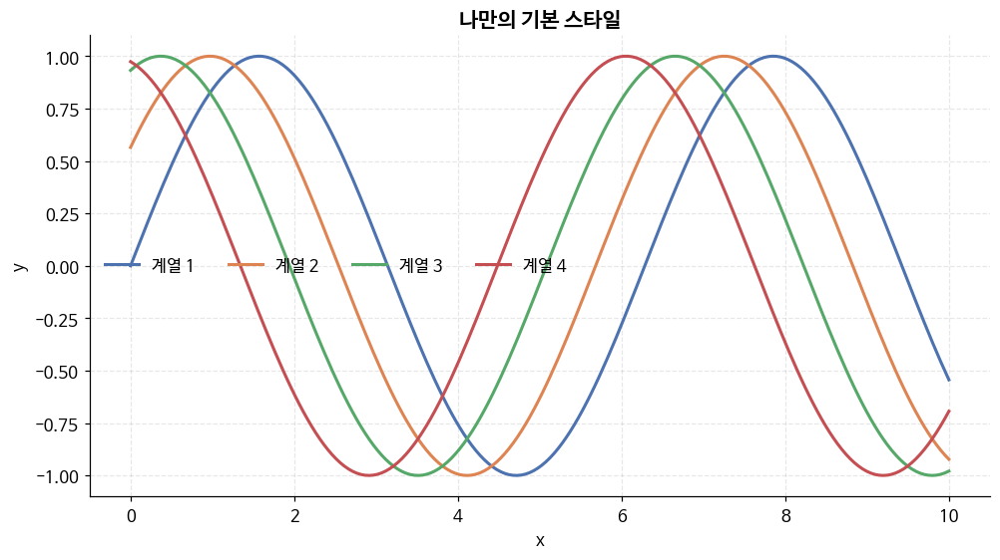

In [86]:
from cycler import cycler

# 나만의 기본 스타일 정의 — 노트북 맨 위에 한 번만 실행
MY_STYLE = {
    'figure.figsize': (9, 5),
    'figure.dpi': 110,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.grid': True,
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.prop_cycle': cycler(color=['#4C72B0', '#DD8452', '#55A868',
                                     '#C44E52', '#8172B3', '#937860']),
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'lines.linewidth': 2.0,
    'legend.frameon': False,
    'axes.unicode_minus': False,
}

plt.rcParams.update(MY_STYLE)
set_korean_font()          # 폰트는 다시 잡아줌

fig, ax = plt.subplots()
for i in range(4):
    ax.plot(x, np.sin(x + i * 0.6), label=f'계열 {i+1}')
ax.set(title='나만의 기본 스타일', xlabel='x', ylabel='y')
ax.legend(ncol=4)
plt.show()

### 일시적으로만 적용하기 — `rc_context`

전역 설정을 건드리지 않고 **이 블록 안에서만** 바꿉니다.

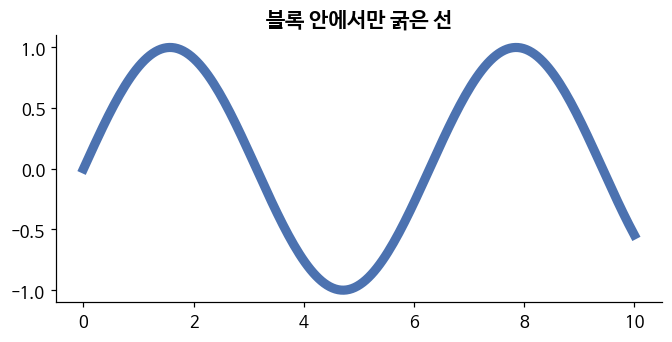

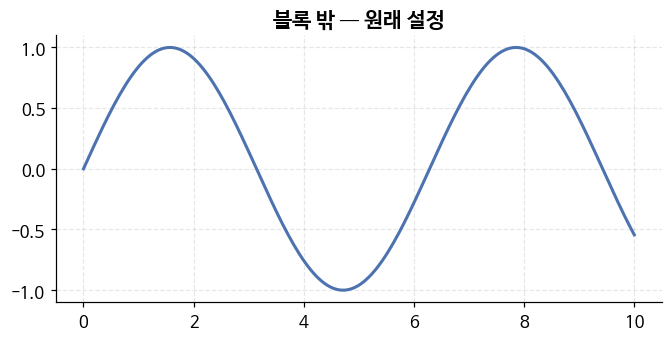

In [87]:
with plt.rc_context({'lines.linewidth': 6, 'axes.grid': False, 'figure.figsize': (6, 3)}):
    fig, ax = plt.subplots()
    ax.plot(x, np.sin(x))
    ax.set_title('블록 안에서만 굵은 선')
    plt.show()

# 블록을 나오면 원래대로
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, np.sin(x))
ax.set_title('블록 밖 — 원래 설정')
plt.show()

In [88]:
# 완전 초기화가 필요할 때
# plt.rcdefaults()      # 공장 초기화 (한글 폰트 설정도 날아감)
# set_korean_font()     # 그래서 다시 잡아줘야 함

## 7.2 스타일 시트 — 남이 만든 테마 쓰기

`plt.style.use()` 로 미리 만들어진 테마를 한 줄에 적용합니다.

In [89]:
print(len(plt.style.available), '개 스타일 사용 가능')
print(plt.style.available[:20])

29 개 스타일 사용 가능
['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted']


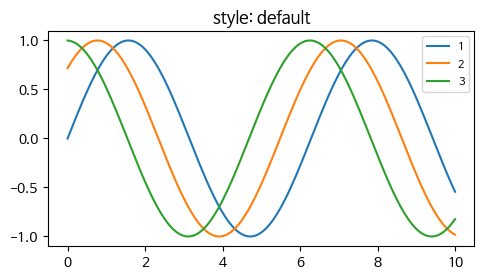

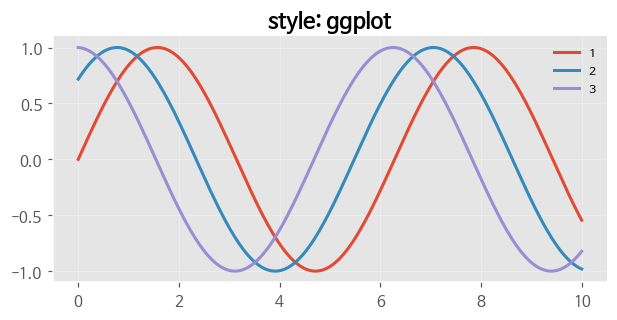

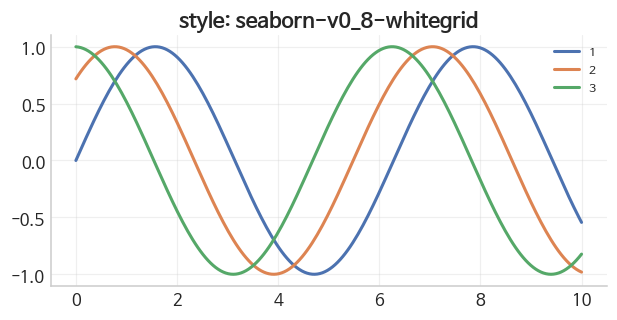

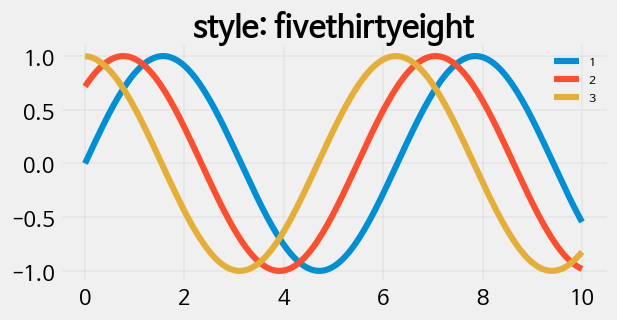

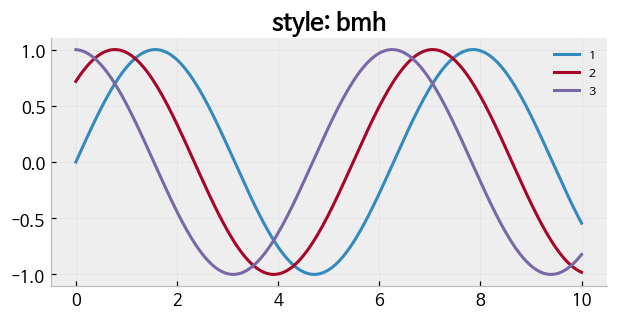

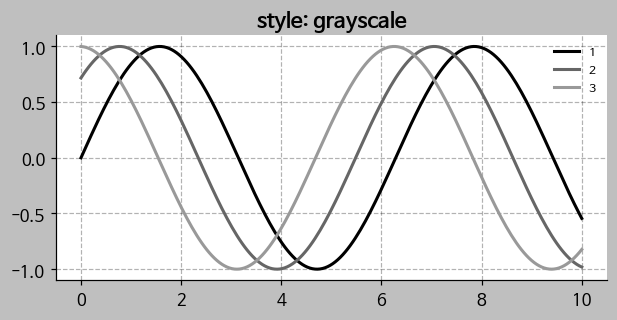

In [90]:
demo_styles = ['default', 'ggplot', 'seaborn-v0_8-whitegrid', 'fivethirtyeight', 'bmh', 'grayscale']

for s in demo_styles:
    if s not in plt.style.available and s != 'default':
        continue
    with plt.style.context(s):
        set_korean_font()
        fig, ax = plt.subplots(figsize=(5.5, 2.8))
        for i in range(3):
            ax.plot(x, np.sin(x + i * 0.8), label=f'{i+1}')
        ax.set_title(f"style: {s}")
        ax.legend(fontsize=8)
        plt.show()

> **주의:** 스타일을 적용하면 `font.family` 가 초기화되어 **한글이 다시 깨집니다.** 스타일 적용 후 항상 `set_korean_font()` 를 다시 호출하세요.
>
> 스타일은 겹쳐 쓸 수도 있습니다: `plt.style.use(['seaborn-v0_8-whitegrid', {'font.size': 13}])`

In [91]:
plt.rcParams.update(MY_STYLE)
set_korean_font()
print('내 스타일로 복귀')

내 스타일로 복귀


## 7.3 저장하기 — `savefig()` 제대로 쓰기

**보고서에 붙였더니 글씨가 잘렸다 / 흐릿하다** 는 문제는 대부분 여기서 해결됩니다.

| 인자 | 권장값 | 이유 |
|---|---|---|
| `dpi` | 화면 100, 인쇄 300 | 해상도 |
| `bbox_inches` | `'tight'` | **잘림 방지 (거의 필수)** |
| `pad_inches` | 0.1 ~ 0.3 | 여백 |
| `transparent` | 슬라이드에 얹을 땐 True | 배경 투명 |
| `facecolor` | `'white'` | 다크모드에서 배경 검게 저장되는 것 방지 |

### 확장자 선택

| 포맷 | 특징 | 언제 |
|---|---|---|
| **PNG** | 래스터, 무손실 | 웹, 슬라이드, 기본 선택 |
| **SVG** | 벡터, 무한 확대 | 웹, 편집이 필요할 때 |
| **PDF** | 벡터 | 논문·인쇄 |
| JPG | 손실 압축 | 그래프에는 부적합 (글자가 뭉개짐) |

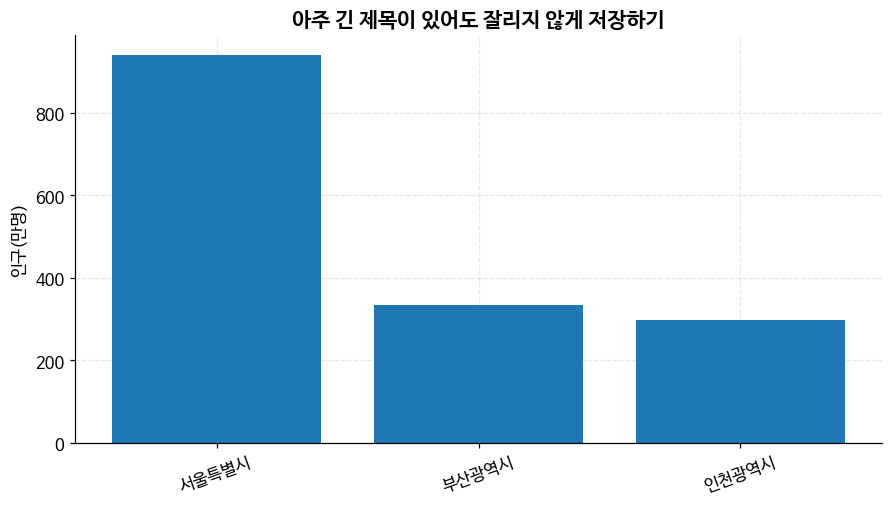

저장 완료: chart_web.png / chart_print.pdf / chart_slide.png


In [92]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(['서울특별시', '부산광역시', '인천광역시'], [941, 334, 297], color='tab:blue')
ax.set(ylabel='인구(만명)', title='아주 긴 제목이 있어도 잘리지 않게 저장하기')
ax.tick_params(axis='x', labelrotation=20)

# 잘림 없이 고해상도 저장
fig.savefig('chart_web.png', dpi=150, bbox_inches='tight', facecolor='white')
fig.savefig('chart_print.pdf', bbox_inches='tight')
fig.savefig('chart_slide.png', dpi=200, bbox_inches='tight', transparent=True)

plt.show()
print('저장 완료: chart_web.png / chart_print.pdf / chart_slide.png')

> **순서 주의:** `plt.show()` 를 먼저 부르면 Figure가 비워져 **빈 이미지가 저장**됩니다. 반드시 `savefig()` → `show()` 순서로 쓰세요.

### 여러 그래프를 PDF 한 파일로

In [93]:
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages('report.pdf') as pdf:
    for i, name in enumerate(['1분기', '2분기', '3분기', '4분기']):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.plot(x, np.sin(x + i), lw=2)
        ax.set_title(f'{name} 리포트')
        pdf.savefig(fig, bbox_inches='tight')
        plt.close(fig)              # 메모리 해제 (반복문에서 중요)

print('report.pdf 생성 — 4페이지')

report.pdf 생성 — 4페이지


> **반복문에서 Figure를 많이 만들 때는 `plt.close(fig)` 를 꼭 호출하세요.** 안 하면 메모리에 쌓여 경고가 뜨고 느려집니다.

## 7.4 색 접근성 — 색맹 사용자를 고려하기

남성의 약 8%가 적록색약입니다. **빨강-초록 대비만으로 정보를 구분하면 안 됩니다.**

### 세 가지 원칙

1. **색 외에 두 번째 단서**를 주기 — 선 모양, 마커, 직접 라벨
2. **색맹 안전 팔레트** 사용 — `tab10`, `Set2`, `viridis`, Okabe-Ito
3. **명도 차이**를 두기 — 흑백 인쇄해도 구분되면 성공

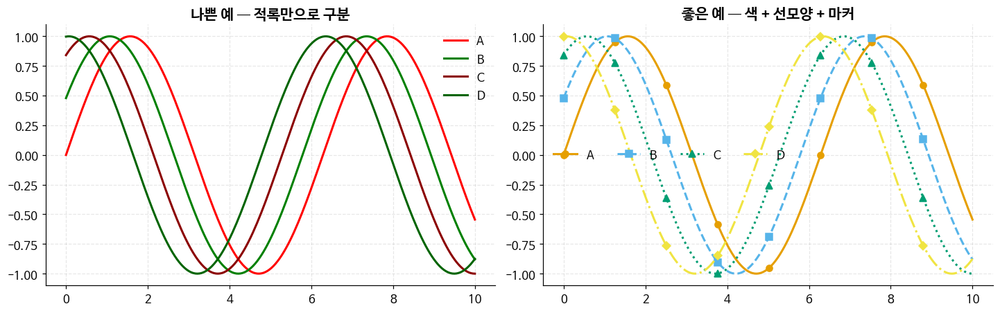

In [94]:
# Okabe-Ito 팔레트 — 색각 이상에서도 구분되도록 설계된 8색
OKABE_ITO = ['#000000', '#E69F00', '#56B4E9', '#009E73',
             '#F0E442', '#0072B2', '#D55E00', '#CC79A7']

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)

# 나쁜 예: 색만으로 구분
for i in range(4):
    axes[0].plot(x, np.sin(x + i * 0.5), color=['red', 'green', 'darkred', 'darkgreen'][i], lw=2)
axes[0].set_title('나쁜 예 — 적록만으로 구분')
axes[0].legend(['A', 'B', 'C', 'D'])

# 좋은 예: 색 + 선모양 + 마커
styles = ['-', '--', ':', '-.']
markers = ['o', 's', '^', 'D']
for i in range(4):
    axes[1].plot(x, np.sin(x + i * 0.5), color=OKABE_ITO[i + 1], lw=2,
                 ls=styles[i], marker=markers[i], markevery=25, label=f'{chr(65+i)}')
axes[1].set_title('좋은 예 — 색 + 선모양 + 마커')
axes[1].legend(ncol=4)

plt.show()

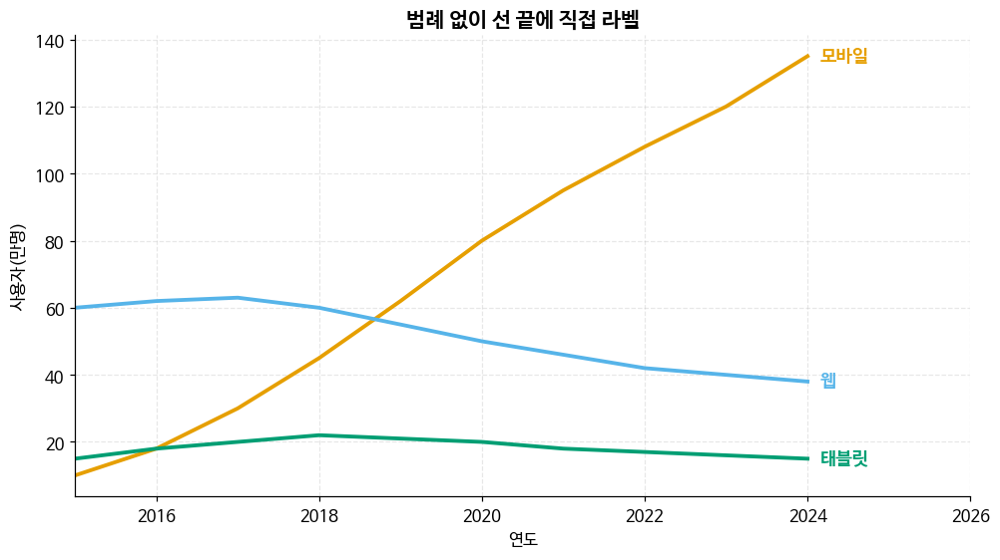

In [95]:
# 범례 대신 선 끝에 직접 라벨 달기 (가독성 최고)
series = {'모바일': np.array([10, 18, 30, 45, 62, 80, 95, 108, 120, 135]),
          '웹': np.array([60, 62, 63, 60, 55, 50, 46, 42, 40, 38]),
          '태블릿': np.array([15, 18, 20, 22, 21, 20, 18, 17, 16, 15])}
yrs = np.arange(2015, 2025)

fig, ax = plt.subplots(figsize=(9, 5))
for (name, vals), c in zip(series.items(), OKABE_ITO[1:]):
    ax.plot(yrs, vals, lw=2.5, color=c)
    ax.text(yrs[-1] + 0.15, vals[-1], name, color=c, va='center', fontsize=12, weight='bold')

ax.set(xlim=(2015, 2026), xlabel='연도', ylabel='사용자(만명)',
       title='범례 없이 선 끝에 직접 라벨')
plt.show()

## 7.5 자주 하는 실수 TOP 12

| # | 증상 | 원인 | 해결 |
|---|---|---|---|
| 1 | 한글이 □□□ | 폰트 미설정 | `plt.rcParams['font.family']` 지정 |
| 2 | 마이너스가 □ | 유니코드 마이너스 | `axes.unicode_minus = False` |
| 3 | 저장한 그림이 잘림 | 여백 계산 안 됨 | `savefig(..., bbox_inches='tight')` |
| 4 | 저장한 그림이 빈 종이 | `show()` 후 `savefig()` | **순서를 바꾸기** |
| 5 | 글자가 겹침 | 레이아웃 미조정 | `constrained_layout=True` |
| 6 | 범례가 안 나옴 | `label=` 누락 | `plot(..., label='x')` 후 `legend()` |
| 7 | 그래프가 계속 겹쳐 그려짐 | 같은 Figure 재사용 | 새 셀마다 `fig, ax = plt.subplots()` |
| 8 | 반복문에서 메모리 경고 | Figure 미해제 | `plt.close(fig)` |
| 9 | 그리드가 막대를 덮음 | 그리기 순서 | `ax.set_axisbelow(True)` |
| 10 | 그림이 흐릿함 | dpi 낮음 | `savefig(dpi=200)` |
| 11 | 스타일 적용 후 한글 깨짐 | 스타일이 폰트 초기화 | 스타일 뒤에 폰트 재설정 |
| 12 | 축이 `1e6` 같은 지수로 표시 | 자동 offset | `ax.ticklabel_format(style='plain')` 또는 Formatter |

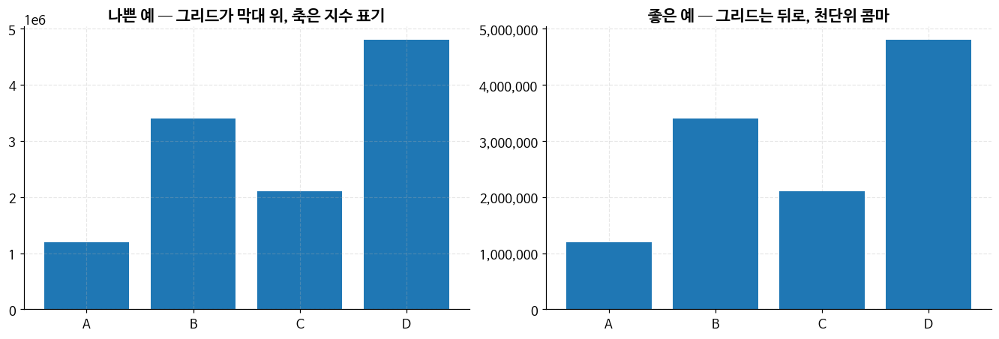

In [96]:
# #9, #12 시연
big_vals = np.array([1_200_000, 3_400_000, 2_100_000, 4_800_000])
names = ['A', 'B', 'C', 'D']

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].bar(names, big_vals, color='tab:blue')
axes[0].grid(True)
axes[0].set_axisbelow(False)
axes[0].set_title('나쁜 예 — 그리드가 막대 위, 축은 지수 표기')

axes[1].bar(names, big_vals, color='tab:blue')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_axisbelow(True)
axes[1].ticklabel_format(axis='y', style='plain')
axes[1].yaxis.set_major_formatter(lambda v, pos: f'{v:,.0f}')
axes[1].set_title('좋은 예 — 그리드는 뒤로, 천단위 콤마')

plt.show()

## 7.6 좋은 그래프 체크리스트

발표·제출 전에 이 목록을 훑어보세요.

- [ ] **제목이 결론을 말하는가?** (`매출 추이` ❌ → `4분기 매출 전년비 32% 증가` ✅)
- [ ] 축 라벨에 **단위**가 있는가? (`매출(백만원)`)
- [ ] 막대 그래프의 y축이 **0에서 시작**하는가?
- [ ] 범례가 데이터를 가리지 않는가? 또는 **직접 라벨**로 대체했는가?
- [ ] 색이 **8가지 이하**인가? (그 이상이면 구분 불가)
- [ ] 흑백으로 인쇄해도 구분되는가?
- [ ] 강조하고 싶은 것만 **진한 색**, 나머지는 회색인가?
- [ ] 불필요한 테두리·그리드·3D 효과를 지웠는가?
- [ ] 데이터 출처와 기준일을 적었는가?
- [ ] 폰트 크기가 **발표 화면에서 읽히는가?** (최소 11pt)

## 7.7 Matplotlib vs 다른 도구

| 도구 | 장점 | 단점 | 추천 상황 |
|---|---|---|---|
| **Matplotlib** | 무엇이든 그릴 수 있음, 완전한 제어 | 코드가 길다 | 논문, 보고서, 정밀 제어 |
| **pandas .plot()** | 한 줄이면 끝 | 커스터마이징 제한 | 탐색적 분석 |
| **seaborn** | 통계 그래프가 예쁘고 짧다 | Matplotlib 위에서만 동작 | 분포·관계 탐색 |
| **Plotly** | 마우스 인터랙션, 웹 | 파일이 무겁다 | 대시보드, 공유 |

> 실무 흐름: **탐색은 `df.plot()` 이나 seaborn → 최종본은 Matplotlib으로 다듬기.** 셋 다 `ax=` 로 연결되므로 배운 것이 전부 쓰입니다.

---

# Part 8. 종합 프로젝트 — 매출 대시보드

지금까지 배운 것을 전부 써서 **한 장짜리 보고용 대시보드**를 만듭니다.

**단계**
1. 데이터 준비
2. 레이아웃 설계 (`subplot_mosaic`)
3. 각 패널 그리기
4. 강조·주석으로 메시지 넣기
5. 저장

In [97]:
# 1단계: 데이터 준비
n_rows = 3000
dates = pd.date_range('2024-01-01', periods=n_rows, freq='3h')

df = pd.DataFrame({
    'datetime': dates,
    'region': rng.choice(['수도권', '영남', '호남', '충청', '강원'], n_rows, p=[.42, .24, .15, .14, .05]),
    'category': rng.choice(['가전', '의류', '식품', '도서'], n_rows, p=[.2, .3, .35, .15]),
    'channel': rng.choice(['온라인', '오프라인'], n_rows, p=[.68, .32]),
    'quantity': rng.integers(1, 8, n_rows),
})
base_price = {'가전': 250000, '의류': 45000, '식품': 15000, '도서': 18000}
df['amount'] = (df['category'].map(base_price) * rng.normal(1, 0.15, n_rows) * df['quantity']).round()
df['month'] = df['datetime'].dt.to_period('M').astype(str)

# 성장 추세 부여
trend = 1 + (df['datetime'] - df['datetime'].min()).dt.days / 365 * 0.4
df['amount'] = (df['amount'] * trend).round()

total = df['amount'].sum()
print(f'기간: {df.datetime.min():%Y-%m-%d} ~ {df.datetime.max():%Y-%m-%d}')
print(f'총 매출: {total/1e8:.1f}억원, 주문 {len(df):,}건')

기간: 2024-01-01 ~ 2025-01-09
총 매출: 10.5억원, 주문 3,000건


In [98]:
# 2단계: 집계
monthly   = df.groupby('month')['amount'].sum() / 1e6
by_region = df.groupby('region')['amount'].sum().sort_values() / 1e6
by_cat    = df.groupby('category')['amount'].sum() / 1e6
ch_month  = df.pivot_table(index='month', columns='channel', values='amount', aggfunc='sum') / 1e6
daily     = df.set_index('datetime')['amount'].resample('D').sum() / 1e6

mom = (monthly.iloc[-1] / monthly.iloc[-2] - 1) * 100
print(f'최근 월 매출 {monthly.iloc[-1]:.0f}백만원 (전월비 {mom:+.1f}%)')

최근 월 매출 25백만원 (전월비 -75.3%)


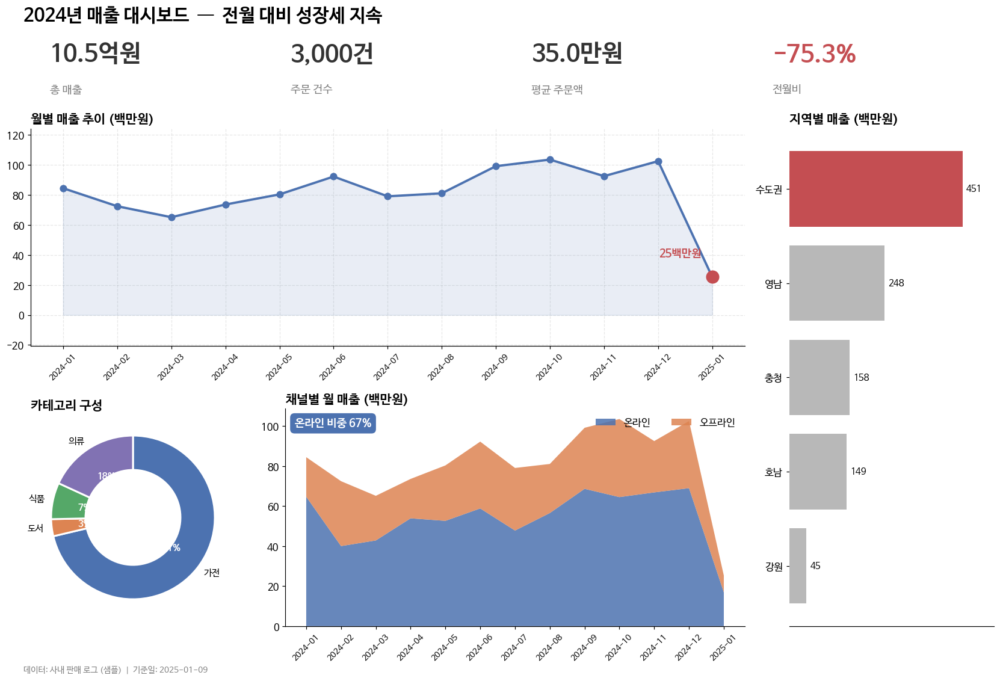

저장: sales_dashboard.png


In [99]:
# 3~5단계: 대시보드 그리기
plt.rcParams.update(MY_STYLE)
set_korean_font()

ACCENT = '#C44E52'
MUTED  = '#B8B8B8'

fig, axd = plt.subplot_mosaic(
    '''
    TTTT
    AAAB
    CDDB
    ''',
    figsize=(15, 10),
    height_ratios=[0.35, 1, 1],
    constrained_layout=True,
)

# ---- T: 헤더(KPI) ----
ax = axd['T']
ax.axis('off')
kpis = [
    ('총 매출', f'{total/1e8:.1f}억원'),
    ('주문 건수', f'{len(df):,}건'),
    ('평균 주문액', f'{df.amount.mean()/1e4:.1f}만원'),
    ('전월비', f'{mom:+.1f}%'),
]
for i, (label, value) in enumerate(kpis):
    xpos = 0.02 + i * 0.25
    ax.text(xpos, 0.62, value, fontsize=26, weight='bold',
            color=ACCENT if i == 3 else '#333333', transform=ax.transAxes)
    ax.text(xpos, 0.20, label, fontsize=12, color='gray', transform=ax.transAxes)

# ---- A: 월별 매출 추이 ----
ax = axd['A']
ax.plot(monthly.index, monthly.values, 'o-', color='#4C72B0', lw=2.5, markersize=7)
ax.fill_between(range(len(monthly)), monthly.values, alpha=0.12, color='#4C72B0')
ax.scatter([len(monthly)-1], [monthly.iloc[-1]], s=180, color=ACCENT, zorder=5)
ax.annotate(f'{monthly.iloc[-1]:.0f}백만원',
            xy=(len(monthly)-1, monthly.iloc[-1]),
            xytext=(-12, 22), textcoords='offset points',
            fontsize=12, color=ACCENT, weight='bold', ha='right')
ax.set_title('월별 매출 추이 (백만원)', loc='left')
ax.tick_params(axis='x', labelrotation=45, labelsize=9)
ax.margins(y=0.2)

# ---- B: 지역별 매출 (정렬 가로막대, 1위 강조) ----
ax = axd['B']
colors = [MUTED] * len(by_region)
colors[-1] = ACCENT
bars = ax.barh(by_region.index, by_region.values, color=colors)
ax.bar_label(bars, fmt='%.0f', padding=4, fontsize=10)
ax.set_title('지역별 매출 (백만원)', loc='left')
ax.grid(False)
ax.set_xticks([])
ax.spines['left'].set_visible(False)
ax.margins(x=0.18)

# ---- C: 카테고리 구성 (도넛) ----
ax = axd['C']
wedges, texts, autotexts = ax.pie(
    by_cat.values, labels=by_cat.index, autopct='%.0f%%',
    startangle=90, counterclock=False,
    colors=['#4C72B0', '#DD8452', '#55A868', '#8172B3'],
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10))
for t in autotexts:
    t.set_color('white'); t.set_weight('bold')
ax.set_title('카테고리 구성', loc='left')

# ---- D: 채널별 월 매출 (누적 영역) ----
ax = axd['D']
ax.stackplot(range(len(ch_month)), ch_month['온라인'], ch_month['오프라인'],
             labels=['온라인', '오프라인'], colors=['#4C72B0', '#DD8452'], alpha=0.85)
ax.set_xticks(range(len(ch_month)))
ax.set_xticklabels(ch_month.index, rotation=45, fontsize=9)
online_share = ch_month['온라인'].sum() / ch_month.sum().sum() * 100
ax.text(0.02, 0.92, f'온라인 비중 {online_share:.0f}%', transform=ax.transAxes,
        fontsize=12, weight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#4C72B0', edgecolor='none'))
ax.set_title('채널별 월 매출 (백만원)', loc='left')
ax.legend(loc='upper right', ncol=2)
ax.grid(False)

# ---- 전체 제목 / 출처 ----
fig.suptitle('2024년 매출 대시보드  —  전월 대비 성장세 지속', fontsize=20, weight='bold', x=0.02, ha='left')
fig.text(0.02, -0.01, f'데이터: 사내 판매 로그 (샘플)  |  기준일: {df.datetime.max():%Y-%m-%d}',
         fontsize=9, color='gray')

fig.savefig('sales_dashboard.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('저장: sales_dashboard.png')

### 이 대시보드에 쓰인 기법 정리

| 기법 | 어디에 |
|---|---|
| `subplot_mosaic` + `height_ratios` | 전체 레이아웃 |
| `ax.axis('off')` + `transAxes` 텍스트 | KPI 헤더 |
| `fill_between`, `scatter`, `annotate` | 추세 패널 강조 |
| 회색 처리 + 1색 강조 | 지역별 막대 |
| `bar_label`, `spines` 제거, `set_xticks([])` | 군더더기 제거 |
| `wedgeprops(width=)` | 도넛 |
| `stackplot` + `bbox` 라벨 | 채널 구성 |
| 결론이 담긴 제목 | `suptitle` |
| `savefig(dpi, bbox_inches, facecolor)` | 저장 |

---

# 부록 A. 치트시트

## A.1 기본 뼈대
```python
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.plot(x, y, label='계열1')
ax.set(title='제목', xlabel='x', ylabel='y', xlim=(0, 10), ylim=(0, 1))
ax.legend()
ax.grid(alpha=0.3)
fig.savefig('out.png', dpi=200, bbox_inches='tight')
plt.show()
```

## A.2 차트 함수
| 목적 | 코드 |
|---|---|
| 선 | `ax.plot(x, y)` |
| 막대 | `ax.bar(x, h)` / `ax.barh(y, w)` |
| 산점도 | `ax.scatter(x, y, s=, c=, cmap=)` |
| 히스토그램 | `ax.hist(v, bins=30)` |
| 박스 | `ax.boxplot([a, b])` |
| 바이올린 | `ax.violinplot([a, b])` |
| 파이 | `ax.pie(v, labels=, autopct='%.1f%%')` |
| 히트맵 | `ax.imshow(m, cmap='viridis')` |
| 에러바 | `ax.errorbar(x, y, yerr=e, fmt='o', capsize=5)` |
| 면적 | `ax.fill_between(x, y1, y2)` / `ax.stackplot(x, a, b)` |
| 2D 밀도 | `ax.hexbin(x, y)` / `ax.hist2d(x, y)` |

## A.3 꾸미기
| 목적 | 코드 |
|---|---|
| 제목/라벨 | `ax.set_title()`, `ax.set_xlabel()` |
| 범위 | `ax.set_xlim(a, b)` |
| 로그축 | `ax.set_yscale('log')` |
| 눈금 | `ax.set_xticks(pos, labels)` |
| 눈금 스타일 | `ax.tick_params(labelrotation=45, labelsize=9)` |
| 서식 | `ax.yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')` |
| 그리드 | `ax.grid(axis='y', alpha=0.3)` + `ax.set_axisbelow(True)` |
| 테두리 | `ax.spines[['top','right']].set_visible(False)` |
| 범례 | `ax.legend(loc='best', ncol=2, frameon=False)` |
| 바깥 범례 | `ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')` |
| 보조선 | `ax.axhline(y)`, `ax.axvspan(x1, x2)` |
| 텍스트 | `ax.text(x, y, s, ha='center')` |
| 주석 | `ax.annotate(s, xy=, xytext=, arrowprops=dict(arrowstyle='->'))` |
| 값 라벨 | `ax.bar_label(bars, fmt='%.0f', padding=3)` |
| 이중축 | `ax2 = ax.twinx()` |
| 컬러바 | `fig.colorbar(im, ax=ax, label='값')` |

## A.4 레이아웃
```python
fig, axes = plt.subplots(2, 3, sharex=True, constrained_layout=True)
fig, axd  = plt.subplot_mosaic('AAB\nCCB')
fig.suptitle('전체 제목'); fig.supxlabel('공통 x')
```

## A.5 한글 폰트 (복붙용)
```python
import platform, matplotlib.pyplot as plt
s = platform.system()
plt.rcParams['font.family'] = ('Malgun Gothic' if s=='Windows'
                               else 'AppleGothic' if s=='Darwin'
                               else 'NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False
```


---

# 마무리

## 다음 단계로

1. **seaborn** — 통계 그래프를 짧은 코드로. `sns.보다 ax=` 인자를 기억하세요.
2. **애니메이션** — `matplotlib.animation.FuncAnimation`
3. **3D** — `fig.add_subplot(projection='3d')`
4. **지도** — `cartopy`, `geopandas`
5. **인터랙티브** — `plotly`, `bokeh`

## 참고 자료

- 공식 문서: https://matplotlib.org/stable/
- 예제 갤러리: https://matplotlib.org/stable/gallery/ (원하는 그림을 찾아 코드를 그대로 가져오는 것이 가장 빠른 학습법)
- 색 이름표: https://matplotlib.org/stable/gallery/color/named_colors.html
- 컬러맵 안내: https://matplotlib.org/stable/users/explain/colors/colormaps.html

> **마지막 조언:** Matplotlib은 외우는 라이브러리가 아닙니다. 갤러리에서 비슷한 그림을 찾아 코드를 가져온 뒤, 이 교안에서 배운 `ax.set_*` 로 고치는 것 — 이게 실무에서 쓰는 방식입니다.


# Seaborn
## 데이터 분석 입문자를 위한 통계 시각화 교안
### 학습 방법

- 셀을 **직접 실행**하며 인자를 바꿔 보세요.


---

# Part 0. seaborn이란?

## 0.1 한 줄 요약

> **Matplotlib으로 20줄 걸릴 통계 그래프를 1줄로 그려주는 라이브러리.**

## 0.2 Matplotlib과 무엇이 다른가

| | Matplotlib | seaborn |
|---|---|---|
| 입력 | 배열, 리스트 | **DataFrame (열 이름)** |
| 통계 처리 | 직접 계산 | **자동** (평균, 신뢰구간, 밀도추정, 회귀선) |
| 그룹 나누기 | 반복문 직접 작성 | `hue=`, `col=`, `row=` 한 줄 |
| 색·스타일 | 직접 지정 | 기본값이 이미 예쁨 |
| 자유도 | 무엇이든 가능 | 정해진 차트 위주 |

**결론: 탐색은 seaborn, 마무리는 Matplotlib.** 둘은 경쟁 관계가 아닙니다.

In [100]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import platform

def set_korean_font():
    s = platform.system()
    fam = 'Malgun Gothic' if s == 'Windows' else ('AppleGothic' if s == 'Darwin' else 'NanumBarunGothic')
    plt.rcParams['font.family'] = fam
    plt.rcParams['axes.unicode_minus'] = False
    return fam

print('seaborn', sns.__version__, '| 폰트', set_korean_font())

seaborn 0.13.2 | 폰트 NanumBarunGothic


/tmp/ipykernel_2133/1120379995.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (name, g), c in zip(tips.groupby('smoker'), ['tab:blue', 'tab:orange']):


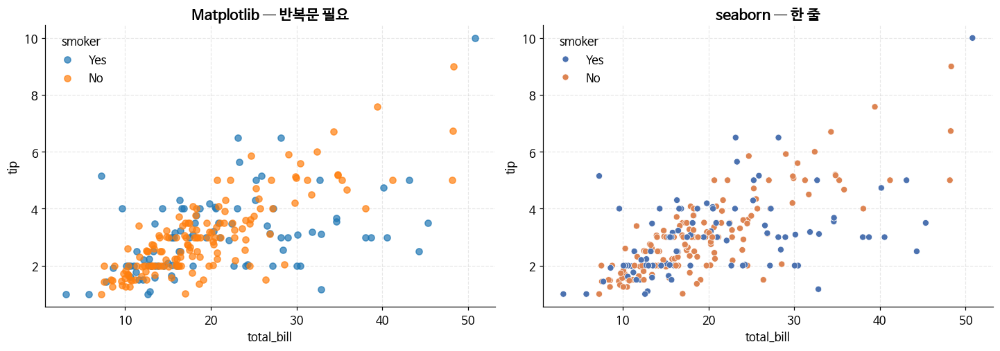

In [101]:
# 같은 그래프를 두 방식으로 그려 보기 — 코드 길이를 비교하세요
tips = sns.load_dataset('tips')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

# --- Matplotlib 으로 그룹별 산점도 ---
for (name, g), c in zip(tips.groupby('smoker'), ['tab:blue', 'tab:orange']):
    axes[0].scatter(g['total_bill'], g['tip'], label=name, alpha=0.7, color=c)
axes[0].set_xlabel('total_bill'); axes[0].set_ylabel('tip')
axes[0].legend(title='smoker')
axes[0].set_title('Matplotlib — 반복문 필요')

# --- seaborn 으로 같은 그래프 ---
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='smoker', ax=axes[1])
axes[1].set_title('seaborn — 한 줄')

plt.show()

---

# Part 1. 준비

## 1.1 설치

```bash
pip install seaborn
```

seaborn 0.13 이상을 권장합니다. (`sns.__version__` 으로 확인)

## 1.2 한글 폰트 — seaborn에서 주의할 점

**`sns.set_theme()` 을 호출하면 폰트 설정이 초기화되어 한글이 다시 깨집니다.**

> 순서: `sns.set_theme()` → **그 다음에** 폰트 설정. 반대로 하면 깨집니다.

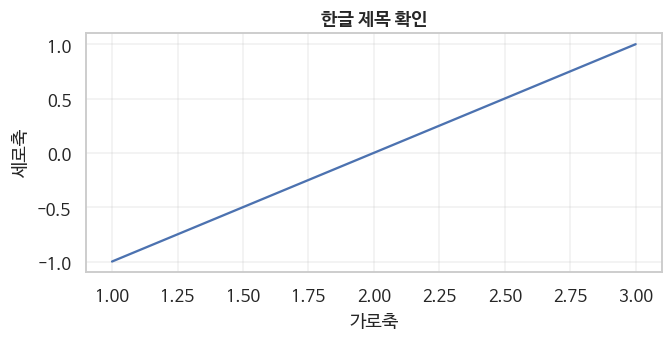

In [102]:
sns.set_theme(style='whitegrid', context='notebook')   # 먼저 테마
set_korean_font()                                       # 그 다음 폰트

fig, ax = plt.subplots(figsize=(6, 3))
sns.lineplot(x=[1, 2, 3], y=[-1, 0, 1], ax=ax)
ax.set(title='한글 제목 확인', xlabel='가로축', ylabel='세로축')
plt.show()

## 1.3 내장 예제 데이터

seaborn은 연습용 데이터셋을 제공합니다. (인터넷 연결 필요)

| 데이터셋 | 내용 | 주요 열 |
|---|---|---|
| `tips` | 식당 팁 | total_bill, tip, sex, smoker, day, time, size |
| `penguins` | 펭귄 신체 측정 | species, island, bill_length_mm, flipper_length_mm, body_mass_g, sex |
| `titanic` | 타이타닉 생존 | survived, pclass, sex, age, fare, class |
| `flights` | 월별 항공 승객 | year, month, passengers |
| `fmri` | 뇌 신호 시계열 | subject, timepoint, event, region, signal |
| `diamonds` | 다이아몬드 가격 | carat, cut, color, clarity, price |

> 인터넷이 안 되면 아래 셀이 실패합니다.

In [103]:
tips = sns.load_dataset('tips')
penguins = sns.load_dataset('penguins')
flights = sns.load_dataset('flights')
titanic = sns.load_dataset('titanic')
fmri = sns.load_dataset('fmri')

print('tips     ', tips.shape)
print('penguins ', penguins.shape)
print('flights  ', flights.shape)
print('titanic  ', titanic.shape)
print('fmri     ', fmri.shape)
tips.head()

tips      (244, 7)
penguins  (344, 7)
flights   (144, 3)
titanic   (891, 15)
fmri      (1064, 5)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 1.4 tidy data — seaborn을 쓰기 위한 데이터 모양

seaborn은 **long-form(tidy)** 데이터를 전제로 설계되었습니다.

- **한 행 = 한 관측치**
- **한 열 = 한 변수**

```
[ wide-form (엑셀식) ]          [ long-form (tidy) ]
연도   서울  부산               연도   지역   값
2023   100   80        →       2023   서울   100
2024   120   90                2023   부산    80
                               2024   서울   120
                               2024   부산    90
```

wide → long 변환은 `pd.melt()` 로 합니다. **seaborn이 잘 안 될 때 열에 아홉은 데이터 모양 문제입니다.**

--- wide-form ---
     연도   서울  부산  대구
0  2022  100  80  60
1  2023  110  85  58
2  2024  125  92  63

--- long-form (tidy) ---
     연도  지역    값
0  2022  서울  100
1  2023  서울  110
2  2024  서울  125
3  2022  부산   80
4  2023  부산   85
5  2024  부산   92


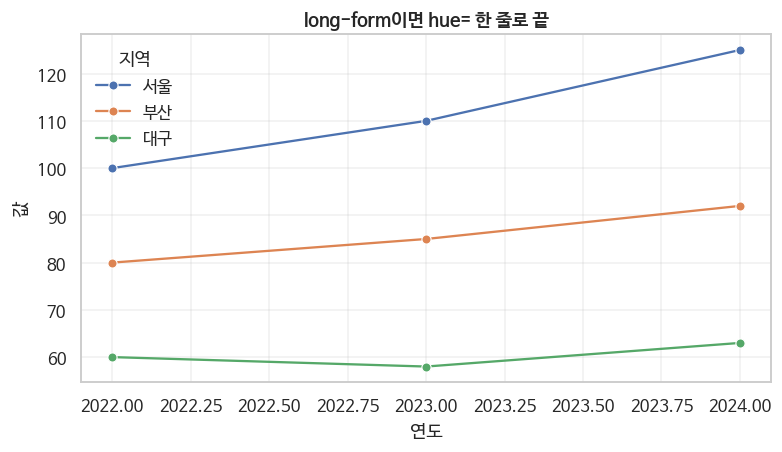

In [104]:
wide = pd.DataFrame({'연도': [2022, 2023, 2024],
                     '서울': [100, 110, 125],
                     '부산': [80, 85, 92],
                     '대구': [60, 58, 63]})
print('--- wide-form ---')
print(wide)

long = wide.melt(id_vars='연도', var_name='지역', value_name='값')
print('\n--- long-form (tidy) ---')
print(long.head(6))

fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=long, x='연도', y='값', hue='지역', marker='o', ax=ax)
ax.set_title('long-form이면 hue= 한 줄로 끝')
plt.show()

---

# Part 2. 핵심 개념 — figure-level vs axes-level

**seaborn을 쓰다가 막히는 이유의 90%가 이 구분을 몰라서입니다.** 여기만 이해하면 나머지는 쉽습니다.

## 2.1 두 종류의 함수

| | **axes-level** | **figure-level** |
|---|---|---|
| 예 | `scatterplot`, `histplot`, `boxplot`, `heatmap` | `relplot`, `displot`, `catplot`, `lmplot`, `pairplot`, `jointplot` |
| 그리는 대상 | **하나의 Axes** | **Figure 전체** |
| `ax=` 인자 | **받음** | **못 받음** |
| 반환값 | `matplotlib.axes.Axes` | `FacetGrid` / `JointGrid` 등 seaborn 객체 |
| 서브플롯 | 내가 `plt.subplots()` 로 배치 | `col=`, `row=` 로 자동 분할 |
| 크기 지정 | `plt.subplots(figsize=...)` | `height=`, `aspect=` |

## 2.2 대응 관계

| 종류 | figure-level | 안에서 쓰는 axes-level |
|---|---|---|
| 관계 | `relplot(kind=...)` | `scatterplot`, `lineplot` |
| 분포 | `displot(kind=...)` | `histplot`, `kdeplot`, `ecdfplot` |
| 범주 | `catplot(kind=...)` | `stripplot`, `swarmplot`, `boxplot`, `violinplot`, `barplot`, `pointplot`, `countplot` |
| 회귀 | `lmplot` | `regplot` |

> **고르는 법**
> - 그래프 **하나**만, 또는 내가 만든 레이아웃에 끼워 넣기 → **axes-level**
> - `col=`/`row=` 로 **여러 개로 쪼개** 보고 싶다 → **figure-level**

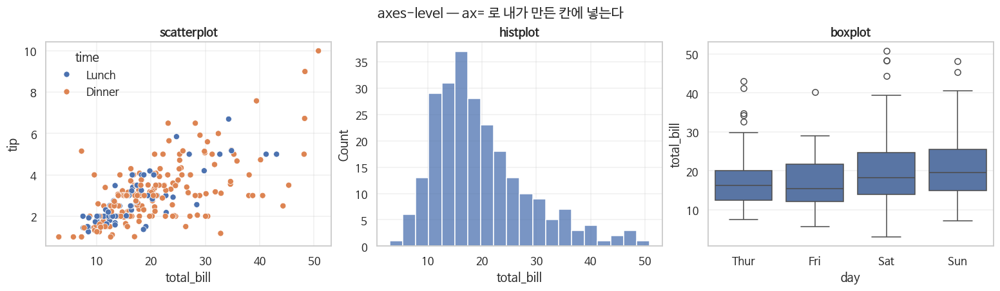

In [105]:
# axes-level: 내 레이아웃에 자유롭게 배치 가능
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', ax=axes[0])
sns.histplot(data=tips, x='total_bill', bins=20, ax=axes[1])
sns.boxplot(data=tips, x='day', y='total_bill', ax=axes[2])

for ax, t in zip(axes, ['scatterplot', 'histplot', 'boxplot']):
    ax.set_title(t)
fig.suptitle('axes-level — ax= 로 내가 만든 칸에 넣는다', fontsize=14)
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


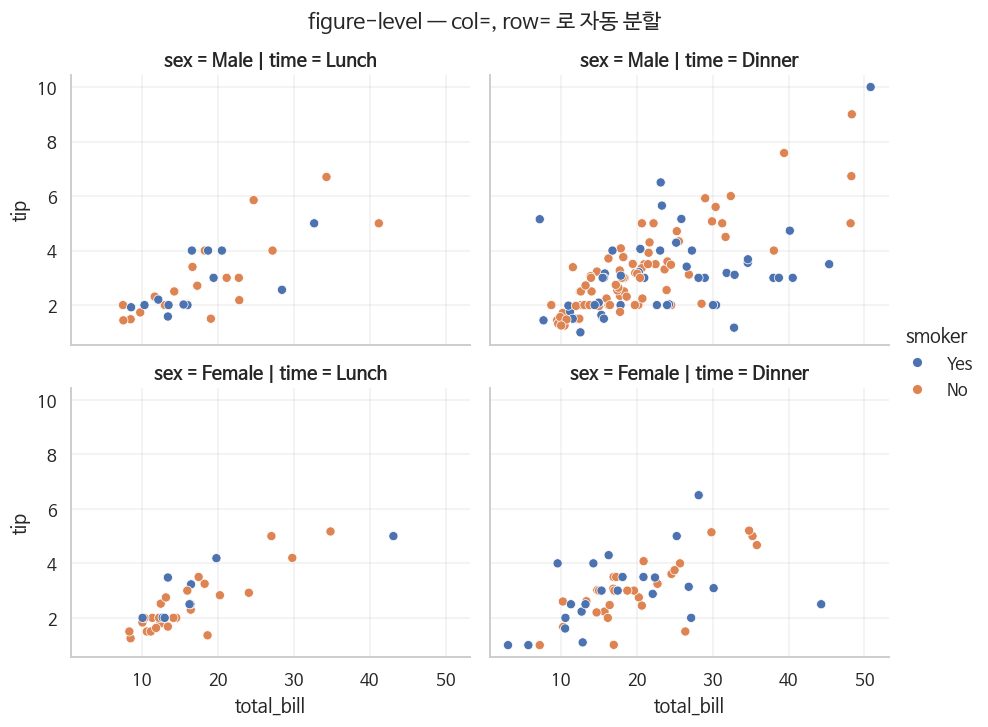

반환 타입: <class 'seaborn.axisgrid.FacetGrid'>
내부 Axes 개수: (2, 2)


In [106]:
# figure-level: col= 만 주면 알아서 쪼개 준다
g = sns.relplot(data=tips, x='total_bill', y='tip',
                hue='smoker', col='time', row='sex',
                height=3.2, aspect=1.3, kind='scatter')
g.figure.suptitle('figure-level — col=, row= 로 자동 분할', y=1.03, fontsize=14)
plt.show()

print('반환 타입:', type(g))
print('내부 Axes 개수:', g.axes.shape)

## 2.3 figure-level 결과를 손보는 법

figure-level 함수는 `ax=` 를 못 받지만, 반환된 `FacetGrid` 를 통해 얼마든지 수정할 수 있습니다.

| 하고 싶은 것 | 코드 |
|---|---|
| Figure 접근 | `g.figure` |
| 개별 Axes 접근 | `g.axes` (2차원 배열), `g.axes.flat` |
| 축 라벨 일괄 | `g.set_axis_labels('x라벨', 'y라벨')` |
| 각 패널 제목 | `g.set_titles('{col_name} 조건')` |
| 축 옵션 일괄 | `g.set(xlim=(0, 60), yscale='log')` |
| 전체 제목 | `g.figure.suptitle('제목')` |
| 여백 | `g.figure.tight_layout()` |
| 저장 | `g.savefig('out.png', dpi=200)` |

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


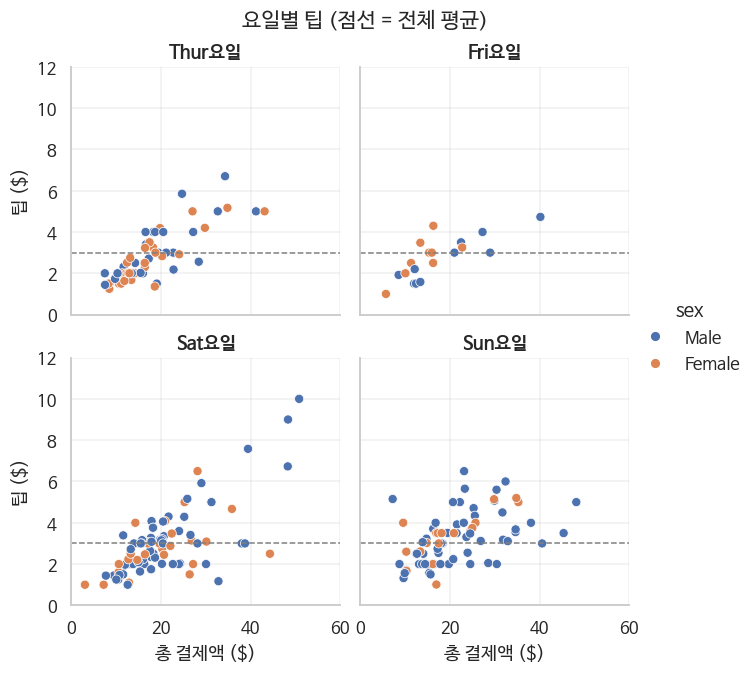

In [107]:
g = sns.relplot(data=tips, x='total_bill', y='tip', col='day',
                col_wrap=2, height=3, hue='sex')

g.set_axis_labels('총 결제액 ($)', '팁 ($)')
g.set_titles('{col_name}요일')
g.set(xlim=(0, 60), ylim=(0, 12))

# 개별 패널에 Matplotlib으로 추가 작업
for ax in g.axes.flat:
    ax.axhline(tips['tip'].mean(), color='gray', ls='--', lw=1)

g.figure.suptitle('요일별 팁 (점선 = 전체 평균)', y=1.02, fontsize=14)
plt.show()

---

# Part 3. 관계형 플롯 (relational)

**두 연속 변수의 관계**를 봅니다.

## 3.1 공통 인자 — 이것만 알면 절반은 끝

| 인자 | 뜻 |
|---|---|
| `data` | DataFrame |
| `x`, `y` | 열 이름 (문자열) |
| `hue` | **색**으로 그룹 구분 |
| `size` | **크기**로 그룹 구분 |
| `style` | **마커/선 모양**으로 그룹 구분 |
| `col`, `row` | 패널을 나눔 (figure-level 전용) |
| `palette` | 색 팔레트 |
| `alpha` | 투명도 |

> `hue`, `size`, `style` 을 조합하면 한 그래프에 **4~5개 변수**를 담을 수 있습니다. 다만 3개를 넘기면 읽기 어려워집니다.

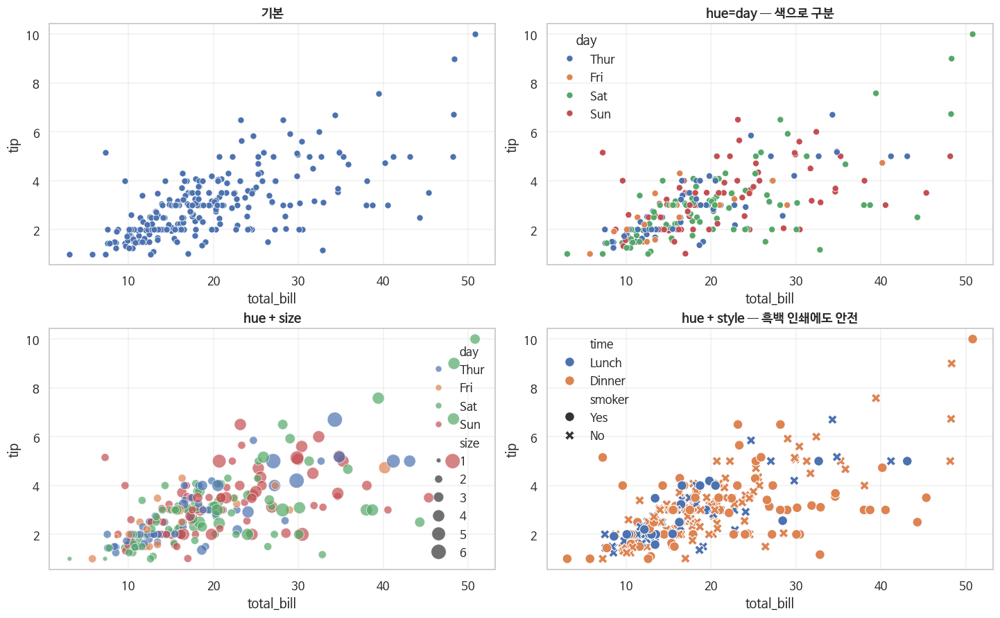

In [108]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

sns.scatterplot(data=tips, x='total_bill', y='tip', ax=axes[0, 0])
axes[0, 0].set_title('기본')

sns.scatterplot(data=tips, x='total_bill', y='tip', hue='day', ax=axes[0, 1])
axes[0, 1].set_title('hue=day — 색으로 구분')

sns.scatterplot(data=tips, x='total_bill', y='tip', hue='day', size='size',
                sizes=(20, 200), alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title('hue + size')

sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', style='smoker',
                s=80, ax=axes[1, 1])
axes[1, 1].set_title('hue + style — 흑백 인쇄에도 안전')
plt.show()

## 3.2 `lineplot` — 자동 집계와 신뢰구간

**seaborn의 진가가 드러나는 함수입니다.** 같은 x에 y가 여러 개면 **평균을 내고 95% 신뢰구간을 띠로** 그려 줍니다. Matplotlib으로 하려면 groupby + fill_between을 직접 짜야 합니다.

같은 timepoint에 관측치가 여러 개:
    subject  timepoint    signal
169     s12          5  0.248138
184     s13          5  0.252627
185      s6          5  0.239175


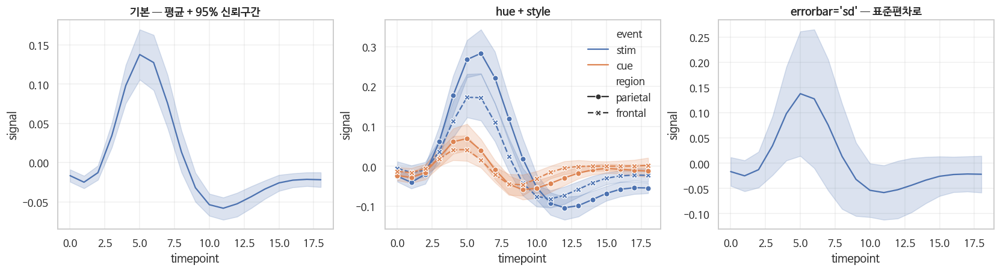

In [109]:
print('같은 timepoint에 관측치가 여러 개:')
print(fmri[fmri.timepoint == 5].head(3)[['subject', 'timepoint', 'signal']])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

sns.lineplot(data=fmri, x='timepoint', y='signal', ax=axes[0])
axes[0].set_title('기본 — 평균 + 95% 신뢰구간')

sns.lineplot(data=fmri, x='timepoint', y='signal', hue='event',
             style='region', markers=True, ax=axes[1])
axes[1].set_title('hue + style')

sns.lineplot(data=fmri, x='timepoint', y='signal', errorbar='sd', ax=axes[2])
axes[2].set_title("errorbar='sd' — 표준편차로")
plt.show()

### `errorbar` 옵션 (0.12+)

| 값 | 뜻 |
|---|---|
| `('ci', 95)` 또는 `'ci'` | 부트스트랩 신뢰구간 (기본) |
| `'sd'` | 표준편차 |
| `('se', 2)` | 표준오차 × 2 |
| `('pi', 50)` | 백분위 구간 |
| `None` | 띠 없음 (데이터가 크면 속도 향상) |

> 구버전에서는 `ci=95`, `ci='sd'`, `ci=None` 을 씁니다.

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


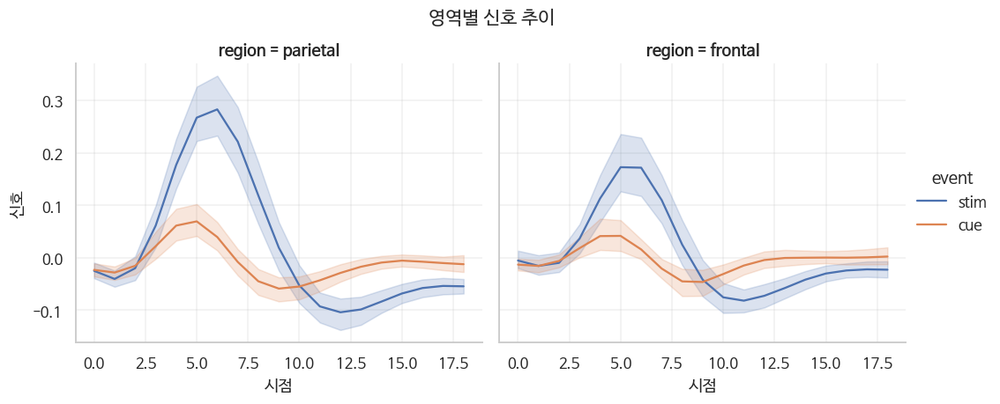

In [110]:
# relplot 으로 패널 나누기
g = sns.relplot(data=fmri, x='timepoint', y='signal',
                hue='event', col='region', kind='line',
                height=4, aspect=1.2)
g.set_axis_labels('시점', '신호')
g.figure.suptitle('영역별 신호 추이', y=1.04, fontsize=14)
plt.show()

---

# Part 4. 분포 플롯 (distribution)

**한 변수(또는 두 변수)가 어떻게 퍼져 있는지** 봅니다.

| 함수 | 무엇 |
|---|---|
| `histplot` | 히스토그램 (구간별 개수) |
| `kdeplot` | 커널 밀도 추정 — 부드러운 곡선 |
| `ecdfplot` | 누적분포 — **bins에 좌우되지 않음** |
| `rugplot` | 축 위에 실제 관측치 위치 표시 |
| `displot` | 위 넷의 figure-level 버전 (`kind=`) |

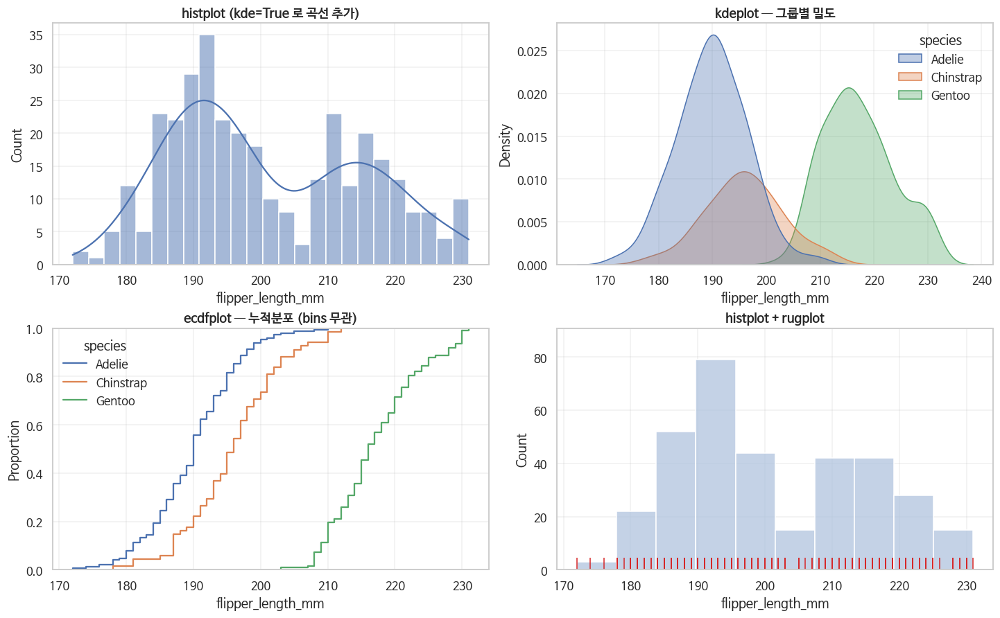

In [111]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

sns.histplot(data=penguins, x='flipper_length_mm', bins=25, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('histplot (kde=True 로 곡선 추가)')

sns.kdeplot(data=penguins, x='flipper_length_mm', hue='species', fill=True,
            alpha=0.35, ax=axes[0, 1])
axes[0, 1].set_title('kdeplot — 그룹별 밀도')

sns.ecdfplot(data=penguins, x='flipper_length_mm', hue='species', ax=axes[1, 0])
axes[1, 0].set_title('ecdfplot — 누적분포 (bins 무관)')

sns.histplot(data=penguins, x='flipper_length_mm', ax=axes[1, 1], color='lightsteelblue')
sns.rugplot(data=penguins, x='flipper_length_mm', ax=axes[1, 1], color='tab:red', height=0.05)
axes[1, 1].set_title('histplot + rugplot')
plt.show()

### 그룹이 여러 개일 때 — `multiple=`

| 값 | 모양 |
|---|---|
| `'layer'` | 겹쳐 그림 (기본) |
| `'dodge'` | 나란히 |
| `'stack'` | 쌓기 |
| `'fill'` | 100% 채우기 (비율 비교) |

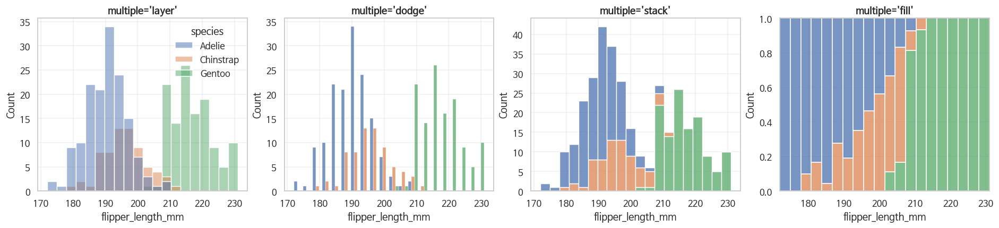

In [112]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), constrained_layout=True)
for ax, m in zip(axes, ['layer', 'dodge', 'stack', 'fill']):
    sns.histplot(data=penguins, x='flipper_length_mm', hue='species',
                 multiple=m, bins=20, ax=ax, legend=(m == 'layer'))
    ax.set_title(f"multiple='{m}'")
plt.show()

### `stat=` — y축이 무엇을 나타내는가

| 값 | y축 |
|---|---|
| `'count'` | 개수 (기본) |
| `'density'` | 밀도 (넓이 합 = 1) |
| `'probability'` | 비율 (합 = 1) |
| `'percent'` | 퍼센트 (합 = 100) |

> **그룹 크기가 다를 때 개수로 비교하면 안 됩니다.** `stat='density'` 나 `'percent'` 에 `common_norm=False` 를 함께 쓰세요.

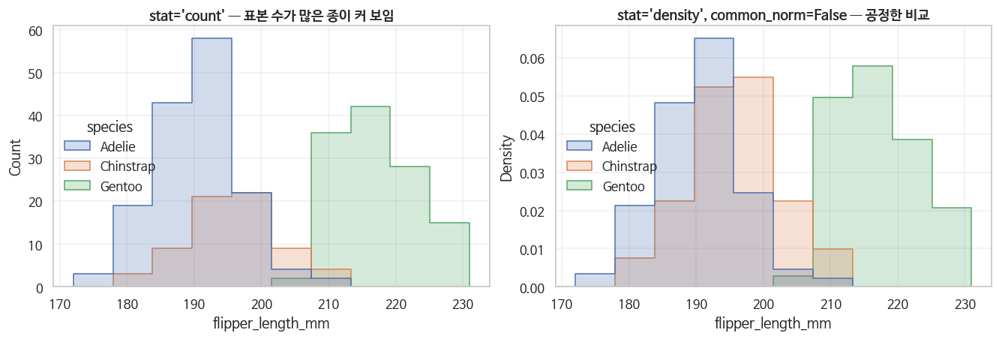

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

sns.histplot(data=penguins, x='flipper_length_mm', hue='species',
             stat='count', element='step', ax=axes[0])
axes[0].set_title("stat='count' — 표본 수가 많은 종이 커 보임")

sns.histplot(data=penguins, x='flipper_length_mm', hue='species',
             stat='density', common_norm=False, element='step', ax=axes[1])
axes[1].set_title("stat='density', common_norm=False — 공정한 비교")
plt.show()

### 2차원 분포

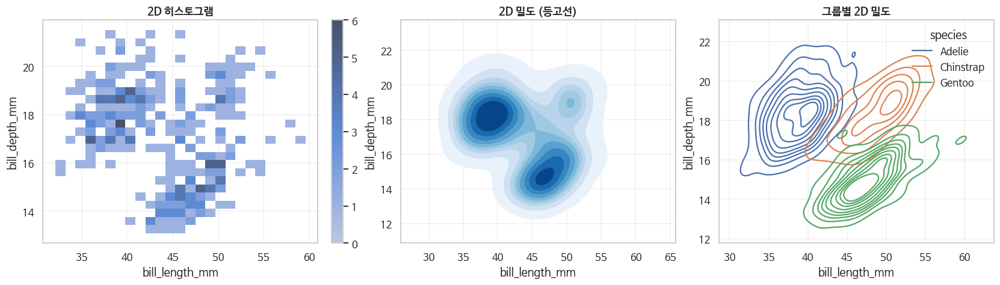

In [114]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

sns.histplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
             bins=25, cbar=True, ax=axes[0])
axes[0].set_title('2D 히스토그램')

sns.kdeplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
            fill=True, cmap='Blues', ax=axes[1])
axes[1].set_title('2D 밀도 (등고선)')

sns.kdeplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
            hue='species', ax=axes[2])
axes[2].set_title('그룹별 2D 밀도')
plt.show()

---

# Part 5. 범주형 플롯 (categorical)

**범주 × 수치** 관계를 봅니다. seaborn에서 가장 함수가 많은 영역입니다.

| 그룹 | 함수 | 보여주는 것 |
|---|---|---|
| **관측치 그대로** | `stripplot` | 점 (랜덤 흩뿌림) |
| | `swarmplot` | 점 (안 겹치게 정렬) |
| **분포 요약** | `boxplot` | 사분위수 · 이상치 |
| | `violinplot` | 밀도 곡선 |
| | `boxenplot` | 큰 데이터용 확장 박스 |
| **통계 추정** | `barplot` | **평균 + 신뢰구간** |
| | `pointplot` | 평균을 점·선으로 (변화 강조) |
| | `countplot` | 빈도 (y 불필요) |

> figure-level 통합 함수: `catplot(kind='box')` 처럼 씁니다.

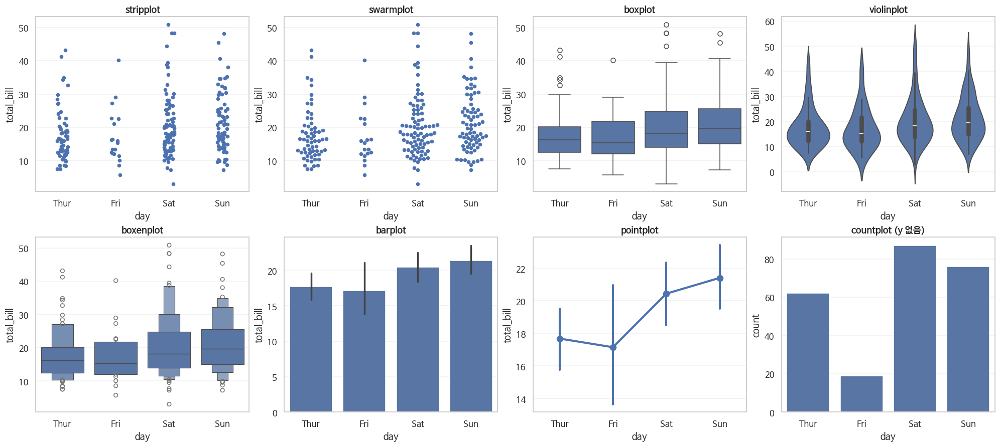

In [115]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
kinds = [('stripplot', sns.stripplot), ('swarmplot', sns.swarmplot),
         ('boxplot', sns.boxplot), ('violinplot', sns.violinplot),
         ('boxenplot', sns.boxenplot), ('barplot', sns.barplot),
         ('pointplot', sns.pointplot)]

for ax, (name, fn) in zip(axes.flat, kinds):
    fn(data=tips, x='day', y='total_bill', ax=ax)
    ax.set_title(name)

sns.countplot(data=tips, x='day', ax=axes.flat[7])
axes.flat[7].set_title('countplot (y 없음)')
plt.show()

## 5.1 `barplot` 의 막대는 무엇인가?

> **중요:** seaborn `barplot` 의 막대 높이는 **합계가 아니라 평균**이고, 검은 선은 **95% 신뢰구간**입니다. 엑셀의 막대그래프와 다릅니다.

합계를 원하면 `estimator='sum'` 을 주거나, `groupby` 로 미리 집계해서 그리세요.

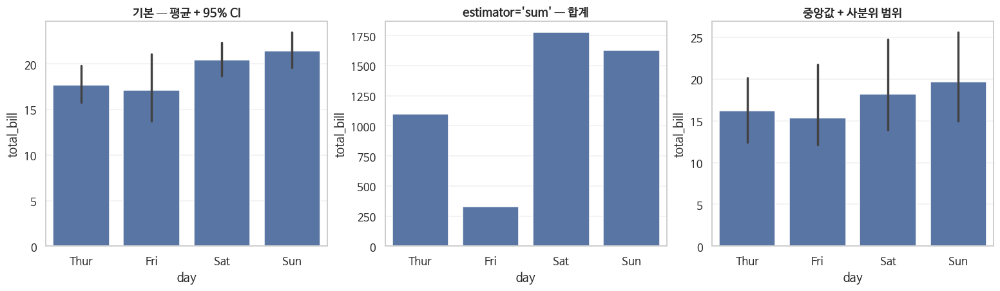

직접 확인:
       mean      sum
day                 
Thur  17.68  1096.33
Fri   17.15   325.88
Sat   20.44  1778.40
Sun   21.41  1627.16


In [116]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

sns.barplot(data=tips, x='day', y='total_bill', ax=axes[0])
axes[0].set_title('기본 — 평균 + 95% CI')

sns.barplot(data=tips, x='day', y='total_bill', estimator='sum',
            errorbar=None, ax=axes[1])
axes[1].set_title("estimator='sum' — 합계")

sns.barplot(data=tips, x='day', y='total_bill', estimator='median',
            errorbar=('pi', 50), ax=axes[2])
axes[2].set_title('중앙값 + 사분위 범위')
plt.show()

print('직접 확인:')
print(tips.groupby('day', observed=True)['total_bill'].agg(['mean', 'sum']).round(2))

## 5.2 `hue` 로 두 범주 교차 보기

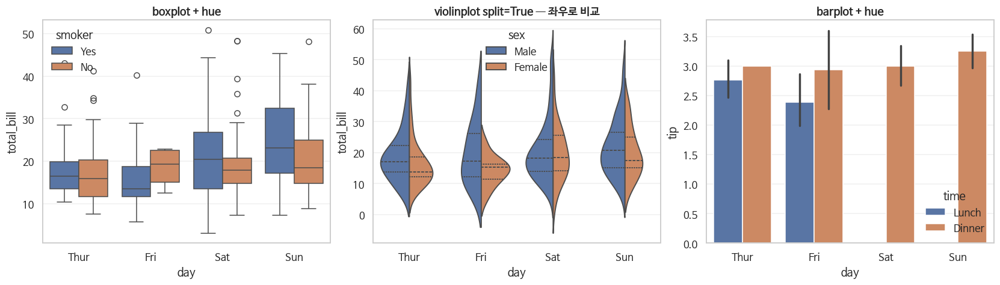

In [117]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

sns.boxplot(data=tips, x='day', y='total_bill', hue='smoker', ax=axes[0])
axes[0].set_title('boxplot + hue')

sns.violinplot(data=tips, x='day', y='total_bill', hue='sex',
               split=True, inner='quart', ax=axes[1])
axes[1].set_title('violinplot split=True — 좌우로 비교')

sns.barplot(data=tips, x='day', y='tip', hue='time', ax=axes[2])
axes[2].set_title('barplot + hue')
plt.show()

## 5.3 요약 + 관측치를 겹쳐 그리기 (실무에서 가장 좋은 조합)

박스플롯만 그리면 **표본이 3개인지 300개인지 알 수 없습니다.** 점을 겹쳐 그리면 그 문제가 해결됩니다.

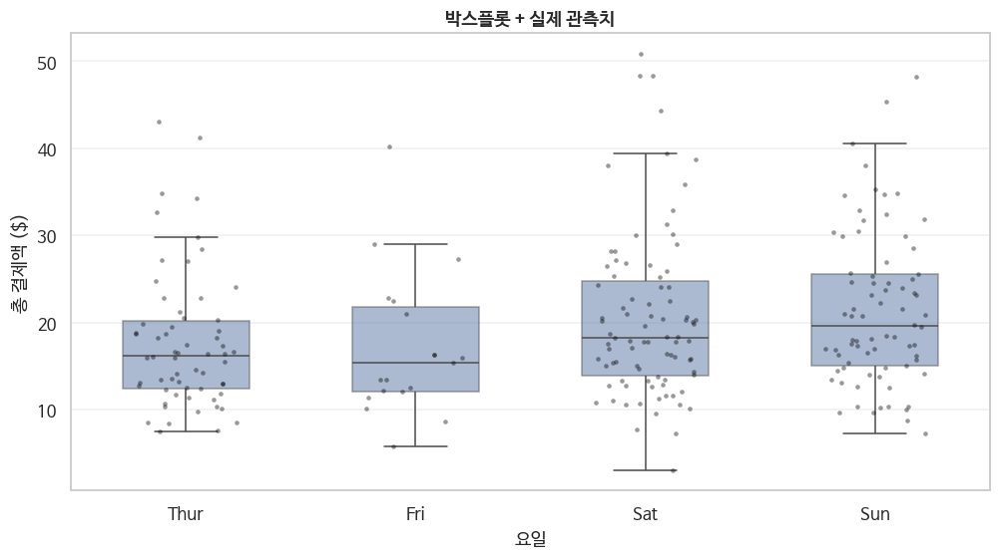

In [118]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(data=tips, x='day', y='total_bill', ax=ax,
            showfliers=False, boxprops=dict(alpha=0.5), width=0.55)
sns.stripplot(data=tips, x='day', y='total_bill', ax=ax,
              color='black', alpha=0.4, size=3, jitter=0.22)

ax.set(xlabel='요일', ylabel='총 결제액 ($)', title='박스플롯 + 실제 관측치')
plt.show()

## 5.4 순서 지정과 정렬

범주 순서는 기본적으로 데이터 등장 순서 또는 Categorical 순서를 따릅니다. `order=`, `hue_order=` 로 직접 지정하세요.

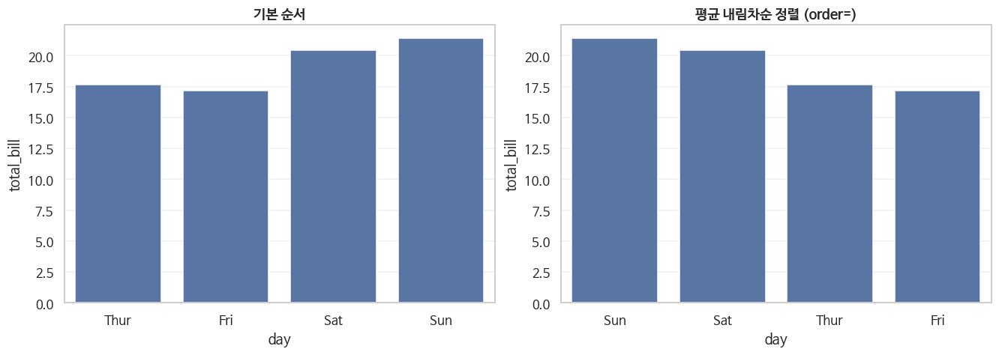

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

sns.barplot(data=tips, x='day', y='total_bill', errorbar=None, ax=axes[0])
axes[0].set_title('기본 순서')

order = (tips.groupby('day', observed=True)['total_bill']
         .mean().sort_values(ascending=False).index)
sns.barplot(data=tips, x='day', y='total_bill', order=order, errorbar=None, ax=axes[1])
axes[1].set_title('평균 내림차순 정렬 (order=)')
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


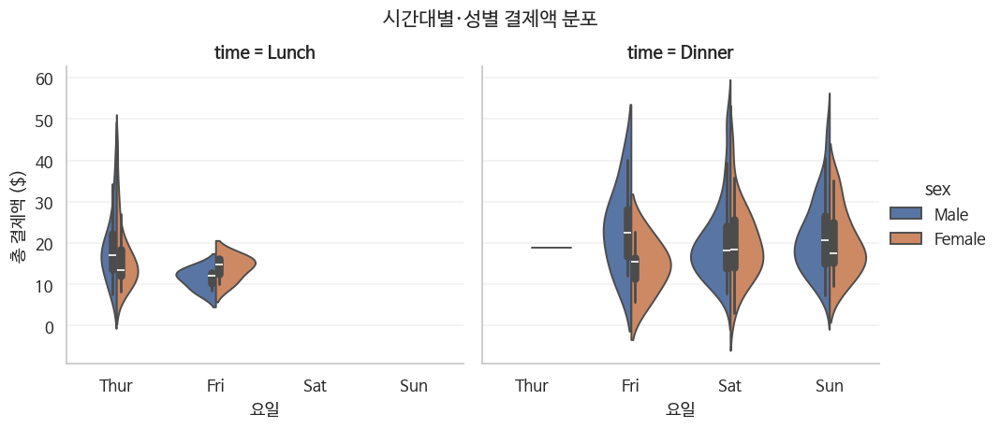

In [120]:
# catplot — figure-level 로 패널 나누기
g = sns.catplot(data=tips, x='day', y='total_bill', hue='sex',
                col='time', kind='violin', split=True,
                height=4, aspect=1.1)
g.set_axis_labels('요일', '총 결제액 ($)')
g.figure.suptitle('시간대별·성별 결제액 분포', y=1.04, fontsize=14)
plt.show()

---

# Part 6. 회귀 플롯

산점도에 **추세선과 신뢰구간**을 자동으로 얹어 줍니다.

| 함수 | 레벨 | 특징 |
|---|---|---|
| `regplot` | axes-level | `ax=` 가능, `hue` **없음** |
| `lmplot` | figure-level | `hue`, `col`, `row` 가능 |
| `residplot` | axes-level | 잔차 — 모형이 적절한지 진단 |

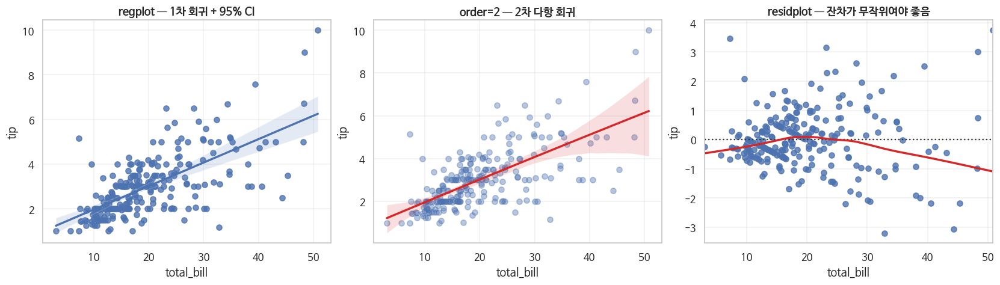

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

sns.regplot(data=tips, x='total_bill', y='tip', ax=axes[0])
axes[0].set_title('regplot — 1차 회귀 + 95% CI')

sns.regplot(data=tips, x='total_bill', y='tip', order=2,
            scatter_kws=dict(alpha=0.4), line_kws=dict(color='tab:red'), ax=axes[1])
axes[1].set_title('order=2 — 2차 다항 회귀')

sns.residplot(data=tips, x='total_bill', y='tip', lowess=True,
              line_kws=dict(color='tab:red'), ax=axes[2])
axes[2].set_title('residplot — 잔차가 무작위여야 좋음')
plt.show()

### 주요 인자

| 인자 | 뜻 |
|---|---|
| `order` | 다항 회귀 차수 |
| `logistic=True` | 로지스틱 회귀 (y가 0/1일 때) |
| `lowess=True` | 비모수 국소 회귀 |
| `robust=True` | 이상치에 둔감한 회귀 |
| `ci` | 신뢰구간 (`None` 이면 숨김) |
| `scatter_kws`, `line_kws` | 점·선 스타일 딕셔너리 |
| `x_estimator=np.mean` | x가 이산일 때 평균점으로 |

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


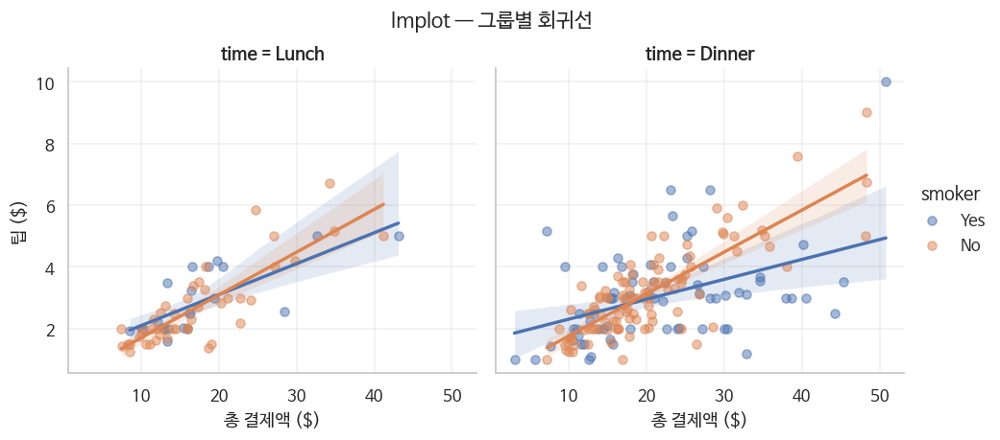

In [122]:
g = sns.lmplot(data=tips, x='total_bill', y='tip',
               hue='smoker', col='time', height=4, aspect=1.1,
               scatter_kws=dict(alpha=0.5))
g.set_axis_labels('총 결제액 ($)', '팁 ($)')
g.figure.suptitle('lmplot — 그룹별 회귀선', y=1.04, fontsize=14)
plt.show()

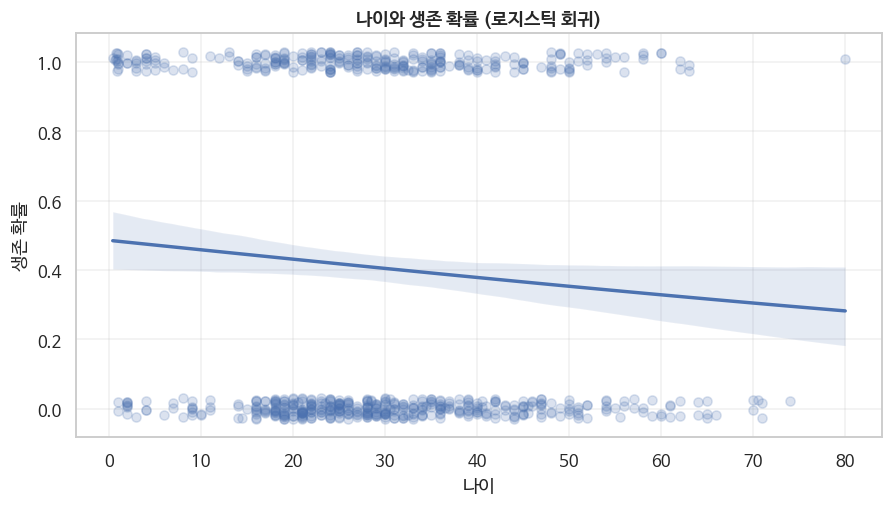

In [123]:
# 로지스틱 회귀 — y가 0/1 일 때
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=titanic.dropna(subset=['age']), x='age', y='survived',
            logistic=True, y_jitter=0.03,
            scatter_kws=dict(alpha=0.2), ax=ax)
ax.set(xlabel='나이', ylabel='생존 확률', title='나이와 생존 확률 (로지스틱 회귀)')
plt.show()

---

# Part 7. 행렬 · 다변량 플롯

| 함수 | 무엇 |
|---|---|
| `heatmap` | 2차원 행렬을 색으로 |
| `clustermap` | 히트맵 + 계층적 군집 정렬 |
| `pairplot` | 모든 변수쌍 산점도 행렬 |
| `jointplot` | 산점도 + 주변 분포 |

## 7.1 `heatmap` — 상관행렬의 표준 도구

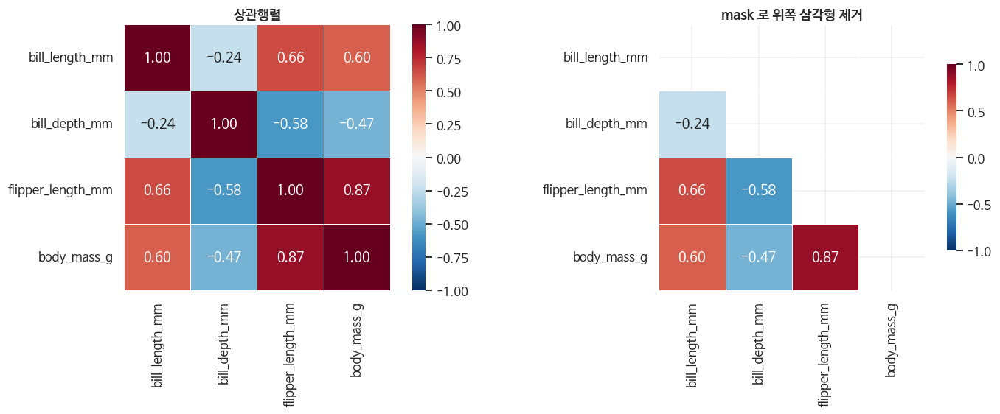

In [124]:
num = penguins.select_dtypes('number')
corr = num.corr()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[0])
axes[0].set_title('상관행렬')

# 위쪽 삼각형 가리기 (중복 제거)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws=dict(shrink=0.7), ax=axes[1])
axes[1].set_title('mask 로 위쪽 삼각형 제거')
plt.show()

### `heatmap` 주요 인자

| 인자 | 뜻 |
|---|---|
| `annot` | 칸에 값 표시 (`True` 또는 별도 배열) |
| `fmt` | 값 서식 (`'.2f'`, `'d'`, `',.0f'`) |
| `cmap` | 컬러맵 |
| `vmin`, `vmax`, `center` | 색 범위 기준 |
| `mask` | True인 칸을 숨김 |
| `square` | 칸을 정사각형으로 |
| `linewidths`, `linecolor` | 칸 사이 선 |
| `cbar`, `cbar_kws` | 컬러바 |

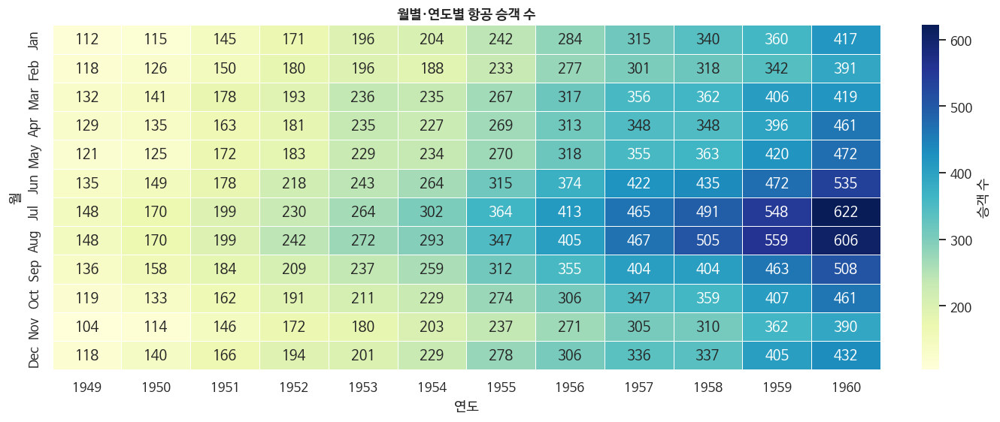

In [125]:
# 피벗 테이블 히트맵 — 실무에서 가장 흔한 형태
fp = flights.pivot(index='month', columns='year', values='passengers')

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(fp, annot=True, fmt='d', cmap='YlGnBu',
            linewidths=0.4, cbar_kws=dict(label='승객 수'), ax=ax)
ax.set(title='월별·연도별 항공 승객 수', xlabel='연도', ylabel='월')
plt.show()

## 7.2 `pairplot` — 탐색 첫 단계의 만능 도구

수치형 변수 전부의 관계를 한 번에 봅니다. **EDA를 시작할 때 가장 먼저 그리는 그래프**입니다.

> 변수가 많으면 `vars=['a','b','c']` 로 골라 쓰세요. 10개가 넘으면 100칸이 되어 아무것도 안 보입니다.

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


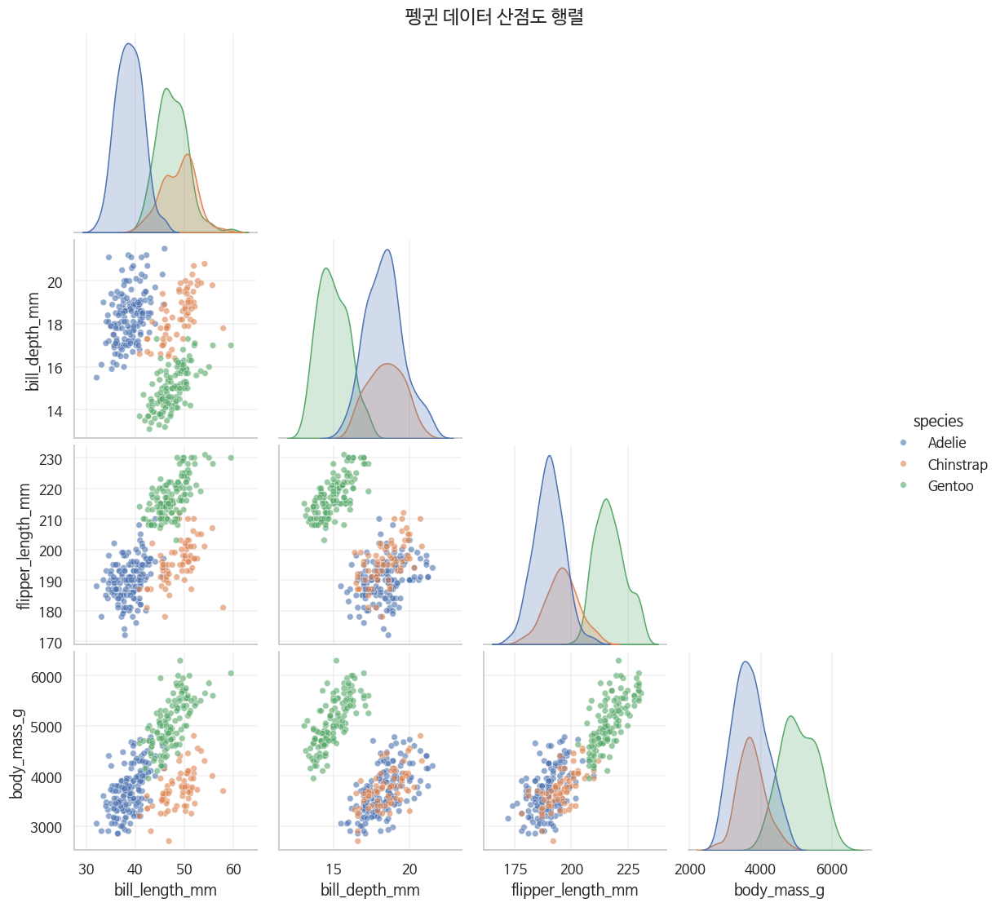

In [126]:
g = sns.pairplot(penguins, hue='species', diag_kind='kde',
                 corner=True,               # 아래 삼각형만 (중복 제거)
                 plot_kws=dict(alpha=0.6, s=25))
g.figure.suptitle('펭귄 데이터 산점도 행렬', y=1.01, fontsize=15)
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1766: UserWarning: The figure layout has changed to tight
  f.tight_layout()


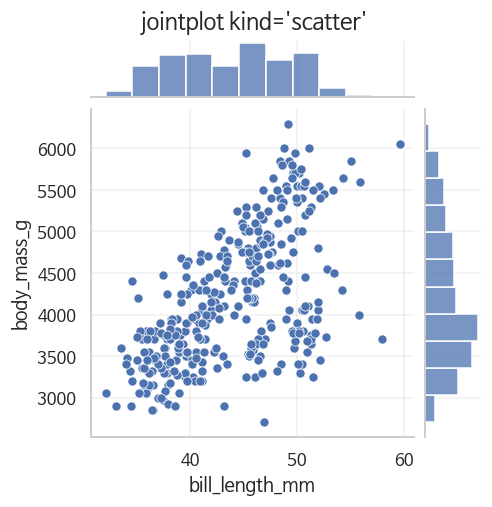

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1766: UserWarning: The figure layout has changed to tight
  f.tight_layout()


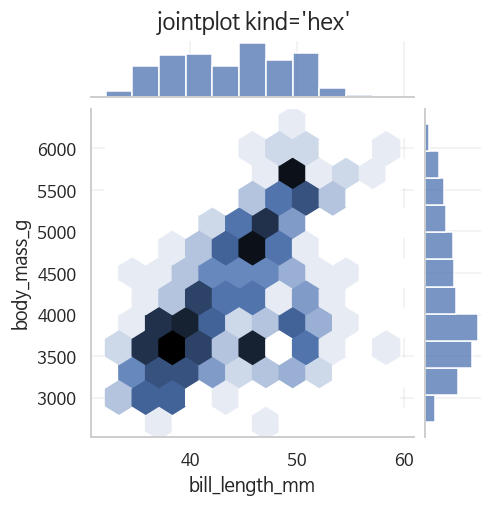

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1766: UserWarning: The figure layout has changed to tight
  f.tight_layout()


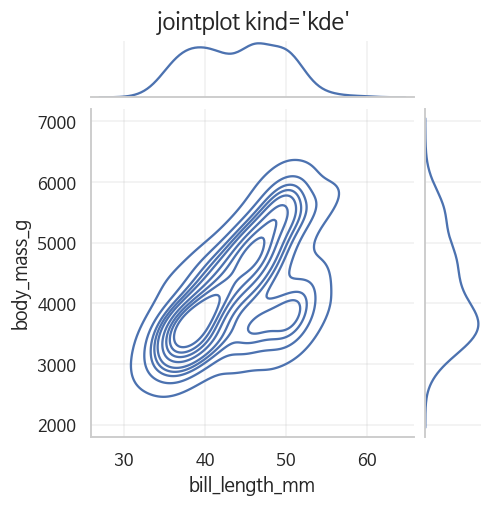

In [127]:
# jointplot — 산점도 + 주변 분포
for k in ['scatter', 'hex', 'kde']:
    g = sns.jointplot(data=penguins, x='bill_length_mm', y='body_mass_g',
                      kind=k, height=4.5)
    g.figure.suptitle(f"jointplot kind='{k}'", y=1.02)
    plt.show()

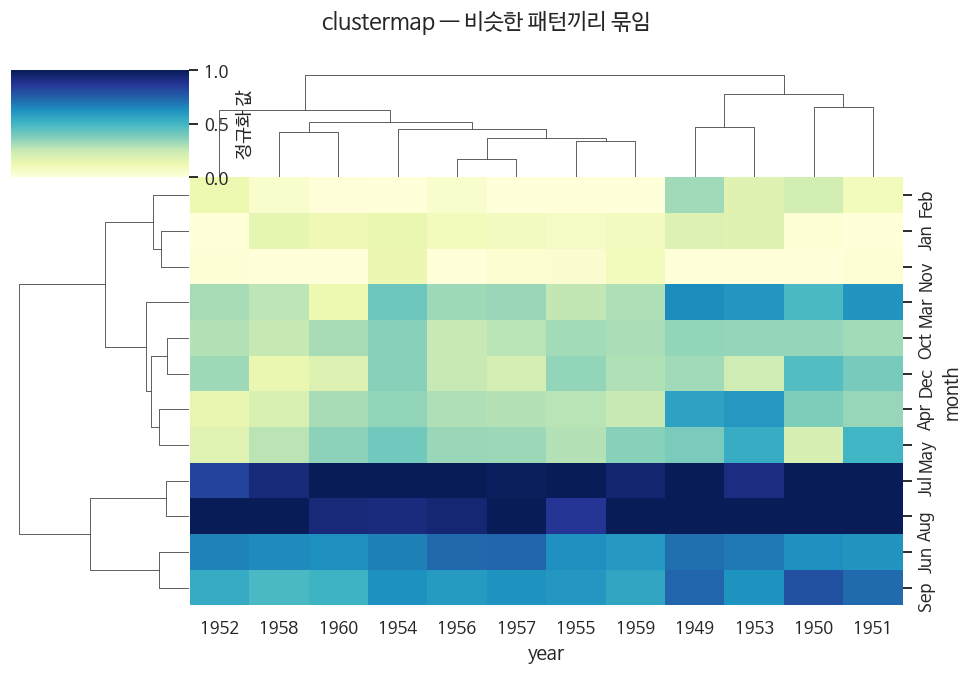

In [132]:
# clustermap — 비슷한 행/열끼리 묶어서 재정렬
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 기존 그림 닫기
plt.close('all')

# 자동 레이아웃 기능 끄기
plt.rcParams['figure.constrained_layout.use'] = False
plt.rcParams['figure.autolayout'] = False

# 데이터 정리
fp_clean = fp.copy()
fp_clean = fp_clean.apply(pd.to_numeric, errors='coerce')
fp_clean = fp_clean.replace([np.inf, -np.inf], np.nan)
fp_clean = fp_clean.fillna(0)

# 값이 모두 같은 열과 행 제거
fp_clean = fp_clean.loc[:, fp_clean.nunique() > 1]
fp_clean = fp_clean.loc[fp_clean.nunique(axis=1) > 1]

# clustermap
g = sns.clustermap(
    fp_clean,
    cmap='YlGnBu',
    figsize=(9, 6),
    standard_scale=1,
    cbar_kws={'label': '정규화 값'}
)

g.fig.suptitle(
    'clustermap — 비슷한 패턴끼리 묶임',
    y=1.02
)

# 제목 공간 확보
g.fig.subplots_adjust(top=0.93)

plt.show()

---

# Part 8. 스타일과 팔레트

## 8.1 `set_theme()` — 전역 설정

```python
sns.set_theme(style=..., context=..., palette=..., font_scale=...)
```

| 인자 | 값 |
|---|---|
| `style` | `'white'`, `'dark'`, `'whitegrid'`, `'darkgrid'`, `'ticks'` |
| `context` | `'paper'` < `'notebook'` < `'talk'` < `'poster'` (글자·선 크기) |
| `palette` | 색 팔레트 이름 |
| `font_scale` | 글자 크기 배율 |

> **`context` 를 기억하세요.** 발표 슬라이드용이면 `sns.set_theme(context='talk')` 한 줄로 모든 글자가 커집니다.

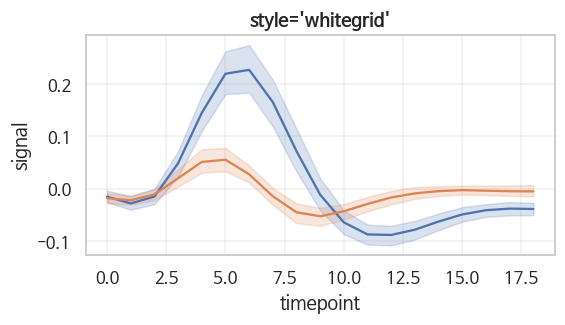

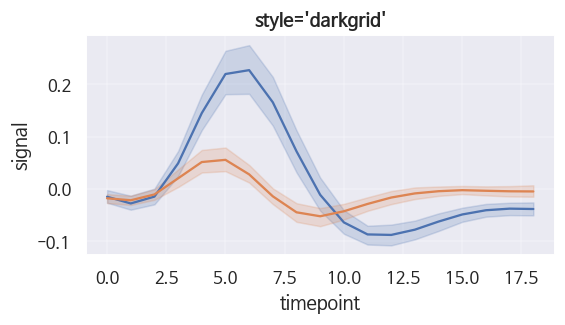

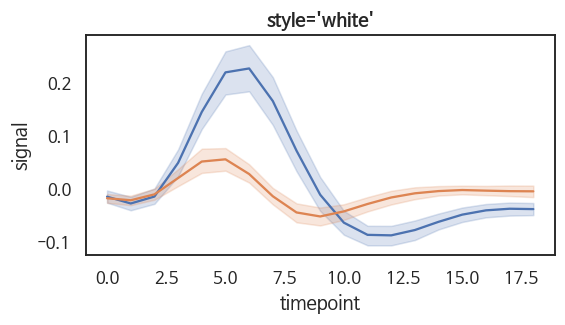

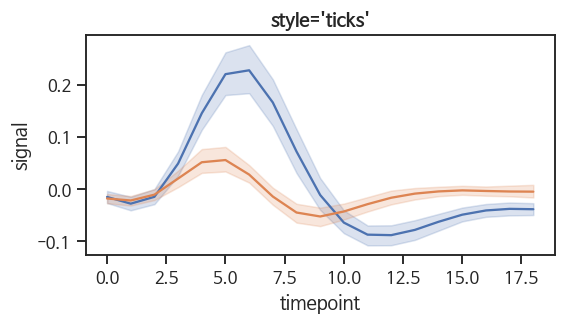

'NanumBarunGothic'

In [133]:
for st in ['whitegrid', 'darkgrid', 'white', 'ticks']:
    sns.set_theme(style=st)
    set_korean_font()
    fig, ax = plt.subplots(figsize=(5.5, 2.6))
    sns.lineplot(data=fmri, x='timepoint', y='signal', hue='event', ax=ax, legend=False)
    ax.set_title(f"style='{st}'")
    plt.show()

sns.set_theme(style='whitegrid'); set_korean_font()

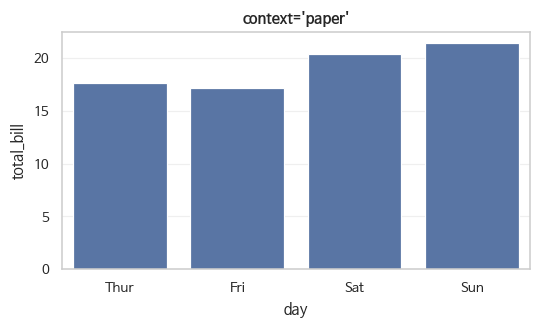

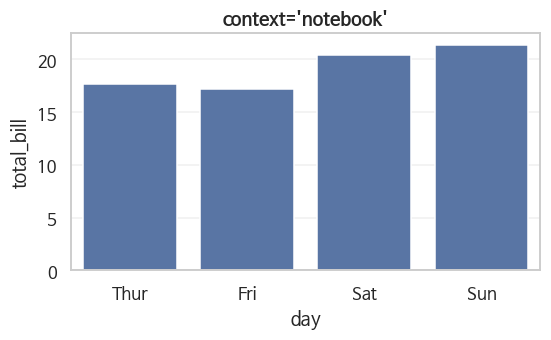

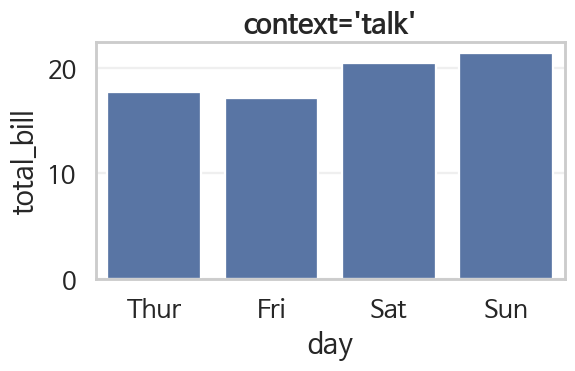

'NanumBarunGothic'

In [134]:
for ctx in ['paper', 'notebook', 'talk']:
    sns.set_theme(style='whitegrid', context=ctx)
    set_korean_font()
    fig, ax = plt.subplots(figsize=(5.5, 2.8))
    sns.barplot(data=tips, x='day', y='total_bill', errorbar=None, ax=ax)
    ax.set_title(f"context='{ctx}'")
    plt.show()

sns.set_theme(style='whitegrid', context='notebook'); set_korean_font()

## 8.2 팔레트 — 데이터 종류에 맞게 고르기

| 종류 | 언제 | 예 |
|---|---|---|
| **질적 (qualitative)** | 순서 없는 범주 | `deep`, `muted`, `pastel`, `Set2`, `tab10` |
| **순차 (sequential)** | 낮음 → 높음 | `viridis`, `rocket`, `mako`, `Blues` |
| **발산 (diverging)** | 0 기준 ±, 상관계수 | `vlag`, `icefire`, `coolwarm`, `RdBu_r` |

> **범주에 순차 팔레트를 쓰면 없는 순서를 암시하게 됩니다.** 흔한 실수입니다.

deep


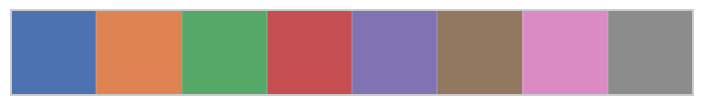

pastel


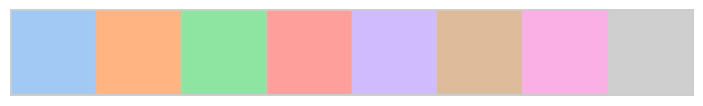

Set2


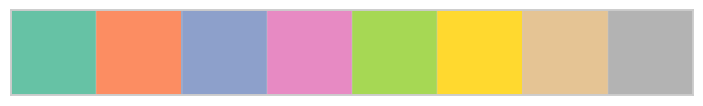

viridis


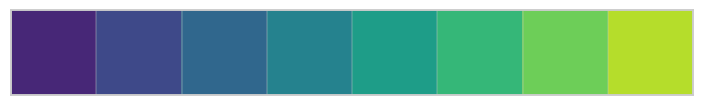

rocket


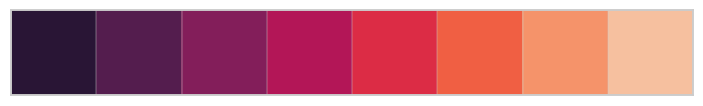

vlag


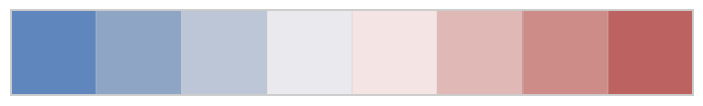

coolwarm


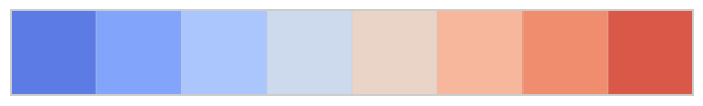

In [135]:
for name in ['deep', 'pastel', 'Set2', 'viridis', 'rocket', 'vlag', 'coolwarm']:
    print(name)
    sns.palplot(sns.color_palette(name, 8))
    plt.show()

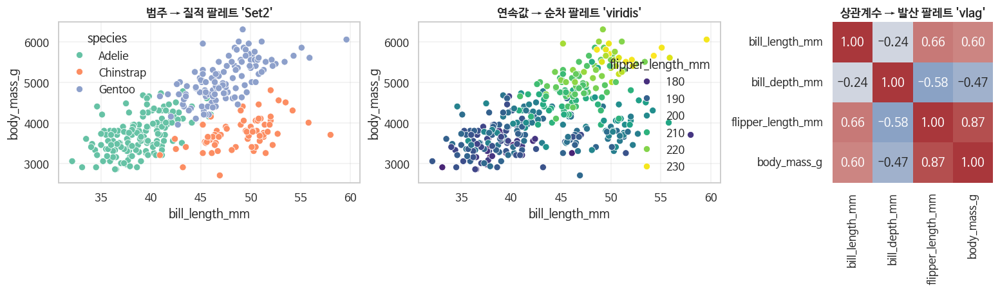

In [136]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

sns.scatterplot(data=penguins, x='bill_length_mm', y='body_mass_g',
                hue='species', palette='Set2', s=45, ax=axes[0])
axes[0].set_title("범주 → 질적 팔레트 'Set2'")

sns.scatterplot(data=penguins, x='bill_length_mm', y='body_mass_g',
                hue='flipper_length_mm', palette='viridis', s=45, ax=axes[1])
axes[1].set_title("연속값 → 순차 팔레트 'viridis'")

sns.heatmap(corr, cmap='vlag', center=0, annot=True, fmt='.2f',
            square=True, ax=axes[2], cbar=False)
axes[2].set_title("상관계수 → 발산 팔레트 'vlag'")
plt.show()

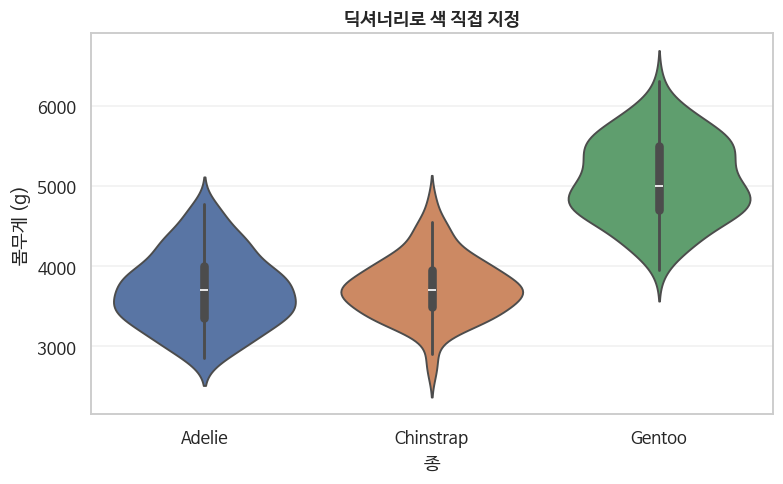

In [137]:
# 직접 색 지정 — 브랜드 컬러 등
my_palette = {'Adelie': '#4C72B0', 'Chinstrap': '#DD8452', 'Gentoo': '#55A868'}

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=penguins, x='species', y='body_mass_g',
               hue='species', palette=my_palette, legend=False, ax=ax)
ax.set(xlabel='종', ylabel='몸무게 (g)', title='딕셔너리로 색 직접 지정')
plt.show()

---

# Part 9. 종합 예제 — EDA 한 판

실제 분석에서 seaborn을 어떤 순서로 쓰는지 보여드립니다.

**흐름:** 전체 훑기 → 분포 확인 → 그룹 비교 → 관계 확인 → 결론 그래프 다듬기

In [138]:
# 1단계: 데이터 파악
df = penguins.dropna().copy()
print(df.shape)
print(df.dtypes)
df.describe().round(1)

(333, 7)
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.0,333.0,333.0,333.0
mean,44.0,17.2,201.0,4207.1
std,5.5,2.0,14.0,805.2
min,32.1,13.1,172.0,2700.0
25%,39.5,15.6,190.0,3550.0
50%,44.5,17.3,197.0,4050.0
75%,48.6,18.7,213.0,4775.0
max,59.6,21.5,231.0,6300.0


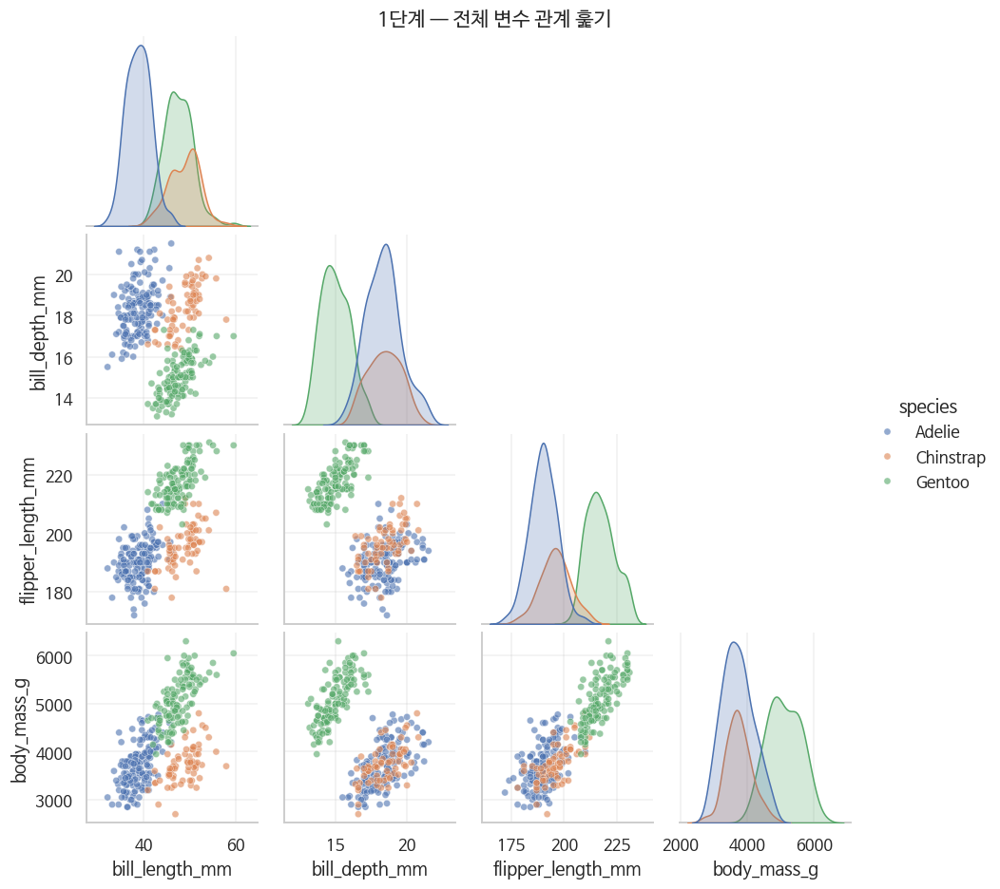

In [139]:
# 2단계: 전체 관계 훑기 (pairplot)
sns.set_theme(style='whitegrid'); set_korean_font()
g = sns.pairplot(df, hue='species', corner=True, diag_kind='kde',
                 plot_kws=dict(alpha=0.6, s=22), height=2.1)
g.figure.suptitle('1단계 — 전체 변수 관계 훑기', y=1.01, fontsize=14)
plt.show()

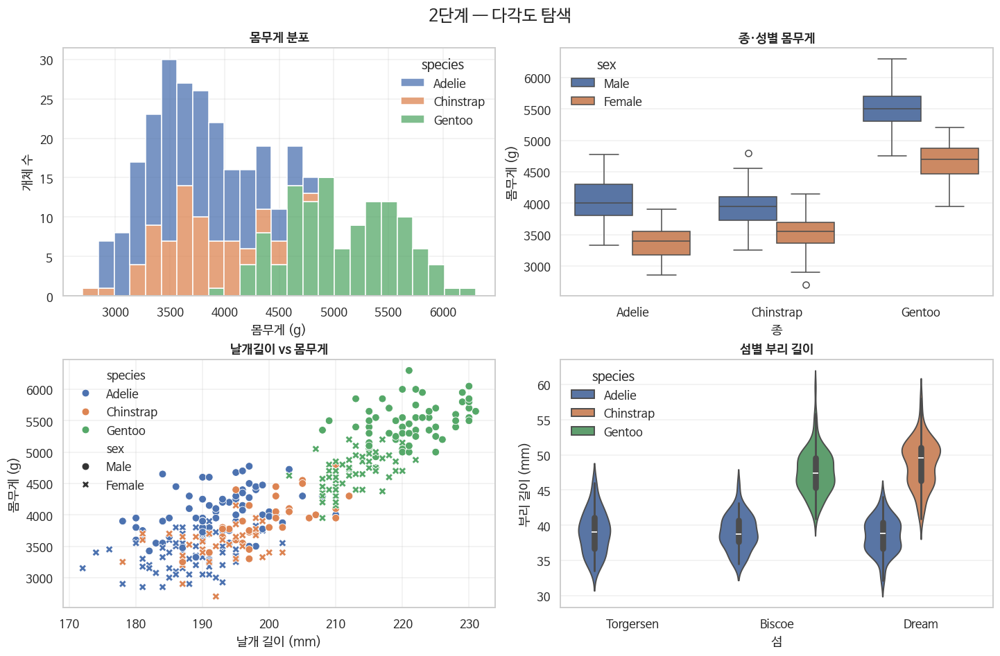

In [140]:
# 3단계: 관심 변수를 여러 각도로 (내가 만든 레이아웃 + axes-level 함수)
fig, axd = plt.subplot_mosaic('AB\nCD', figsize=(13, 8.5), constrained_layout=True)

sns.histplot(data=df, x='body_mass_g', hue='species', multiple='stack',
             bins=25, ax=axd['A'])
axd['A'].set(title='몸무게 분포', xlabel='몸무게 (g)', ylabel='개체 수')

sns.boxplot(data=df, x='species', y='body_mass_g', hue='sex', ax=axd['B'])
axd['B'].set(title='종·성별 몸무게', xlabel='종', ylabel='몸무게 (g)')

sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g',
                hue='species', style='sex', s=50, ax=axd['C'])
axd['C'].set(title='날개길이 vs 몸무게', xlabel='날개 길이 (mm)', ylabel='몸무게 (g)')

sns.violinplot(data=df, x='island', y='bill_length_mm', hue='species', ax=axd['D'])
axd['D'].set(title='섬별 부리 길이', xlabel='섬', ylabel='부리 길이 (mm)')

fig.suptitle('2단계 — 다각도 탐색', fontsize=16)
plt.show()

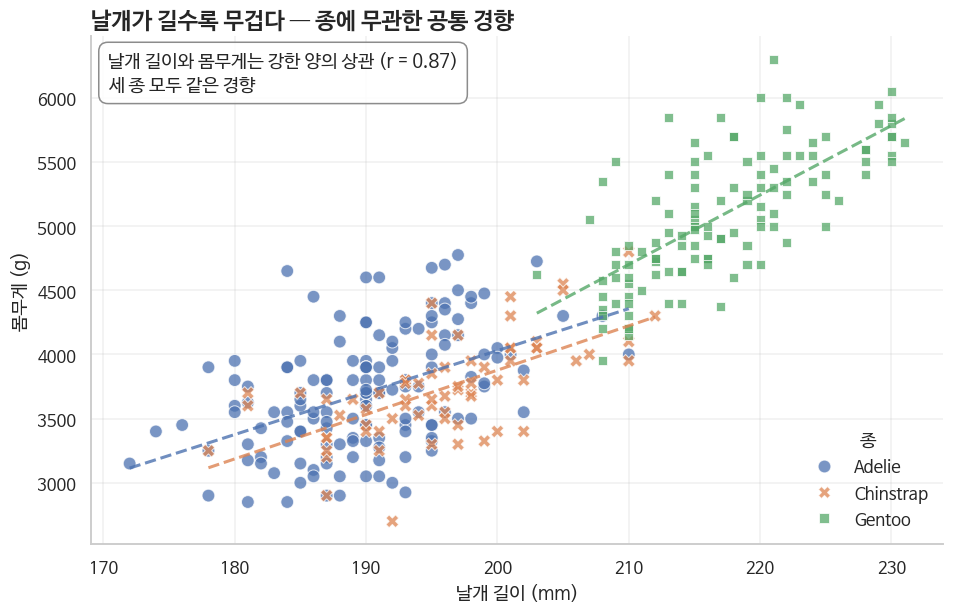

저장: penguins_conclusion.png


In [141]:
# 4단계: 결론 그래프 — seaborn으로 그리고 Matplotlib으로 다듬는다
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g',
                hue='species', style='species', s=70, alpha=0.75,
                palette=my_palette, ax=ax)

# 종별 회귀선을 Matplotlib으로 추가
for sp, c in my_palette.items():
    sub = df[df.species == sp]
    coef = np.polyfit(sub.flipper_length_mm, sub.body_mass_g, 1)
    xs = np.linspace(sub.flipper_length_mm.min(), sub.flipper_length_mm.max(), 50)
    ax.plot(xs, np.polyval(coef, xs), color=c, lw=2, ls='--', alpha=0.8)

# 결론을 글자로
r = df.flipper_length_mm.corr(df.body_mass_g)
ax.text(0.02, 0.97, f'날개 길이와 몸무게는 강한 양의 상관 (r = {r:.2f})\n세 종 모두 같은 경향',
        transform=ax.transAxes, va='top', fontsize=12,
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9))

ax.set(xlabel='날개 길이 (mm)', ylabel='몸무게 (g)')
ax.set_title('날개가 길수록 무겁다 — 종에 무관한 공통 경향', fontsize=15, loc='left')
ax.legend(title='종', loc='lower right')
sns.despine(ax=ax)                      # 위·오른쪽 테두리 제거

fig.savefig('penguins_conclusion.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('저장: penguins_conclusion.png')

> **`sns.despine()`** 은 Matplotlib의 spine 제거를 한 줄로 해줍니다. `sns.despine(left=True, offset=10, trim=True)` 처럼 세밀하게도 가능합니다.
>
> **저장은 항상 Matplotlib 방식입니다.** axes-level이면 `fig.savefig()`, figure-level이면 `g.savefig()`.

---

# Part 10. 새 `objects` 인터페이스 맛보기 (0.12+)

seaborn 0.12부터 **문법이 완전히 다른 새 API**가 추가되었습니다. ggplot2처럼 **레이어를 쌓는** 방식입니다.

```python
import seaborn.objects as so

(so.Plot(data, x='...', y='...')
   .add(so.Dot())
   .add(so.Line(), so.PolyFit())
   .facet('col')
   .label(title='...')
)
```

| 구성 요소 | 역할 | 예 |
|---|---|---|
| `so.Plot(data, x=, y=, color=)` | 데이터와 변수 지정 | |
| **Mark** | 무엇을 그릴지 | `so.Dot`, `so.Line`, `so.Bar`, `so.Area`, `so.Band` |
| **Stat** | 어떻게 집계할지 | `so.Agg`, `so.Hist`, `so.PolyFit`, `so.Est` |
| **Move** | 어떻게 배치할지 | `so.Dodge`, `so.Jitter`, `so.Stack` |
| `.facet()`, `.scale()`, `.label()`, `.theme()` | 분할·스케일·라벨·테마 | |

### 기존 API와 비교

| | 기존 (함수형) | objects |
|---|---|---|
| 배우기 | 쉬움. 함수 이름만 알면 됨 | 개념(Mark/Stat/Move)을 익혀야 함 |
| 자료 | 압도적으로 많음 | 아직 적음 |
| 조합 | 정해진 조합만 | **자유롭게 조합** |
| 성숙도 | 안정 | 발전 중 (API 변경 가능) |

> **입문자 권장:** 지금은 기존 함수형 API를 확실히 익히세요. objects는 '이런 게 있다' 정도로 알아두고, 나중에 복잡한 그래프가 필요할 때 돌아오면 됩니다.

/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 45216 (\N{HANGUL SYLLABLE NAL}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 44600 (\N{HANGUL SYLLABLE GIL}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 478

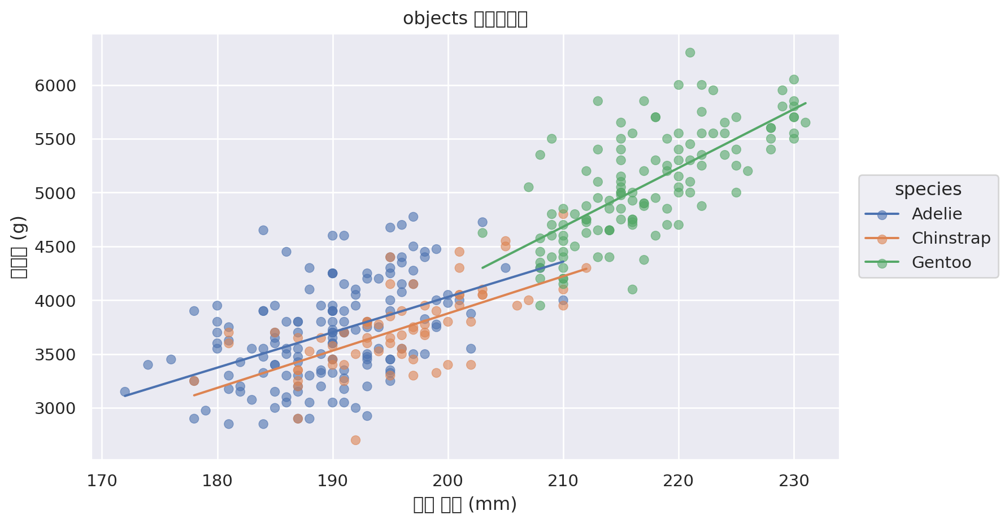

In [142]:
import seaborn.objects as so

p = (so.Plot(penguins, x='flipper_length_mm', y='body_mass_g', color='species')
       .add(so.Dot(alpha=0.6))
       .add(so.Line(), so.PolyFit(order=1))
       .label(x='날개 길이 (mm)', y='몸무게 (g)', title='objects 인터페이스')
       .layout(size=(8, 5)))
p

/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  self._figure.savefig(buffer, dpi=dpi, format="png", bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/seaborn/_core/plot.py:1043: UserWarning: Glyph

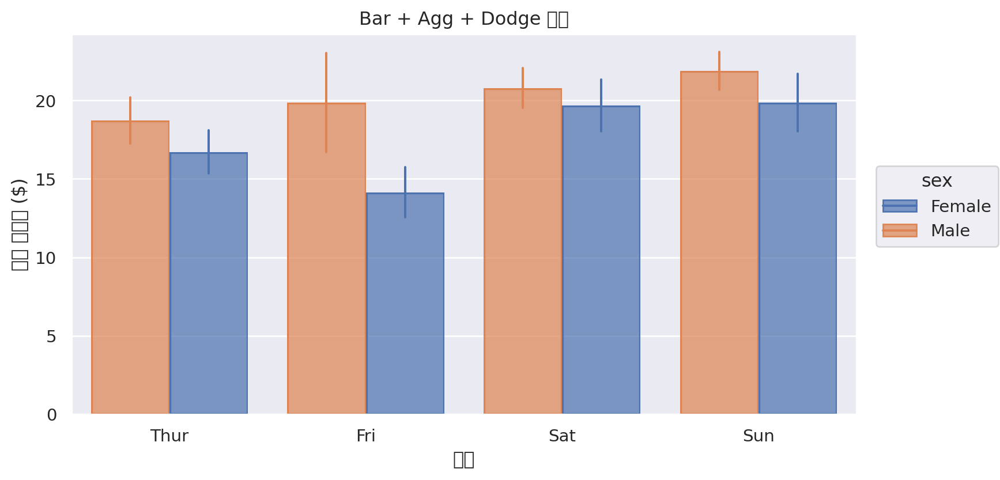

In [143]:
# 집계 + 배치까지 레이어로
p2 = (so.Plot(tips, x='day', y='total_bill', color='sex')
        .add(so.Bar(), so.Agg('mean'), so.Dodge())
        .add(so.Range(), so.Est(errorbar='se'), so.Dodge())
        .label(x='요일', y='평균 결제액 ($)', title='Bar + Agg + Dodge 조합')
        .layout(size=(8, 4.5)))
p2

---

# 부록 A. 치트시트

## A.1 시작 템플릿 (복붙용)
```python
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns, platform

sns.set_theme(style='whitegrid', context='notebook')   # 1) 테마 먼저
s = platform.system()                                   # 2) 폰트 나중
plt.rcParams['font.family'] = ('Malgun Gothic' if s=='Windows'
                               else 'AppleGothic' if s=='Darwin'
                               else 'NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False
```

## A.2 함수 고르기
| 보고 싶은 것 | axes-level | figure-level |
|---|---|---|
| 두 수치 변수 관계 | `scatterplot` | `relplot(kind='scatter')` |
| 시간에 따른 변화 | `lineplot` | `relplot(kind='line')` |
| 한 변수의 분포 | `histplot`, `kdeplot`, `ecdfplot` | `displot(kind=...)` |
| 범주별 분포 | `boxplot`, `violinplot` | `catplot(kind='box')` |
| 범주별 평균 | `barplot`, `pointplot` | `catplot(kind='bar')` |
| 범주별 개수 | `countplot` | `catplot(kind='count')` |
| 관측치 그대로 | `stripplot`, `swarmplot` | `catplot(kind='strip')` |
| 회귀선 | `regplot` | `lmplot` |
| 상관행렬 | `heatmap` | `clustermap` |
| 전체 변수쌍 | — | `pairplot` |
| 산점도 + 주변분포 | — | `jointplot` |

## A.3 자주 쓰는 인자
```python
sns.함수(data=df, x='열', y='열',
         hue='그룹열', size='열', style='열',      # 그룹 구분
         col='열', row='열', col_wrap=3,           # figure-level 분할
         order=[...], hue_order=[...],             # 범주 순서
         palette='Set2', alpha=0.7,                # 색·투명도
         errorbar=('ci', 95),                      # 오차 표현
         estimator='mean',                         # 집계 방법
         height=4, aspect=1.2,                     # figure-level 크기
         ax=ax)                                    # axes-level 전용
```

## A.4 마무리 (Matplotlib으로)
```python
ax.set(title=..., xlabel=..., ylabel=..., xlim=..., ylim=...)
ax.legend(title='범례', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine(ax=ax)
fig.savefig('out.png', dpi=200, bbox_inches='tight', facecolor='white')
```

## A.5 흔한 실수
| 증상 | 원인 | 해결 |
|---|---|---|
| 한글 깨짐 | `set_theme()` 이 폰트 초기화 | 테마 → 폰트 순서로 |
| `ax=` 오류 | figure-level 함수에 `ax=` 전달 | axes-level 함수로 바꾸거나 `g.axes` 사용 |
| `hue` 무시됨 | `regplot`에는 `hue` 없음 | `lmplot` 사용 |
| 막대가 합계가 아님 | `barplot` 기본은 **평균** | `estimator='sum'` |
| 그래프가 안 나옴 | wide-form 데이터 | `pd.melt()` 로 long-form 변환 |
| `distplot` 없음 | 최신 버전에서 삭제 | `histplot` / `displot` |
| 그룹 크기 달라 비교 왜곡 | `stat='count'` | `stat='density', common_norm=False` |


---

# 마무리

## 기억할 세 가지

1. **figure-level인지 axes-level인지 먼저 확인하세요.** `ax=` 가 되는지 안 되는지가 여기서 갈립니다.
2. **데이터는 long-form(tidy)으로.** 안 되면 `pd.melt()`.
3. **탐색은 seaborn, 마무리는 Matplotlib.** `ax.set()`, `sns.despine()`, `fig.savefig()`.

## 참고 자료

- 공식 문서: https://seaborn.pydata.org/
- 예제 갤러리: https://seaborn.pydata.org/examples/index.html
- 함수별 API: https://seaborn.pydata.org/api.html
- objects 인터페이스: https://seaborn.pydata.org/tutorial/objects_interface.html

> 갤러리에서 원하는 그림을 찾아 코드를 가져온 뒤 내 데이터 열 이름으로 바꾸는 것 — 이것이 실무에서 가장 빠른 방법입니다.


# Plotly
## 데이터 분석 입문자를 위한 인터랙티브 시각화 교안


### 학습 방법
- 그래프가 나오면 **마우스를 올리고, 드래그해 확대하고, 범례를 클릭**해 보세요. 그게 Plotly의 핵심입니다.


---

# Part 0. Plotly란?

## 0.1 한 줄 요약

> **마우스로 조작할 수 있는 그래프를 파이썬으로 만드는 라이브러리.**

Matplotlib이 만드는 것은 **그림 파일**입니다. Plotly가 만드는 것은 **작은 웹페이지**입니다. 그래서 확대·축소, 값 확인, 계열 켜고 끄기가 됩니다.

## 0.2 세 라이브러리 비교

| | Matplotlib | Seaborn | **Plotly** |
|---|---|---|---|
| 결과물 | 정적 이미지 | 정적 이미지 | **인터랙티브 HTML** |
| 마우스 조작 | 없음 | 없음 | **확대·호버·토글** |
| 논문·인쇄 | 최적 | 좋음 | 이미지로 내보내야 함 |
| 공유 | 이미지 첨부 | 이미지 첨부 | **HTML 파일 하나** |
| 코드 길이 | 김 | 짧음 | **짧음** |
| 대용량 데이터 | 빠름 | 빠름 | 주의 필요 |
| 웹 대시보드 | 어려움 | 어려움 | **Dash로 확장** |

## 0.3 언제 Plotly를 쓰나

**쓰면 좋을 때**

- 값이 정확히 얼마인지 **마우스로 확인**해야 할 때
- 데이터가 촘촘해 **확대해서 봐야** 할 때
- 계열이 많아 **켜고 끄며** 비교해야 할 때
- 시간에 따른 변화를 **애니메이션**으로 보여줄 때
- 보고서를 **HTML 링크로 공유**할 때

**안 쓰는 게 나을 때**

- 논문 · 인쇄물 (Matplotlib이 더 정밀)
- 점이 수십만 개 이상 (브라우저가 버거워함 — Part 8 참고)
- 아주 특수한 커스텀 그림

---

# Part 1. 준비

## 1.1 설치

```bash
pip install plotly
pip install nbformat            # 주피터에서 표시하려면 필요
pip install -U kaleido          # PNG/PDF 저장이 필요할 때만
```

Colab에는 이미 설치되어 있습니다.

In [144]:
import numpy as np
import pandas as pd
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

print('plotly', plotly.__version__)
print('pandas', pd.__version__)

plotly 5.24.1
pandas 2.2.2


## 1.2 렌더러 — 그래프가 안 보일 때

Plotly가 **어디에 그림을 그릴지**를 정하는 설정입니다. 그래프가 빈칸으로 나오면 십중팔구 이 문제입니다.

| 환경 | 렌더러 |
|---|---|
| Jupyter Lab / Notebook | `'notebook'` 또는 `'jupyterlab'` |
| Google Colab | `'colab'` |
| VS Code | `'vscode'` |
| 어디서나 확실히 보고 싶을 때 | `'browser'` (새 탭이 열림) |
| GitHub에 올릴 노트북 | `'png'` (정적 이미지로 박제, kaleido 필요) |

> 보통은 자동 감지가 잘 됩니다. 문제가 생기면 아래에서 바꿔 보세요.

In [145]:
print('현재 렌더러 :', pio.renderers.default)
print('사용 가능   :', list(pio.renderers)[:12])

# 문제가 있을 때만 주석을 푸세요
# pio.renderers.default = 'notebook'
# pio.renderers.default = 'colab'
# pio.renderers.default = 'browser'
# pio.renderers.default = 'png'

현재 렌더러 : colab
사용 가능   : ['plotly_mimetype', 'jupyterlab', 'nteract', 'vscode', 'notebook', 'notebook_connected', 'kaggle', 'azure', 'colab', 'cocalc', 'databricks', 'json']


## 1.3 첫 그래프 — 직접 만져 보세요

아래 그래프가 나오면 이렇게 해 보세요.

- 점 위에 **마우스를 올리면** 값이 뜹니다
- **드래그**하면 그 영역만 확대됩니다
- **더블클릭**하면 원래대로 돌아옵니다
- 오른쪽 위 **툴바**로 저장·확대·초기화를 할 수 있습니다
- 범례의 항목을 **클릭**하면 그 계열이 사라졌다 나타납니다

In [146]:
df = px.data.iris()      # 인터넷 없이 쓸 수 있는 내장 데이터

fig = px.scatter(df, x='sepal_width', y='sepal_length', color='species',
                 title='붓꽃 데이터 — 마우스를 올리고 드래그해 보세요')
fig.show()

## 1.4 내장 예제 데이터 (인터넷 불필요)

| 함수 | 내용 | 주요 열 |
|---|---|---|
| `px.data.iris()` | 붓꽃 | sepal/petal length·width, species |
| `px.data.tips()` | 식당 팁 | total_bill, tip, sex, smoker, day, time, size |
| `px.data.gapminder()` | 국가별 기대수명·GDP (1952~2007) | country, continent, year, lifeExp, pop, gdpPercap |
| `px.data.stocks()` | 주가 지수 (2018~2019) | date, GOOG, AAPL, AMZN, FB, NFLX, MSFT |
| `px.data.medals_long()` | 올림픽 메달 | nation, medal, count |
| `px.data.wind()` | 풍향·풍속 | direction, strength, frequency |
| `px.data.election()` | 몬트리올 선거 | district, Coderre, Bergeron, Joly |

In [147]:
iris = px.data.iris()
tips = px.data.tips()
gap = px.data.gapminder()
stocks = px.data.stocks()
medals = px.data.medals_long()

for name, d in [('iris', iris), ('tips', tips), ('gapminder', gap),
                ('stocks', stocks), ('medals', medals)]:
    print(f'{name:12s} {d.shape}')

gap.head()

iris         (150, 6)
tips         (244, 7)
gapminder    (1704, 8)
stocks       (105, 7)
medals       (9, 3)


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


## 1.5 한글은?

Plotly는 **브라우저 폰트**를 쓰기 때문에 Matplotlib처럼 한글이 깨지는 일이 거의 없습니다. 별도 설정 없이 한글 제목·라벨이 나옵니다.

다만 `write_image()` 로 PNG를 저장할 때는 시스템에 한글 폰트가 있어야 합니다. 그때는 `font_family` 를 지정하세요.

In [148]:
fig = px.bar(x=['서울', '부산', '대구', '인천'], y=[941, 334, 238, 297],
             title='한글 확인 — 별도 폰트 설정이 필요 없습니다',
             labels={'x': '도시', 'y': '인구(만명)'})
fig.update_layout(font_family='Malgun Gothic, AppleGothic, NanumGothic, sans-serif')
fig.show()

---

# Part 2. 핵심 개념

## 2.1 두 가지 API — express vs graph_objects

Plotly에는 그래프를 만드는 **두 가지 방법**이 있습니다. Seaborn의 figure-level / axes-level 구분과 비슷한 관계입니다.

| | **plotly.express (px)** | **plotly.graph_objects (go)** |
|---|---|---|
| 별칭 | `px` | `go` |
| 성격 | 고수준 · 한 줄 | 저수준 · 조립식 |
| 입력 | **DataFrame + 열 이름** | 배열, trace 객체 |
| 그룹 나누기 | `color=`, `facet_col=` 한 줄 | 반복문으로 trace 추가 |
| 범례·색·호버 | 자동 | 직접 설정 |
| 자유도 | 정해진 차트 | **무엇이든** |
| 반환값 | **`go.Figure`** | `go.Figure` |

> **핵심: 둘 다 결국 같은 `go.Figure` 를 만듭니다.**
> 그래서 `px` 로 빠르게 만든 뒤 `go` 의 메서드(`update_layout`, `add_trace`)로 다듬는 것이 **실무 표준 흐름**입니다.
>
> ```
> px 로 만들고  →  fig.update_*() 로 다듬는다
> ```

In [149]:
# 같은 그래프를 두 방식으로

# 방법 A — plotly express
fig_a = px.scatter(iris, x='sepal_width', y='sepal_length', color='species',
                   title='express — 한 줄')

# 방법 B — graph_objects (그룹마다 trace를 직접 추가)
fig_b = go.Figure()
for sp in iris['species'].unique():
    sub = iris[iris.species == sp]
    fig_b.add_trace(go.Scatter(x=sub.sepal_width, y=sub.sepal_length,
                               mode='markers', name=sp))
fig_b.update_layout(title='graph_objects — 반복문 필요',
                    xaxis_title='sepal_width', yaxis_title='sepal_length')

print('px 반환 타입 :', type(fig_a))
print('go 반환 타입 :', type(fig_b))
fig_a.show()
fig_b.show()

px 반환 타입 : <class 'plotly.graph_objs._figure.Figure'>
go 반환 타입 : <class 'plotly.graph_objs._figure.Figure'>


## 2.2 Figure의 구조 — 이걸 알면 전부 통한다

Plotly의 그래프는 사실 **딕셔너리 하나**입니다. 크게 세 부분으로 되어 있습니다.

```
Figure
 ├── data     : trace(그려지는 것)들의 리스트   ← 선, 막대, 점...
 ├── layout   : 그림 전체 설정                  ← 제목, 축, 범례, 여백, 색
 └── frames   : 애니메이션 프레임 (선택)
```

| 부분 | 무엇 | 바꾸는 메서드 |
|---|---|---|
| `fig.data` | trace 목록 (선/막대/점 각각 하나씩) | `fig.update_traces()`, `fig.add_trace()` |
| `fig.layout` | 제목·축·범례·크기·색 | `fig.update_layout()`, `fig.update_xaxes()` |
| `fig.frames` | 애니메이션 | `px(animation_frame=...)` |

> **update 메서드 3형제만 기억하면 됩니다.**
> - `fig.update_layout(...)` — 그림 전체
> - `fig.update_traces(...)` — 그려진 것들
> - `fig.update_xaxes(...)` / `update_yaxes(...)` — 축

In [150]:
fig = px.scatter(iris, x='sepal_width', y='sepal_length', color='species')

print('trace 개수 :', len(fig.data))
for t in fig.data:
    print(f'   type={t.type:10s} name={t.name:12s} 점 개수={len(t.x)}')

print('\nlayout 제목 :', fig.layout.title.text)
print('x축 제목    :', fig.layout.xaxis.title.text)
print('\n--- 딕셔너리로 들여다보기 ---')
print(list(fig.to_dict().keys()))

trace 개수 : 3
   type=scatter    name=setosa       점 개수=50
   type=scatter    name=versicolor   점 개수=50
   type=scatter    name=virginica    점 개수=50

layout 제목 : None
x축 제목    : sepal_width

--- 딕셔너리로 들여다보기 ---
['data', 'layout']


In [151]:
# px로 만들고 → update로 다듬는 실무 흐름
fig = px.scatter(iris, x='sepal_width', y='sepal_length', color='species')

fig.update_traces(marker=dict(size=11, line=dict(width=1, color='white')),
                  opacity=0.8)

fig.update_layout(title='붓꽃 품종별 꽃받침 크기',
                  xaxis_title='꽃받침 너비 (cm)',
                  yaxis_title='꽃받침 길이 (cm)',
                  legend_title='품종',
                  width=800, height=500,
                  template='plotly_white')

fig.update_xaxes(showgrid=True, gridcolor='#eee')
fig.show()

### `update_layout` 인자를 쓰는 두 가지 표기

중첩된 설정은 **딕셔너리**로도, **밑줄 표기**로도 쓸 수 있습니다. 둘은 완전히 같습니다.

```python
# 방법 1 — 딕셔너리
fig.update_layout(title=dict(text='제목', font=dict(size=22)))

# 방법 2 — 밑줄(magic underscore) 표기  ← 짧아서 자주 씀
fig.update_layout(title_text='제목', title_font_size=22)
```

---

# Part 3. Plotly Express 공통 문법

**모든 px 함수가 거의 같은 인자를 받습니다.** 이 표만 익히면 차트 종류가 바뀌어도 그대로 씁니다.

| 인자 | 뜻 |
|---|---|
| `data_frame` | DataFrame (첫 번째 인자) |
| `x`, `y` | 축에 놓을 열 이름 |
| `color` | **색**으로 그룹 구분 (범주형이면 팔레트, 숫자면 컬러스케일) |
| `size` | **점 크기**로 값 표현 |
| `symbol` | **마커 모양**으로 그룹 구분 |
| `facet_col`, `facet_row` | 패널을 가로/세로로 분할 |
| `facet_col_wrap` | 패널 줄바꿈 개수 |
| `hover_name` | 호버 상자의 **제목**이 될 열 |
| `hover_data` | 호버에 **추가로 보여줄** 열 목록 |
| `text` | 그래프 위에 **직접 표시**할 값 |
| `animation_frame` | 이 열의 값마다 **애니메이션 프레임** 생성 |
| `animation_group` | 프레임 사이에서 같은 개체로 이어줄 열 |
| `labels` | 열 이름 → 표시 이름 매핑 `{'lifeExp': '기대수명'}` |
| `category_orders` | 범주 순서 지정 |
| `color_discrete_map` | 범주별 색 직접 지정 |
| `color_continuous_scale` | 연속형 컬러스케일 |
| `range_x`, `range_y` | 축 범위 |
| `log_x`, `log_y` | 로그 축 |
| `template` | 테마 |
| `title`, `width`, `height` | 제목·크기 |

In [152]:
# 인자 하나로 표현이 계속 늘어나는 과정
g2007 = gap[gap.year == 2007]

fig = px.scatter(g2007, x='gdpPercap', y='lifeExp')
fig.update_layout(title='1단계 — 기본', height=350)
fig.show()

fig = px.scatter(g2007, x='gdpPercap', y='lifeExp', color='continent')
fig.update_layout(title='2단계 — color 추가', height=350)
fig.show()

fig = px.scatter(g2007, x='gdpPercap', y='lifeExp',
                 color='continent', size='pop', size_max=55)
fig.update_layout(title='3단계 — size 추가 (버블 차트)', height=350)
fig.show()

In [153]:
# 4단계 — 호버 · 로그축 · 한글 라벨까지
fig = px.scatter(g2007, x='gdpPercap', y='lifeExp',
                 color='continent', size='pop', size_max=55,
                 hover_name='country',
                 hover_data={'pop': ':,.0f', 'gdpPercap': ':,.0f'},
                 log_x=True,
                 labels={'gdpPercap': '1인당 GDP (달러, 로그)',
                         'lifeExp': '기대수명 (년)',
                         'continent': '대륙', 'pop': '인구'},
                 title='2007년 소득과 기대수명 — 국가 위에 마우스를 올려 보세요')
fig.update_layout(height=520, template='plotly_white')
fig.show()

## 3.1 facet — 패널 나누기

`facet_col`, `facet_row` 한 줄이면 그룹별로 그래프가 쪼개집니다.

In [154]:
fig = px.scatter(tips, x='total_bill', y='tip',
                 color='sex', facet_col='time', facet_row='smoker',
                 trendline='ols',                # 추세선 (statsmodels 필요)
                 labels={'total_bill': '결제액', 'tip': '팁'},
                 title='facet + 추세선')
fig.update_layout(height=600)
fig.show()

> `trendline='ols'` 는 `statsmodels` 가 필요합니다. 없으면 `pip install statsmodels` 하시거나 그 인자를 빼세요.
> 다른 옵션: `'lowess'`(비모수), `'rolling'`(이동평균), `'expanding'`

### facet 제목 다듬기

기본 패널 제목은 `time=Dinner` 처럼 나옵니다. 보기 싫으면 아래처럼 정리합니다.

In [155]:
fig = px.histogram(tips, x='total_bill', facet_col='day', facet_col_wrap=2,
                   color='sex', height=520, title='facet 제목 정리')

# 'day=Sun' -> 'Sun'
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))
fig.show()

---

# Part 4. 차트 종류별 가이드

| 목적 | 함수 |
|---|---|
| 시간에 따른 변화 | `px.line`, `px.area` |
| 두 변수 관계 | `px.scatter`, `px.density_heatmap`, `px.density_contour` |
| 항목 비교 | `px.bar` |
| 분포 | `px.histogram`, `px.box`, `px.violin`, `px.strip`, `px.ecdf` |
| 구성비 | `px.pie`, `px.sunburst`, `px.treemap`, `px.icicle`, `px.funnel` |
| 행렬 | `px.imshow`, `px.scatter_matrix` |
| 다차원 | `px.parallel_coordinates`, `px.parallel_categories` |
| 지도 | `px.choropleth`, `px.scatter_geo`, `px.line_geo` |
| 3D | `px.scatter_3d`, `px.line_3d`, `go.Surface` |

## 4.1 선 그래프

In [156]:
# wide-form 을 그대로 넣어도 됩니다 (열 여러 개를 y에)
fig = px.line(stocks, x='date', y=['GOOG', 'AAPL', 'AMZN'],
              title='주가 지수 — 범례를 클릭해 계열을 켜고 꺼 보세요',
              labels={'value': '지수(2018-01-01=1)', 'date': '날짜', 'variable': '종목'})
fig.update_layout(hovermode='x unified', height=450)
fig.show()

> **`hovermode='x unified'`** 는 실무에서 아주 유용합니다. 같은 x값의 **모든 계열을 한 상자에** 모아 보여줍니다. 시계열 비교에는 거의 항상 켜세요.
>
> 다른 값: `'x'`, `'y'`, `'closest'`(기본), `'y unified'`, `False`

In [157]:
# long-form 이면 color= 로 계열 구분
gap5 = gap[gap.country.isin(['Korea, Rep.', 'Japan', 'China', 'India', 'United States'])]

fig = px.line(gap5, x='year', y='lifeExp', color='country', markers=True,
              labels={'year': '연도', 'lifeExp': '기대수명(년)', 'country': '국가'},
              title='국가별 기대수명 추이')
fig.update_traces(line_width=3)
fig.update_layout(hovermode='x unified', height=450, template='plotly_white')
fig.show()

## 4.2 막대 그래프

In [158]:
# 그룹 / 누적 / 100% 누적
for mode, title in [('group', '그룹 막대'), ('stack', '누적 막대'), ('relative', '상대 누적')]:
    fig = px.bar(medals, x='nation', y='count', color='medal', barmode=mode,
                 text_auto=True, title=title, height=350)
    fig.show()

In [159]:
# 정렬된 가로 막대 — 항목 이름이 길 때
top = (gap[gap.year == 2007].nlargest(15, 'gdpPercap')
       .sort_values('gdpPercap'))            # 큰 값이 위로 오게 오름차순

fig = px.bar(top, x='gdpPercap', y='country', orientation='h',
             color='continent', text='gdpPercap',
             labels={'gdpPercap': '1인당 GDP (달러)', 'country': '국가', 'continent': '대륙'},
             title='2007년 1인당 GDP 상위 15개국')
fig.update_traces(texttemplate='%{text:,.0f}', textposition='outside')
fig.update_layout(height=600, template='plotly_white')
fig.show()

> **정렬 규칙:** `px.bar` 는 데이터 순서대로 그립니다. 가로 막대(`orientation='h'`)는 **아래에서 위로** 쌓이므로, 큰 값을 위에 두려면 **오름차순**으로 정렬해서 넣습니다.
>
> 강제로 순서를 정하려면: `fig.update_yaxes(categoryorder='total ascending')`

## 4.3 분포

In [160]:
fig = px.histogram(tips, x='total_bill', color='sex', nbins=30,
                   marginal='box',            # 위에 박스플롯을 같이
                   opacity=0.7, barmode='overlay',
                   labels={'total_bill': '결제액', 'sex': '성별'},
                   title='히스토그램 + 주변 박스플롯')
fig.update_layout(height=480)
fig.show()

> `marginal` 옵션: `'box'`, `'violin'`, `'rug'`, `'histogram'`
> `histnorm` 옵션: `None`(개수), `'percent'`, `'probability'`, `'density'`, `'probability density'`

In [161]:
fig = make_subplots(rows=1, cols=3,
                    subplot_titles=('box', 'violin (box 포함)', 'strip'))

b = px.box(tips, x='day', y='total_bill', color='sex')
v = px.violin(tips, x='day', y='total_bill', color='sex', box=True)
s = px.strip(tips, x='day', y='total_bill', color='sex')

for t in b.data:
    fig.add_trace(t, row=1, col=1)
for t in v.data:
    fig.add_trace(t.update(showlegend=False), row=1, col=2)
for t in s.data:
    fig.add_trace(t.update(showlegend=False), row=1, col=3)

fig.update_layout(height=430, boxmode='group', violinmode='group',
                  title='분포 비교 3종')
fig.show()

In [162]:
# 박스플롯에 실제 관측치 겹치기 — 표본 수가 보여서 좋습니다
fig = px.box(tips, x='day', y='total_bill', color='smoker',
             points='all',                    # 'all', 'outliers', 'suspectedoutliers', False
             notched=True,
             labels={'day': '요일', 'total_bill': '결제액', 'smoker': '흡연'},
             title='박스플롯 + 전체 관측치')
fig.update_layout(height=480, template='plotly_white')
fig.show()

In [163]:
# ECDF — 구간(bin)에 좌우되지 않는 분포 비교
fig = px.ecdf(tips, x='total_bill', color='sex', markers=False,
              labels={'total_bill': '결제액'},
              title='누적분포(ECDF) — bins 선택에 영향받지 않음')
fig.update_layout(height=420)
fig.show()

## 4.4 구성비 — 파이 · 선버스트 · 트리맵

> 파이는 항목이 4개를 넘으면 읽기 어렵습니다. **계층 구조가 있다면 선버스트나 트리맵**이 훨씬 낫습니다. 게다가 이들은 **클릭하면 파고들 수 있어** Plotly의 장점이 잘 드러납니다.

In [164]:
cont = g2007.groupby('continent', as_index=False)['pop'].sum()

fig = px.pie(cont, names='continent', values='pop', hole=0.45,
             title='2007년 대륙별 인구 (도넛)')
fig.update_traces(textinfo='label+percent', pull=[0, 0, 0.06, 0, 0])
fig.update_layout(height=450)
fig.show()

In [165]:
# 선버스트 — 조각을 클릭하면 그 안으로 들어갑니다
fig = px.sunburst(g2007, path=['continent', 'country'], values='pop',
                  color='lifeExp', color_continuous_scale='RdYlGn',
                  hover_data={'gdpPercap': ':,.0f'},
                  title='대륙 > 국가 인구 (색 = 기대수명) — 조각을 클릭해 보세요')
fig.update_layout(height=620)
fig.show()

In [166]:
# 트리맵 — 넓이로 크기를 비교
fig = px.treemap(g2007, path=[px.Constant('전체'), 'continent', 'country'],
                 values='pop', color='lifeExp',
                 color_continuous_scale='RdBu',
                 color_continuous_midpoint=np.average(g2007.lifeExp, weights=g2007['pop']),
                 title='트리맵 — 넓이=인구, 색=기대수명')
fig.update_layout(height=600, margin=dict(t=60, l=10, r=10, b=10))
fig.show()

## 4.5 히트맵과 행렬

In [167]:
corr = iris.select_dtypes('number').drop(columns=['species_id'], errors='ignore').corr()

fig = px.imshow(corr, text_auto='.2f', aspect='auto',
                color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                title='상관행렬 히트맵')
fig.update_layout(height=480, width=560)
fig.show()

In [171]:
# 2차원 밀도 — 점이 많을 때 산점도 대신
fig = px.density_heatmap(
    tips,
    x='total_bill',
    y='tip',
    nbinsx=25,
    nbinsy=25,
    marginal_x='histogram',
    marginal_y='histogram',
    color_continuous_scale=px.colors.sequential.Blues,
    title='2D 밀도 히트맵 + 주변 분포',
    height=560
)

fig.show()

In [172]:
# 산점도 행렬 — 드래그로 한 칸을 선택하면 다른 칸에도 반영됩니다 (브러싱)
fig = px.scatter_matrix(iris,
                        dimensions=['sepal_width', 'sepal_length',
                                    'petal_width', 'petal_length'],
                        color='species', opacity=0.7,
                        title='산점도 행렬 — 한 칸을 드래그해 보세요')
fig.update_traces(diagonal_visible=False, showupperhalf=False, marker_size=5)
fig.update_layout(height=680)
fig.show()

In [173]:
# 평행 좌표 — 축을 드래그해 범위를 걸러낼 수 있습니다
fig = px.parallel_coordinates(
    iris, color='species_id',
    dimensions=['sepal_width', 'sepal_length', 'petal_width', 'petal_length'],
    color_continuous_scale=px.colors.diverging.Tealrose,
    title='평행 좌표 — 축 위를 세로로 드래그해 필터링해 보세요')
fig.update_layout(height=480)
fig.show()

## 4.6 지도

`choropleth`, `scatter_geo` 는 **토큰 없이** 바로 됩니다. (Mapbox 기반 함수는 지도 타일 제공자 설정이 필요할 수 있습니다)

In [174]:
fig = px.choropleth(g2007, locations='iso_alpha', color='lifeExp',
                    hover_name='country',
                    color_continuous_scale='Viridis',
                    projection='natural earth',
                    labels={'lifeExp': '기대수명'},
                    title='2007년 기대수명 세계 지도')
fig.update_layout(height=520, margin=dict(t=60, l=0, r=0, b=0))
fig.show()

In [175]:
fig = px.scatter_geo(g2007, locations='iso_alpha', color='continent',
                     hover_name='country', size='pop', size_max=45,
                     projection='orthographic',        # 지구본 — 드래그해 돌려 보세요
                     title='지구본 위 인구 — 드래그해서 돌려 보세요')
fig.update_layout(height=560)
fig.show()

## 4.7 3D

> 3D는 **멋있지만 대개 읽기 어렵습니다.** 각도에 따라 값이 왜곡되어 보입니다. Plotly에서는 회전이 가능해 정적 3D보다는 낫지만, 2D로 표현 가능하면 2D를 쓰세요.

In [176]:
fig = px.scatter_3d(iris, x='sepal_length', y='sepal_width', z='petal_width',
                    color='species', size='petal_length', size_max=18, opacity=0.7,
                    title='3D 산점도 — 드래그해 회전시켜 보세요')
fig.update_layout(height=620, margin=dict(t=50, l=0, r=0, b=0))
fig.show()

In [177]:
# 3D 표면 (graph_objects)
xs = np.linspace(-3, 3, 60)
ys = np.linspace(-3, 3, 60)
X, Y = np.meshgrid(xs, ys)
Z = np.sin(np.sqrt(X**2 + Y**2)) * np.exp(-0.1 * (X**2 + Y**2))

fig = go.Figure(go.Surface(z=Z, x=xs, y=ys, colorscale='Viridis'))
fig.update_layout(title='3D 표면', height=560,
                  scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='z'))
fig.show()

---

# Part 5. 레이아웃과 스타일

## 5.1 템플릿 — 테마 한 줄로 바꾸기

| 템플릿 | 특징 |
|---|---|
| `plotly` | 기본 (회색 배경) |
| `plotly_white` | **흰 배경 — 보고서에 가장 무난** |
| `plotly_dark` | 어두운 배경 |
| `ggplot2`, `seaborn` | 해당 라이브러리 느낌 |
| `simple_white` | 최소한의 장식 (논문풍) |
| `presentation` | 글자가 큼 (발표용) |

In [178]:
print(list(pio.templates))

for tpl in ['plotly', 'plotly_white', 'simple_white', 'plotly_dark', 'presentation']:
    fig = px.line(stocks, x='date', y=['GOOG', 'AAPL'], template=tpl,
                  title=f"template='{tpl}'", height=280)
    fig.show()

['ggplot2', 'seaborn', 'simple_white', 'plotly', 'plotly_white', 'plotly_dark', 'presentation', 'xgridoff', 'ygridoff', 'gridon', 'none']


In [179]:
# 전역 기본 템플릿 지정 — 노트북 맨 위에 한 번
pio.templates.default = 'plotly_white'
print('기본 템플릿:', pio.templates.default)

기본 템플릿: plotly_white


## 5.2 자주 쓰는 layout 설정

| 목적 | 코드 |
|---|---|
| 제목 | `title_text='제목'`, `title_x=0.5`(가운데) |
| 크기 | `width=900, height=500` |
| 여백 | `margin=dict(t=60, l=60, r=30, b=60)` |
| 폰트 | `font=dict(family='Malgun Gothic', size=13, color='#333')` |
| 배경 | `plot_bgcolor='white'`, `paper_bgcolor='#fafafa'` |
| 범례 위치 | `legend=dict(orientation='h', y=1.02, x=1, xanchor='right', yanchor='bottom')` |
| 범례 숨기기 | `showlegend=False` |
| 호버 방식 | `hovermode='x unified'` |
| 막대 모드 | `barmode='group'` / `'stack'` / `'relative'` / `'overlay'` |
| 컬러바 제목 | `coloraxis_colorbar_title='값'` |

In [180]:
fig = px.line(gap5, x='year', y='lifeExp', color='country', markers=True)

fig.update_layout(
    title=dict(text='국가별 기대수명 추이<br><sup>출처: Gapminder</sup>',
               x=0.02, xanchor='left', font=dict(size=20)),
    xaxis_title='연도', yaxis_title='기대수명 (년)',
    legend=dict(orientation='h', y=1.02, yanchor='bottom',
                x=1, xanchor='right', title=None),
    font=dict(family='Malgun Gothic, AppleGothic, sans-serif', size=13),
    hovermode='x unified',
    margin=dict(t=90, l=60, r=30, b=50),
    width=900, height=480,
    plot_bgcolor='white',
)
fig.show()

> 제목에 **`<br>` 과 `<sup>` 같은 HTML 태그**를 쓸 수 있습니다. 부제목을 다는 표준 방법입니다.
> 자주 쓰는 태그: `<b>굵게</b>`, `<i>기울임</i>`, `<sub>아래첨자</sub>`, `<span style='color:red'>색</span>`

## 5.3 축 설정

In [181]:
fig = px.line(stocks, x='date', y='GOOG')

fig.update_xaxes(
    title='날짜',
    dtick='M3',                       # 3개월 간격 눈금
    tickformat='%Y-%m',
    showgrid=True, gridcolor='#f0f0f0',
    showline=True, linecolor='#ccc', mirror=False,
    rangeslider_visible=True,         # 아래에 축소 지도가 생깁니다
)
fig.update_yaxes(
    title='지수',
    tickformat='.0%',                 # 퍼센트 서식
    zeroline=True, zerolinecolor='#ddd',
)
fig.update_layout(title='축 서식 — 아래 슬라이더로 기간을 좁혀 보세요', height=480)
fig.show()

### 자주 쓰는 축 인자

| 인자 | 뜻 |
|---|---|
| `range=[0, 100]` | 범위 고정 |
| `type='log'` | 로그 축 |
| `dtick=10` / `'M3'` | 눈금 간격 (숫자 / 월 단위) |
| `tickformat` | `',.0f'`(천단위), `'.1%'`(퍼센트), `'%Y-%m'`(날짜) |
| `tickangle=-45` | 눈금 라벨 회전 |
| `categoryorder` | `'total ascending'`, `'array'`(+`categoryarray=`) |
| `showgrid`, `gridcolor` | 그리드 |
| `rangeslider_visible=True` | 아래 축소 슬라이더 |
| `matches='x'` | 다른 축과 범위 동기화 |

## 5.4 색

In [182]:
# 내장 팔레트 훑어보기
print('질적 팔레트 :', [n for n in dir(px.colors.qualitative) if not n.startswith('_')][:12])
print('연속 스케일 :', px.colors.named_colorscales()[:18])

px.colors.qualitative.swatches().show()

질적 팔레트 : ['Alphabet', 'Alphabet_r', 'Antique', 'Antique_r', 'Bold', 'Bold_r', 'D3', 'D3_r', 'Dark2', 'Dark24', 'Dark24_r', 'Dark2_r']
연속 스케일 : ['aggrnyl', 'agsunset', 'blackbody', 'bluered', 'blues', 'blugrn', 'bluyl', 'brwnyl', 'bugn', 'bupu', 'burg', 'burgyl', 'cividis', 'darkmint', 'electric', 'emrld', 'gnbu', 'greens']


In [183]:
# 범주 색 직접 지정 + 강조
my_colors = {'Asia': '#4C72B0', 'Europe': '#DD8452', 'Africa': '#55A868',
             'Americas': '#C44E52', 'Oceania': '#8172B3'}

fig = px.scatter(g2007, x='gdpPercap', y='lifeExp', color='continent',
                 color_discrete_map=my_colors, size='pop', size_max=50,
                 log_x=True, hover_name='country',
                 title='color_discrete_map 으로 색 직접 지정')
fig.update_layout(height=480)
fig.show()

> **연속형 컬러스케일 고르기**
> - 낮음→높음: `'Viridis'`, `'Plasma'`, `'Blues'`
> - 0 기준 ±: `'RdBu'`, `'RdYlGn'`, `'Picnic'`
> - `_r` 을 붙이면 반전: `'Viridis_r'`
>
> `'Jet'` 은 밝기가 불균등해 없는 경계를 만들어냅니다. 피하세요.

## 5.5 주석과 도형

In [184]:
fig = px.line(stocks, x='date', y='AMZN', title='주석과 보조선')

fig.add_hline(y=1.0, line_dash='dash', line_color='gray',
              annotation_text='기준선 (2018-01-01)', annotation_position='bottom right')

fig.add_vrect(x0='2018-10-01', x1='2018-12-31',
              fillcolor='orange', opacity=0.15, line_width=0,
              annotation_text='4분기 조정', annotation_position='top left')

peak = stocks.loc[stocks.AMZN.idxmax()]
fig.add_annotation(x=peak.date, y=peak.AMZN,
                   text=f'최고 {peak.AMZN:.2f}',
                   showarrow=True, arrowhead=2, ax=-40, ay=-40,
                   font=dict(color='crimson', size=13))

fig.update_layout(height=470)
fig.show()

| 함수 | 용도 |
|---|---|
| `add_hline(y=)`, `add_vline(x=)` | 가로/세로 보조선 |
| `add_hrect(y0=, y1=)`, `add_vrect(x0=, x1=)` | 띠 영역 |
| `add_annotation(x=, y=, text=)` | 화살표 주석 |
| `add_shape(type='rect'/'line'/'circle')` | 임의 도형 |

---

# Part 6. graph_objects · 서브플롯 · 이중축

`px` 로 안 되는 것이 생기면 `go` 로 내려옵니다.

## 6.1 자주 쓰는 trace

| trace | 용도 |
|---|---|
| `go.Scatter(mode=...)` | 선·점·선+점 (`'lines'`, `'markers'`, `'lines+markers'`, `'text'`) |
| `go.Scattergl` | **점이 많을 때** (GPU 가속) |
| `go.Bar` | 막대 |
| `go.Box`, `go.Violin`, `go.Histogram` | 분포 |
| `go.Heatmap`, `go.Contour` | 행렬 |
| `go.Pie`, `go.Sunburst`, `go.Treemap` | 구성비 |
| `go.Indicator` | KPI 숫자·게이지 |
| `go.Table` | 표 |
| `go.Candlestick`, `go.Ohlc` | 주가 |
| `go.Surface`, `go.Scatter3d` | 3D |

In [185]:
months = ['1월', '2월', '3월', '4월', '5월', '6월']
sales = [120, 145, 132, 168, 195, 210]
target = [130, 140, 150, 160, 180, 200]

fig = go.Figure()
fig.add_trace(go.Bar(x=months, y=sales, name='실적',
                     marker_color='#4C72B0',
                     text=sales, texttemplate='%{text}', textposition='outside'))
fig.add_trace(go.Scatter(x=months, y=target, name='목표',
                         mode='lines+markers', line=dict(color='crimson', width=3, dash='dash')))

fig.update_layout(title='실적 vs 목표 (막대 + 선 혼합)',
                  yaxis_title='매출(백만원)', height=450,
                  hovermode='x unified')
fig.show()

## 6.2 서브플롯 — `make_subplots`

In [186]:
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=('선 그래프', '막대', '히스토그램', '산점도'),
    horizontal_spacing=0.12, vertical_spacing=0.15,
)

fig.add_trace(go.Scatter(x=stocks.date, y=stocks.GOOG, name='GOOG'), row=1, col=1)
fig.add_trace(go.Bar(x=months, y=sales, name='매출'), row=1, col=2)
fig.add_trace(go.Histogram(x=tips.total_bill, nbinsx=25, name='결제액'), row=2, col=1)
fig.add_trace(go.Scatter(x=iris.sepal_width, y=iris.sepal_length,
                         mode='markers', name='iris'), row=2, col=2)

fig.update_xaxes(title_text='날짜', row=1, col=1)
fig.update_yaxes(title_text='지수', row=1, col=1)
fig.update_layout(height=680, showlegend=False, title_text='2x2 서브플롯')
fig.show()

### 크기가 다른 칸 만들기 — `specs`

In [187]:
fig = make_subplots(
    rows=2, cols=2,
    specs=[[{'colspan': 2}, None],          # 첫 행은 2칸을 합침
           [{'type': 'domain'}, {}]],       # 파이는 type='domain' 필요
    subplot_titles=('전체 폭 차트', '파이', '산점도'),
    row_heights=[0.55, 0.45],
)

fig.add_trace(go.Scatter(x=stocks.date, y=stocks.AAPL, name='AAPL',
                         fill='tozeroy'), row=1, col=1)
fig.add_trace(go.Pie(labels=cont.continent, values=cont['pop'], hole=0.4),
              row=2, col=1)
fig.add_trace(go.Scatter(x=iris.petal_width, y=iris.petal_length,
                         mode='markers', name='iris'), row=2, col=2)

fig.update_layout(height=680, showlegend=False, title_text='specs 로 칸 크기 조절')
fig.show()

> **`specs` 에서 자주 쓰는 `type`**
> - 기본(생략) : 일반 2D 차트
> - `'domain'` : Pie, Sunburst, Treemap, Indicator
> - `'scene'` : 3D
> - `'xy'` + `'secondary_y': True` : 이중축

## 6.3 이중축

In [188]:
growth = [None, 20.8, -9.0, 27.3, 16.1, 7.7]

fig = make_subplots(specs=[[{'secondary_y': True}]])

fig.add_trace(go.Bar(x=months, y=sales, name='매출(백만원)',
                     marker_color='#4C72B0', opacity=0.85),
              secondary_y=False)
fig.add_trace(go.Scatter(x=months, y=growth, name='전월비(%)',
                         mode='lines+markers', line=dict(color='crimson', width=3)),
              secondary_y=True)

fig.update_yaxes(title_text='매출 (백만원)', secondary_y=False)
fig.update_yaxes(title_text='전월 대비 증감 (%)', secondary_y=True, showgrid=False)
fig.update_layout(title='매출과 성장률 (이중축)', height=460, hovermode='x unified')
fig.show()

> 이중축은 **두 축의 범위를 어떻게 잡느냐에 따라 인상이 완전히 달라집니다.** 오해를 부르기 쉬우니 꼭 필요할 때만 쓰세요.

## 6.4 KPI 숫자 — `go.Indicator`

In [189]:
fig = make_subplots(rows=1, cols=3,
                    specs=[[{'type': 'domain'}] * 3])

fig.add_trace(go.Indicator(mode='number+delta', value=sales[-1],
                           delta=dict(reference=sales[-2], relative=True, valueformat='.1%'),
                           title='이번 달 매출(백만원)'), row=1, col=1)

fig.add_trace(go.Indicator(mode='gauge+number', value=sum(sales),
                           gauge=dict(axis=dict(range=[0, 1200]),
                                      bar=dict(color='#4C72B0'),
                                      threshold=dict(line=dict(color='red', width=3),
                                                     value=1000)),
                           title='누적 매출'), row=1, col=2)

fig.add_trace(go.Indicator(mode='number', value=len(tips),
                           number=dict(suffix=' 건'),
                           title='주문 건수'), row=1, col=3)

fig.update_layout(height=320, title_text='Indicator — KPI 카드')
fig.show()

## 연습문제 6

**6-1.** `go.Figure` 로 `months`, `sales` 막대와 `target` 선을 겹쳐 그리세요.

**6-2.** `make_subplots(2, 2)` 로 `stocks` 의 4개 종목을 각각 하나씩 그리고 `subplot_titles` 를 다세요.

**6-3.** 이중축 그래프를 만들어 왼쪽에는 `tips` 요일별 합계, 오른쪽에는 평균 팁 비율을 그리세요.

**6-4.** `go.Indicator` 로 `mode='number+delta'` KPI 카드 하나를 만드세요.

---

# Part 7. 인터랙션 — Plotly를 쓰는 진짜 이유

## 7.1 호버 커스터마이징

기본 호버는 열 이름을 그대로 보여줍니다. **`hovertemplate`** 으로 원하는 문장을 만들 수 있습니다.

| 표기 | 뜻 |
|---|---|
| `%{x}`, `%{y}` | x, y 값 |
| `%{customdata[0]}` | 추가로 넘긴 데이터 |
| `%{y:,.0f}` | 천단위 콤마 |
| `%{y:.1%}` | 퍼센트 |
| `<b>`, `<br>` | 굵게, 줄바꿈 |
| `<extra></extra>` | 오른쪽 회색 상자 **제거** |

In [190]:
fig = px.scatter(g2007, x='gdpPercap', y='lifeExp', size='pop', color='continent',
                 log_x=True, size_max=50, hover_name='country',
                 custom_data=['country', 'pop', 'continent'])

fig.update_traces(hovertemplate=(
    '<b>%{customdata[0]}</b><br>'
    '대륙: %{customdata[2]}<br>'
    '1인당 GDP: $%{x:,.0f}<br>'
    '기대수명: %{y:.1f}년<br>'
    '인구: %{customdata[1]:,.0f}명'
    '<extra></extra>'
))
fig.update_layout(title='hovertemplate 로 호버 문구 직접 만들기', height=520)
fig.show()

## 7.2 버튼 — `updatemenus`

버튼을 눌러 **보이는 계열을 바꾸거나 차트 종류를 전환**할 수 있습니다.

두 가지 방식이 있습니다.

| method | 하는 일 |
|---|---|
| `'update'` | trace 표시 여부 + layout 동시 변경 (**가장 많이 씀**) |
| `'restyle'` | trace 속성만 변경 |
| `'relayout'` | layout만 변경 |
| `'animate'` | 애니메이션 재생 |

In [191]:
tickers = ['GOOG', 'AAPL', 'AMZN', 'NFLX']

fig = go.Figure()
for t in tickers:
    fig.add_trace(go.Scatter(x=stocks.date, y=stocks[t], name=t, mode='lines'))

# 버튼 만들기: 각 버튼은 어떤 trace를 보일지 True/False 목록으로 지정
buttons = [dict(label='전체', method='update',
                args=[{'visible': [True] * len(tickers)},
                      {'title': '전체 종목'}])]
for i, t in enumerate(tickers):
    vis = [False] * len(tickers)
    vis[i] = True
    buttons.append(dict(label=t, method='update',
                        args=[{'visible': vis}, {'title': f'{t} 단독'}]))

fig.update_layout(
    title='전체 종목',
    height=500,
    updatemenus=[dict(type='buttons', direction='right',
                      x=0.5, xanchor='center', y=1.16, yanchor='top',
                      buttons=buttons, showactive=True)],
)
fig.show()

In [192]:
# 드롭다운으로 y축 스케일 전환
fig = px.scatter(g2007, x='gdpPercap', y='lifeExp', color='continent',
                 size='pop', size_max=45, hover_name='country')

fig.update_layout(
    height=520, title='드롭다운으로 x축 스케일 전환',
    updatemenus=[dict(
        type='dropdown', x=1.0, xanchor='right', y=1.15, yanchor='top',
        buttons=[
            dict(label='선형 축', method='relayout', args=[{'xaxis.type': 'linear'}]),
            dict(label='로그 축', method='relayout', args=[{'xaxis.type': 'log'}]),
        ])],
)
fig.show()

## 7.3 슬라이더 — `sliders`

값을 끌어가며 그래프를 바꿉니다. 연도별 데이터에 특히 잘 맞습니다.

In [193]:
years = sorted(gap.year.unique())

fig = go.Figure()
for i, y in enumerate(years):
    d = gap[gap.year == y]
    fig.add_trace(go.Scatter(
        x=d.gdpPercap, y=d.lifeExp, mode='markers', name=str(y),
        visible=(i == 0),
        marker=dict(size=d['pop'] / 4e6, sizemin=4, opacity=0.7),
        text=d.country,
        hovertemplate='<b>%{text}</b><br>GDP $%{x:,.0f}<br>기대수명 %{y:.1f}년<extra></extra>'))

steps = []
for i, y in enumerate(years):
    vis = [False] * len(years)
    vis[i] = True
    steps.append(dict(method='update', label=str(y),
                      args=[{'visible': vis}, {'title': f'{y}년'}]))

fig.update_layout(
    title=f'{years[0]}년', height=560, showlegend=False,
    xaxis=dict(type='log', title='1인당 GDP (달러)', range=[2.2, 5.1]),
    yaxis=dict(title='기대수명 (년)', range=[20, 90]),
    sliders=[dict(active=0, currentvalue=dict(prefix='연도: '),
                  pad=dict(t=50), steps=steps)],
)
fig.show()

## 7.4 애니메이션 — px 로 한 줄

위 슬라이더를 직접 만드는 대신, `px` 의 `animation_frame` 을 쓰면 **재생 버튼까지 자동**으로 붙습니다.

> **주의:** 프레임마다 축 범위가 달라지면 값이 튀어 보입니다. `range_x`, `range_y` 를 **반드시 고정**하세요.

In [194]:
fig = px.scatter(gap, x='gdpPercap', y='lifeExp',
                 animation_frame='year', animation_group='country',
                 size='pop', color='continent', hover_name='country',
                 size_max=55, log_x=True,
                 range_x=[200, 60000], range_y=[25, 90],
                 labels={'gdpPercap': '1인당 GDP (달러, 로그)',
                         'lifeExp': '기대수명 (년)', 'continent': '대륙'},
                 title='1952~2007 소득과 기대수명 — 재생 버튼을 눌러 보세요')
fig.update_layout(height=580)
fig.show()

In [195]:
# 애니메이션 속도 조절
fig = px.bar(gap[gap.continent == 'Asia'], x='country', y='lifeExp',
             animation_frame='year', range_y=[20, 90],
             title='아시아 국가 기대수명 변화')

fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 600
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 300
fig.update_layout(height=520, xaxis_tickangle=-60)
fig.show()

## 7.5 range selector — 기간 버튼

시계열에서 1개월 / 6개월 / 전체 같은 버튼을 붙입니다.

In [196]:
fig = px.line(stocks, x='date', y=['GOOG', 'AAPL', 'AMZN'],
              title='기간 버튼 + 슬라이더')

fig.update_xaxes(
    rangeslider_visible=True,
    rangeselector=dict(buttons=[
        dict(count=1, label='1개월', step='month', stepmode='backward'),
        dict(count=3, label='3개월', step='month', stepmode='backward'),
        dict(count=6, label='6개월', step='month', stepmode='backward'),
        dict(count=1, label='올해', step='year', stepmode='todate'),
        dict(step='all', label='전체'),
    ]),
)
fig.update_layout(height=520, hovermode='x unified')
fig.show()

## 7.6 툴바(모드바) 설정 — `config`

`fig.show(config=...)` 또는 `write_html(config=...)` 로 넘깁니다.

| 옵션 | 뜻 |
|---|---|
| `displayModeBar` | `True` / `False` / `'hover'` |
| `staticPlot: True` | 완전 정적 (모든 상호작용 차단) |
| `scrollZoom: True` | 마우스 휠 확대 |
| `displaylogo: False` | Plotly 로고 숨기기 |
| `modeBarButtonsToRemove` | 특정 버튼 제거 |
| `toImageButtonOptions` | 저장 버튼의 파일명·해상도 |
| `locale: 'ko'` | 한국어 툴팁 |

In [197]:
config = dict(
    displaylogo=False,
    scrollZoom=True,
    modeBarButtonsToRemove=['select2d', 'lasso2d', 'autoScale2d'],
    toImageButtonOptions=dict(format='png', filename='내_차트',
                              width=1200, height=700, scale=2),
)

fig = px.scatter(iris, x='sepal_width', y='sepal_length', color='species',
                 title='config 적용 — 휠로 확대되고, 로고가 없습니다')
fig.update_layout(height=450)
fig.show(config=config)

## 연습문제 7

**7-1.** `g2007` 산점도에 `hovertemplate` 을 적용해 `국가 / 대륙 / 기대수명` 만 보이게 하고 회색 상자(`<extra>`)를 없애세요.

**7-2.** `stocks` 6개 종목에 대해 종목별 버튼을 만드세요.

**7-3.** `px.scatter` 에 `animation_frame='year'` 를 적용하고 `range_x`, `range_y` 를 고정하세요.

**7-4.** 시계열 그래프에 `rangeselector` 버튼(1/3/6개월, 전체)과 `rangeslider` 를 붙이세요.

---

# Part 8. 저장 · 공유 · 성능

## 8.1 HTML로 저장 — Plotly의 최대 장점

**인터랙션이 살아 있는 파일 하나**가 만들어집니다. 받는 사람은 파이썬 없이 브라우저로 열기만 하면 됩니다.

| 인자 | 뜻 |
|---|---|
| `include_plotlyjs=True` | 라이브러리를 파일에 포함 (약 3MB, **오프라인에서도 열림**) |
| `include_plotlyjs='cdn'` | 인터넷에서 불러옴 (파일 작음, **온라인 필요**) |
| `full_html=False` | `<div>` 조각만 (다른 웹페이지에 붙일 때) |
| `config=` | 툴바 설정 |

In [198]:
fig = px.scatter(g2007, x='gdpPercap', y='lifeExp', size='pop', color='continent',
                 hover_name='country', log_x=True, size_max=50,
                 title='2007년 소득과 기대수명')
fig.update_layout(height=520, template='plotly_white')

# 1) 오프라인에서도 열리는 단독 파일 (권장 — 이메일 첨부용)
fig.write_html('chart_standalone.html', include_plotlyjs=True, config=config)

# 2) 가벼운 파일 (인터넷 필요)
fig.write_html('chart_cdn.html', include_plotlyjs='cdn')

# 3) 웹페이지에 삽입할 조각
fig.write_html('chart_fragment.html', include_plotlyjs=False, full_html=False)

import os
for f in ['chart_standalone.html', 'chart_cdn.html', 'chart_fragment.html']:
    print(f'{f:25s} {os.path.getsize(f)/1024:8.0f} KB')

chart_standalone.html         4468 KB
chart_cdn.html                  16 KB
chart_fragment.html             16 KB


## 8.2 이미지로 저장 — kaleido 필요

```bash
pip install -U kaleido
```

논문·인쇄용으로 PNG/PDF/SVG가 필요할 때 씁니다.

In [199]:
try:
    fig.write_image('chart.png', width=1200, height=700, scale=2)   # scale=2 → 고해상도
    fig.write_image('chart.pdf', width=1200, height=700)
    fig.write_image('chart.svg', width=1200, height=700)
    print('이미지 저장 완료')
except Exception as e:
    print('이미지 저장 실패 — kaleido 를 설치하세요:  pip install -U kaleido')
    print('   ', type(e).__name__, e)

이미지 저장 실패 — kaleido 를 설치하세요:  pip install -U kaleido
    ValueError 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido



> **PNG 저장 시 한글이 깨진다면** 시스템에 한글 폰트가 없는 경우입니다. `fig.update_layout(font_family='Malgun Gothic')` 처럼 설치된 폰트를 지정하세요.

## 8.3 여러 그래프를 한 HTML 리포트로

In [200]:
figs = [
    ('연도별 기대수명', px.line(gap5, x='year', y='lifeExp', color='country')),
    ('대륙별 인구', px.pie(cont, names='continent', values='pop', hole=0.4)),
    ('소득과 기대수명', px.scatter(g2007, x='gdpPercap', y='lifeExp',
                                  color='continent', log_x=True)),
]

parts = ['<html><head><meta charset="utf-8">',
         '<style>body{font-family:Malgun Gothic,AppleGothic,sans-serif;',
         'max-width:1100px;margin:40px auto;padding:0 20px;}',
         'h1{border-bottom:3px solid #4C72B0;padding-bottom:10px;}',
         'h2{margin-top:50px;color:#333;}</style></head><body>',
         '<h1>Gapminder 리포트</h1>',
         '<p>아래 그래프는 모두 마우스로 조작할 수 있습니다.</p>']

for i, (title, f) in enumerate(figs):
    f.update_layout(height=450, template='plotly_white', margin=dict(t=30))
    parts.append(f'<h2>{i+1}. {title}</h2>')
    parts.append(f.to_html(include_plotlyjs=(i == 0), full_html=False,
                           config=dict(displaylogo=False)))

parts.append('</body></html>')

with open('report.html', 'w', encoding='utf-8') as fp:
    fp.write('\n'.join(parts))

print(f'report.html 생성 — {os.path.getsize("report.html")/1024:.0f} KB')
print('브라우저로 열어 보세요.')

report.html 생성 — 4483 KB
브라우저로 열어 보세요.


## 8.4 성능 — 데이터가 클 때

Plotly는 **모든 데이터 점을 HTML에 넣습니다.** 그래서 점이 많아지면 파일이 커지고 브라우저가 느려집니다.

| 점 개수 | 상태 | 대응 |
|---|---|---|
| ~1만 | 문제 없음 | 그대로 |
| 1만~10만 | 느려지기 시작 | **`Scattergl`** 로 교체 |
| 10만~100만 | 버거움 | `Scattergl` + 표본추출 / 집계 |
| 100만 이상 | 부적합 | `datashader` 로 이미지화 후 표시 |

### 대책 1 — `Scattergl` (GPU 가속)

`go.Scatter` → `go.Scattergl` 로 바꾸기만 하면 됩니다. `px` 에서는 `render_mode='webgl'`.

In [201]:
import time

rng = np.random.default_rng(0)
n = 60000
big = pd.DataFrame({'x': rng.standard_normal(n),
                    'y': rng.standard_normal(n),
                    'g': rng.choice(list('ABC'), n)})

t0 = time.time()
f_svg = px.scatter(big, x='x', y='y', color='g', render_mode='svg')
t1 = time.time()
f_gl = px.scatter(big, x='x', y='y', color='g', render_mode='webgl')
t2 = time.time()

print(f'svg   생성 {t1-t0:.2f}초  trace type = {f_svg.data[0].type}')
print(f'webgl 생성 {t2-t1:.2f}초  trace type = {f_gl.data[0].type}')

f_gl.update_traces(marker=dict(size=3, opacity=0.35))
f_gl.update_layout(title=f'{n:,}개 점 — webgl 렌더링', height=520)
f_gl.show()

svg   생성 0.04초  trace type = scatter
webgl 생성 0.06초  trace type = scattergl


### 대책 2 — 애초에 점을 줄이기

표본추출, 집계, 밀도 그래프로 바꾸는 것이 가장 효과적입니다.

In [202]:
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('표본 3,000개만', '밀도 히트맵 (전체 사용)'))

sample = big.sample(3000, random_state=0)
fig.add_trace(go.Scattergl(x=sample.x, y=sample.y, mode='markers',
                           marker=dict(size=4, opacity=0.4), name='표본'),
              row=1, col=1)
fig.add_trace(go.Histogram2d(x=big.x, y=big.y, nbinsx=60, nbinsy=60,
                             colorscale='Blues', showscale=False),
              row=1, col=2)

fig.update_layout(height=430, showlegend=False,
                  title_text='점 개수를 줄이는 두 가지 방법')
fig.show()

### 그 밖의 성능 팁

- `write_html(include_plotlyjs='cdn')` — 파일 크기를 3MB 줄임
- 노트북에 그래프가 수십 개면 커널 메모리를 많이 씁니다. `pio.renderers.default = 'png'` 로 정적 렌더링
- 애니메이션 프레임이 많으면 파일이 급격히 커집니다. 프레임 수를 줄이세요
- 필요 없는 열은 `hover_data` 에 넣지 마세요 (전부 파일에 들어갑니다)

---

# Part 9. 종합 프로젝트 — 인터랙티브 대시보드

지금까지 배운 것을 전부 써서 **HTML 파일 하나로 공유 가능한 대시보드**를 만듭니다.

**구성**
1. 상단 KPI 카드 3개 (`go.Indicator`)
2. 대륙별 기대수명 추이 (선)
3. 대륙별 인구 구성 (도넛)
4. 소득 vs 기대수명 버블 (연도 슬라이더)
5. 대륙 필터 버튼
6. HTML 저장

In [203]:
# 1단계: 집계
latest = gap.year.max()
prev = sorted(gap.year.unique())[-2]

cur = gap[gap.year == latest]
pre = gap[gap.year == prev]

kpi_life = cur.lifeExp.mean()
kpi_life_prev = pre.lifeExp.mean()
kpi_pop = cur['pop'].sum()
kpi_pop_prev = pre['pop'].sum()
kpi_gdp = np.average(cur.gdpPercap, weights=cur['pop'])

by_cont_year = (gap.groupby(['continent', 'year'], as_index=False)
                .apply(lambda d: pd.Series({'lifeExp': np.average(d.lifeExp, weights=d['pop'])}),
                       include_groups=False)
                if pd.__version__ >= '2.2' else
                gap.groupby(['continent', 'year'], as_index=False)['lifeExp'].mean())

by_cont_pop = cur.groupby('continent', as_index=False)['pop'].sum()

print(f'{latest}년 평균 기대수명 {kpi_life:.1f}년, 총인구 {kpi_pop/1e9:.2f}십억')
by_cont_pop

2007년 평균 기대수명 67.0년, 총인구 6.25십억


,continent,pop
0,Africa,929539692
1,Americas,898871184
2,Asia,3811953827
3,Europe,586098529
4,Oceania,24549947


In [204]:
# 안전한 대안 집계 (위 셀에서 오류가 나면 이 셀을 쓰세요)
by_cont_year = gap.groupby(['continent', 'year'], as_index=False)['lifeExp'].mean()
by_cont_year.head()

,continent,year,lifeExp
0,Africa,1952,39.135500
1,Africa,1957,41.266346
2,Africa,1962,43.319442
3,Africa,1967,45.334538
4,Africa,1972,47.450942


In [205]:
# 2단계: 대시보드 조립
COLORS = {'Asia': '#4C72B0', 'Europe': '#DD8452', 'Africa': '#55A868',
          'Americas': '#C44E52', 'Oceania': '#8172B3'}

fig = make_subplots(
    rows=3, cols=3,
    specs=[[{'type': 'domain'}, {'type': 'domain'}, {'type': 'domain'}],
           [{'colspan': 2}, None, {'type': 'domain'}],
           [{'colspan': 3}, None, None]],
    row_heights=[0.16, 0.40, 0.44],
    vertical_spacing=0.09, horizontal_spacing=0.07,
    subplot_titles=('', '', '',
                    '대륙별 평균 기대수명 추이', f'{latest}년 인구 구성',
                    f'{latest}년 소득 vs 기대수명 (원 크기 = 인구)'),
)

# --- 1행: KPI ---
fig.add_trace(go.Indicator(
    mode='number+delta', value=kpi_life,
    number=dict(suffix='년', valueformat='.1f'),
    delta=dict(reference=kpi_life_prev, valueformat='.2f'),
    title=dict(text='평균 기대수명', font=dict(size=14))), row=1, col=1)

fig.add_trace(go.Indicator(
    mode='number+delta', value=kpi_pop / 1e9,
    number=dict(suffix='십억', valueformat='.2f'),
    delta=dict(reference=kpi_pop_prev / 1e9, relative=True, valueformat='.1%'),
    title=dict(text='총인구', font=dict(size=14))), row=1, col=2)

fig.add_trace(go.Indicator(
    mode='number', value=kpi_gdp,
    number=dict(prefix='$', valueformat=',.0f'),
    title=dict(text='인구가중 1인당 GDP', font=dict(size=14))), row=1, col=3)

# --- 2행 좌: 추이 선 ---
for c, color in COLORS.items():
    d = by_cont_year[by_cont_year.continent == c]
    fig.add_trace(go.Scatter(x=d.year, y=d.lifeExp, name=c, mode='lines+markers',
                             line=dict(color=color, width=3), legendgroup=c,
                             hovertemplate='%{x}년<br>%{y:.1f}세<extra>' + c + '</extra>'),
                  row=2, col=1)

# --- 2행 우: 도넛 ---
fig.add_trace(go.Pie(labels=by_cont_pop.continent, values=by_cont_pop['pop'],
                     hole=0.5, showlegend=False,
                     marker=dict(colors=[COLORS[c] for c in by_cont_pop.continent]),
                     textinfo='label+percent', textfont_size=11,
                     hovertemplate='%{label}<br>%{value:,.0f}명<extra></extra>'),
              row=2, col=3)

# --- 3행: 버블 ---
for c, color in COLORS.items():
    d = cur[cur.continent == c]
    fig.add_trace(go.Scatter(
        x=d.gdpPercap, y=d.lifeExp, mode='markers', name=c,
        legendgroup=c, showlegend=False,
        marker=dict(size=d['pop'] / 3e6, sizemin=4, color=color,
                    opacity=0.7, line=dict(width=1, color='white')),
        text=d.country,
        hovertemplate=('<b>%{text}</b><br>GDP $%{x:,.0f}<br>'
                       '기대수명 %{y:.1f}년<extra></extra>')),
        row=3, col=1)

fig.update_xaxes(title_text='연도', row=2, col=1)
fig.update_yaxes(title_text='기대수명(년)', row=2, col=1)
fig.update_xaxes(type='log', title_text='1인당 GDP (달러, 로그)', row=3, col=1)
fig.update_yaxes(title_text='기대수명(년)', row=3, col=1)

fig.update_layout(
    height=1150, template='plotly_white',
    title=dict(text=f'<b>세계 발전 대시보드</b>  <span style="font-size:14px;color:gray">'
                    f'{latest}년 기준 · 출처 Gapminder</span>',
               x=0.02, xanchor='left', font=dict(size=24)),
    legend=dict(orientation='h', y=1.045, yanchor='bottom', x=0.5, xanchor='center'),
    font=dict(family='Malgun Gothic, AppleGothic, sans-serif', size=12),
    hovermode='closest',
    margin=dict(t=140, l=70, r=40, b=60),
)

fig.show(config=dict(displaylogo=False))

In [206]:
# 3단계: 공유용 HTML 저장
fig.write_html('dashboard.html', include_plotlyjs=True,
               config=dict(displaylogo=False,
                           toImageButtonOptions=dict(format='png', scale=2)))

print(f'dashboard.html 생성 — {os.path.getsize("dashboard.html")/1024/1024:.1f} MB')
print('이 파일 하나만 보내면 상대방은 파이썬 없이 브라우저로 열어 볼 수 있습니다.')

dashboard.html 생성 — 4.4 MB
이 파일 하나만 보내면 상대방은 파이썬 없이 브라우저로 열어 볼 수 있습니다.


### 이 대시보드에 쓰인 기법

| 기법 | 어디에 |
|---|---|
| `make_subplots` + `specs` + `row_heights` | 전체 레이아웃 |
| `go.Indicator(mode='number+delta')` | KPI 카드 |
| `legendgroup` | 선과 버블의 범례를 하나로 묶어 동시 토글 |
| `hovertemplate` + `<extra>` | 호버 문구 정리 |
| `marker.size` 배열 + `sizemin` | 버블 크기 |
| 제목의 HTML 태그 | 부제목 |
| `write_html(include_plotlyjs=True)` | 오프라인 공유 |

## 프로젝트 과제

1. 연도 슬라이더를 추가해 3행 버블 차트가 연도별로 바뀌게 하세요. (Part 7.3 참고)
2. 대륙만 골라 보는 드롭다운을 추가하세요.
3. `go.Table` 로 상위 10개국 표를 아래에 붙이세요.

---

# Part 10. Dash 맛보기

Plotly 그래프는 **정적인 HTML**입니다. 마우스로 확대·토글은 되지만, **드롭다운을 바꾸면 서버가 데이터를 다시 계산해서 그려주는 것**은 안 됩니다.

그게 필요하면 같은 회사의 **Dash** 를 씁니다.

```bash
pip install dash
```

| | Plotly 단독 | Dash |
|---|---|---|
| 결과물 | HTML 파일 | **웹 앱 (서버 필요)** |
| 상호작용 | 미리 만들어 둔 것만 | **무엇이든** (콜백으로 재계산) |
| 공유 | 파일 전송 | 서버 배포 또는 로컬 실행 |
| 난이도 | 쉬움 | 중간 (콜백 개념 필요) |

### 최소 예제

아래 코드를 `app.py` 로 저장하고 `python app.py` 를 실행한 뒤 브라우저에서 `http://127.0.0.1:8050` 을 여세요.

```python
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

gap = px.data.gapminder()
app = Dash(__name__)

app.layout = html.Div([
    html.H2('연도별 소득과 기대수명'),
    dcc.Dropdown(
        id='continent',
        options=[{'label': c, 'value': c} for c in gap.continent.unique()],
        value='Asia',
    ),
    dcc.Slider(
        id='year', min=1952, max=2007, step=5, value=2007,
        marks={y: str(y) for y in sorted(gap.year.unique())},
    ),
    dcc.Graph(id='chart'),
])

@app.callback(
    Output('chart', 'figure'),
    Input('continent', 'value'),
    Input('year', 'value'),
)
def update(continent, year):
    d = gap[(gap.continent == continent) & (gap.year == year)]
    return px.scatter(d, x='gdpPercap', y='lifeExp', size='pop',
                      hover_name='country', log_x=True, size_max=55,
                      range_x=[200, 60000], range_y=[25, 90],
                      title=f'{continent} · {year}년')

if __name__ == '__main__':
    app.run(debug=True)
```

**콜백의 구조**

```
입력(Input)이 바뀌면  →  함수가 실행되고  →  출력(Output)이 갱신된다
  드롭다운·슬라이더        데이터 재계산          그래프
```

> Dash는 이 교안 범위를 넘습니다. 다만 **오늘 배운 `px` / `go` 코드를 그대로 함수 안에 넣으면 된다**는 점만 기억하세요. 시각화 부분은 하나도 새로 배울 게 없습니다.

---

# 부록 A. 치트시트

## A.1 기본 뼈대
```python
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pio.templates.default = 'plotly_white'

fig = px.scatter(df, x='a', y='b', color='c')
fig.update_traces(marker_size=10)
fig.update_layout(title='제목', xaxis_title='x', height=500)
fig.write_html('out.html', include_plotlyjs=True)
fig.show()
```

## A.2 차트 고르기
| 목적 | 함수 |
|---|---|
| 시간 변화 | `px.line`, `px.area` |
| 관계 | `px.scatter`, `px.density_heatmap` |
| 비교 | `px.bar` (`orientation='h'`) |
| 분포 | `px.histogram`, `px.box`, `px.violin`, `px.ecdf` |
| 구성비 | `px.pie`, `px.sunburst`, `px.treemap` |
| 행렬 | `px.imshow`, `px.scatter_matrix` |
| 다차원 | `px.parallel_coordinates` |
| 지도 | `px.choropleth`, `px.scatter_geo` |
| 3D | `px.scatter_3d`, `go.Surface` |
| KPI | `go.Indicator` |

## A.3 px 공통 인자
```python
px.scatter(df, x='a', y='b',
           color='g', size='s', symbol='k',        # 그룹·크기·모양
           facet_col='c', facet_row='r', facet_col_wrap=3,
           hover_name='name', hover_data=['x1', 'x2'],
           animation_frame='year', animation_group='id',
           labels={'a': 'A축'}, category_orders={'g': [...]},
           color_discrete_map={'A': 'red'}, color_continuous_scale='Viridis',
           log_x=True, range_y=[0, 100],
           template='plotly_white', title='제목', height=500)
```

## A.4 다듬기 3형제
```python
fig.update_layout(title_text=, xaxis_title=, legend=, height=, template=,
                  hovermode='x unified', barmode='group', margin=dict(t=60))
fig.update_traces(marker_size=, line_width=, opacity=, hovertemplate=)
fig.update_xaxes(range=, type='log', tickformat=',.0f', tickangle=-45,
                 rangeslider_visible=True, categoryorder='total ascending')
```

## A.5 인터랙션
```python
fig.update_layout(hovermode='x unified')
fig.update_traces(hovertemplate='<b>%{x}</b><br>%{y:,.0f}<extra></extra>')
fig.update_layout(updatemenus=[dict(type='buttons', buttons=[...])])   # 버튼
fig.update_layout(sliders=[dict(steps=[...])])                          # 슬라이더
px.scatter(..., animation_frame='year', range_x=[...], range_y=[...])   # 애니메이션
fig.update_xaxes(rangeselector=dict(buttons=[...]))                     # 기간 버튼
fig.add_hline(y=0); fig.add_vrect(x0=, x1=); fig.add_annotation(...)
```

## A.6 저장
```python
fig.write_html('a.html', include_plotlyjs=True)     # 오프라인 단독 파일
fig.write_html('a.html', include_plotlyjs='cdn')    # 가벼운 파일
fig.write_image('a.png', width=1200, height=700, scale=2)   # kaleido 필요
fig.show(config=dict(displaylogo=False, scrollZoom=True))
```

## A.7 흔한 실수
| 증상 | 원인 | 해결 |
|---|---|---|
| 그래프가 안 보임 | 렌더러 문제 | `pio.renderers.default` 변경, `nbformat` 설치 |
| GitHub에서 안 보임 | 인터랙티브 노트북 미지원 | `renderers.default='png'` 로 재실행 후 저장 |
| 애니메이션 값이 튐 | 프레임마다 축이 바뀜 | `range_x`, `range_y` 고정 |
| 가로 막대 순서 이상 | 아래에서 위로 쌓임 | 오름차순 정렬 또는 `categoryorder` |
| `trendline` 오류 | statsmodels 없음 | `pip install statsmodels` |
| `write_image` 오류 | kaleido 없음 | `pip install -U kaleido` |
| HTML이 3MB | plotly.js 포함 | `include_plotlyjs='cdn'` |
| 브라우저가 느림 | 점이 너무 많음 | `render_mode='webgl'`, 표본추출, 밀도 그래프 |
| PNG에서 한글 깨짐 | 폰트 없음 | `font_family='Malgun Gothic'` |


---

# 마무리

## 기억할 다섯 가지

1. **`px` 로 만들고 `fig.update_*()` 로 다듬는다.** 이 흐름이 실무의 90%입니다.
2. **Figure는 `data` + `layout`** 두 덩어리입니다. 무엇을 바꾸고 싶은지 정하면 어느 메서드를 쓸지 정해집니다.
3. **시계열이면 `hovermode='x unified'`** 를 켜세요. 비교가 훨씬 쉬워집니다.
4. **애니메이션은 축 범위를 고정**하세요. 안 그러면 값이 튀어 보입니다.
5. **공유는 `write_html`.** 파일 하나로 인터랙션까지 전달됩니다.

## 세 라이브러리, 언제 무엇을

| 상황 | 도구 |
|---|---|
| 데이터 빠르게 훑기 | `df.plot()`, seaborn |
| 논문·인쇄물 | Matplotlib |
| 통계 그래프 | seaborn |
| **탐색·공유·발표** | **Plotly** |
| 사용자가 조작하는 웹 앱 | Dash |

## 참고 자료

- 공식 문서: https://plotly.com/python/
- 그래프 갤러리: https://plotly.com/python/plotly-express/
- 전체 속성 사전: https://plotly.com/python/reference/
- Dash: https://dash.plotly.com/

> Plotly는 속성이 수천 개라 외울 수 없습니다. **갤러리에서 비슷한 그림을 찾아 코드를 가져오고, `update_layout` 으로 고치는 것** 이 실무의 방식입니다.
